In [6]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import MinMaxScaler



sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [7]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [8]:
orf_distances = pd.read_csv(f"{outputs_dir}/orf_distances_enhanced_metrics.csv").pipe(pl.from_pandas)
edge_df = pd.read_csv(f"{outputs_dir}/all_variant_scores_enhanced_metrics.csv")
# consensus_all_media_df = pd.read_csv(f"{outputs_dir}/4_final_filtered_consensus_scores.csv")

In [9]:
edge_df[edge_df['gene_variant'] == 'KRT8_Tyr54His']


,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
54,VUSAPWT1B2r05_028,A19,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100011278,NaN,...,100011278.0_14966.0_VUSAPWT1B2,1,1,Y,False,437.845354,15.704667,2.0,270.660504,0.691908
92,VUSAPWT1B2r05_028,M17,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100015084,NaN,...,100015084.0_14966.0_VUSAPWT1B2,1,1,Y,False,30.113915,15.704667,2.0,446.175236,-3.845208
140,VUSAPWT1B2r05_028,O17,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100066360,NaN,...,100066360.0_14966.0_VUSAPWT1B2,1,1,Y,False,504.340548,15.704667,4.0,386.407146,0.383405
1444,VUSAPWT1B2r05_028,C19,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,54668,NaN,...,54668.0_14966.0_VUSAPWT1B2,1,1,Y,False,466.134014,15.704667,2.0,502.003669,-0.106732
1875,VUSAPWT1B2r03_028,E19,VUSAPWT1B2r03_025_026_027_028_029_030,VUSAPWT1B2,r09,LWH1,1,False,71152,NaN,...,71152.0_14966.0_VUSAPWT1B2,1,1,Y,False,392.006182,21.930075,NaN,346.342249,0.178194


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Wedge
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle

def resolve_y_overlaps(x_values, x_threshold=0.8, y_step=0.25):
    """Helper to calculate y-offsets for swarm plots"""
    indices = np.argsort(x_values)
    sorted_x = np.array(x_values)[indices]
    placed_points = []
    final_offsets = np.zeros(len(x_values))
    candidates = [0, y_step, -y_step, y_step*2, -y_step*2]

    for i, x in enumerate(sorted_x):
        original_idx = indices[i]
        chosen_offset = 0
        for offset in candidates:
            collision = False
            for px, py in placed_points:
                if abs(px - x) < x_threshold and py == offset:
                    collision = True
                    break
            if not collision:
                chosen_offset = offset
                break
        placed_points.append((x, chosen_offset))
        final_offsets[original_idx] = chosen_offset
    return final_offsets

def plot_all_four_orientations(edge_df, db_symbol, orf_distances=None, 
                               clnsig_column='clinvar_clnsig_clean',
                               palette_dict=None, row_height=2.0, overlap=0,
                               figsize=(28, 20), save_path=None):
    
    if palette_dict is None:
        palette_dict = {clnsig_column: {}}
    
    # --- 1. DATA PREPARATION ---
    gene_data = edge_df[edge_df['symbol'] == db_symbol].copy()
    if len(gene_data) == 0:
        print(f"No data found for {db_symbol}")
        return None, None
    
    gene_data['aa_change'] = gene_data['aa_change'].fillna('WT')
    gene_data = gene_data.sort_values('db_mut_id', ascending=False).drop_duplicates(
        subset=['aa_change', 'ad_symbol'], keep='first'
    )
    
    # Pivot for structure
    pivot_raw = gene_data.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')
    single_interactor = len(pivot_raw.columns) == 1
    
    # Mappings
    variant_to_clnsig = gene_data.groupby('aa_change')[clnsig_column].first().to_dict()
    
    # --- GLOBAL COLOR SETUP ---
    all_interactors = sorted(pivot_raw.columns.tolist())
    cmap = plt.cm.Set3 if len(all_interactors) <= 12 else plt.cm.tab20
    colors_list = cmap(np.linspace(0, 1, len(all_interactors)))
    interactor_colors = dict(zip(all_interactors, colors_list))

    # --- DISTANCE DATA SETUP ---
    dist_map = {}
    if orf_distances is not None:
        orf_distances = orf_distances.to_pandas()
        d_df = orf_distances[orf_distances['symbol'] == db_symbol]
        if not d_df.empty:
            # dist_map = d_df.set_index('aa_change')['normalized_euclid_distance_normalized'].to_dict()
            dist_map = d_df.set_index('aa_change')['norm_dist_rms_scaled'].to_dict()

    # --- FIGURE SETUP ---
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(2, 2, hspace=0.3, wspace=0.4)
    print(f"Creating 4-panel plot for {db_symbol}")

    # ==========================================
    # PANEL A: RIDGE OR BAR (Top-Left)
    # ==========================================
    ax_ridge = fig.add_subplot(gs[0, 0])
    
    if not single_interactor:
        # RIDGE PLOT
        interactor_means = pivot_raw.mean(axis=0).sort_values(ascending=False)
        pivot_raw_ordered = pivot_raw[interactor_means.index]
        missing_mask = pivot_raw_ordered.isna() # Keep mask for later
        
        pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)
        pivot_sorted = pivot_raw_ordered.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
        
        if 'WT' in pivot_sorted.index:
            wt_row = pivot_sorted.loc[['WT']]
            pivot_sorted = pivot_sorted.drop('WT')
            pivot_sorted = pd.concat([pivot_sorted, wt_row])
        
        # Reindex mask to match sorted data
        missing_mask_sorted = missing_mask.reindex(index=pivot_sorted.index, columns=pivot_sorted.columns)
        
        variants_sorted = pivot_sorted.index.tolist()
        interactors_sorted_a = pivot_sorted.columns.tolist()
        
        # Normalize
        pivot_interp = pivot_sorted.interpolate(axis=1, limit_direction='both').fillna(0)
        global_max = pivot_interp.max().max()
        plot_matrix_norm = pivot_interp / global_max if global_max > 0 else pivot_interp.copy()
        
        scale_factor = row_height + overlap
        x_indices = np.arange(len(interactors_sorted_a))
        max_idx = len(interactors_sorted_a) - 1
        
        for i, (variant, row) in enumerate(plot_matrix_norm.iterrows()):
            y_base = i * row_height
            y_values = y_base + (row.values * scale_factor)
            
            color_hex = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
                variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
            
            ax_ridge.plot(x_indices, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
            ax_ridge.fill_between(x_indices, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
            ax_ridge.fill_between(x_indices, y_base, y_values, color=color_hex, alpha=0.6, zorder=i*2+1)
            
            # --- RESTORED: MISSING DATA BARS ---
            variant_missing_status = missing_mask_sorted.loc[variant].values
            missing_indices = np.where(variant_missing_status)[0]
            
            if len(missing_indices) > 0:
                bar_x_positions = []
                bar_widths = []
                for idx in missing_indices:
                    if idx == 0:
                        bar_x_positions.append(0.25)
                        bar_widths.append(0.525)
                    elif idx == max_idx:
                        bar_x_positions.append(idx - 0.25)
                        bar_widths.append(0.55)
                    else:
                        bar_x_positions.append(idx)
                        bar_widths.append(1.0)
                
                ax_ridge.bar(bar_x_positions, height=scale_factor + 0.1, bottom=y_base - 0.1,
                            width=bar_widths, color='#E0E0E0', alpha=1.0, edgecolor='none',
                            zorder=i*2+3, clip_on=True)
            
            ax_ridge.text(-0.6, y_base + (row_height*0.25), variant,
                         fontsize=10, ha='right', va='center', fontweight='bold', color=color_hex)
        
        ax_ridge.set_yticks([])
        ax_ridge.spines['left'].set_visible(False)
        ax_ridge.spines['top'].set_visible(False)
        ax_ridge.spines['right'].set_visible(False)
        ax_ridge.set_xticks(x_indices)
        
        ax_ridge.set_xticklabels(interactors_sorted_a, rotation=90, ha='center', fontsize=9)
        for tick in ax_ridge.get_xticklabels():
            tick.set_color(interactor_colors.get(tick.get_text(), 'black'))
            tick.set_fontweight('bold')
            
        ax_ridge.set_xlim(-0.5, len(interactors_sorted_a)-0.5)
        ax_ridge.set_xlabel("Interactors", fontsize=11)
        ax_ridge.grid(axis='x', linestyle='--', alpha=0.5)
        ax_ridge.set_title("A) Ridge: Variants vs Interactors", fontsize=12, fontweight='bold')
        
        interactors = interactors_sorted_a

    else:
        # BAR PLOT (Single)
        interactor_name = pivot_raw.columns[0]
        variant_scores = gene_data.groupby('aa_change')['consensus_score'].first().sort_values()
        
        if 'WT' in variant_scores.index:
            wt_score = variant_scores['WT']
            variant_scores = variant_scores.drop('WT')
            variant_scores['WT'] = wt_score
        
        variants_sorted = variant_scores.index.tolist()
        interactors = [interactor_name]
        
        colors_bar = []
        for variant in variants_sorted:
            if variant == 'WT':
                colors_bar.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                colors_bar.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        y_pos = np.arange(len(variants_sorted)) * row_height
        ax_ridge.barh(y_pos, variant_scores.values, height=row_height*0.8,
                     color=colors_bar, alpha=0.7, edgecolor='black', linewidth=0.5)
        
        for i, variant in enumerate(variants_sorted):
            ax_ridge.text(-0.05, y_pos[i], variant,
                         fontsize=10, ha='right', va='center',
                         fontweight='bold', color=colors_bar[i],
                         transform=ax_ridge.get_yaxis_transform())
        
        ax_ridge.set_yticks([])
        ax_ridge.spines['left'].set_visible(False)
        ax_ridge.spines['top'].set_visible(False)
        ax_ridge.spines['right'].set_visible(False)
        ax_ridge.set_xlabel('Consensus Score', fontsize=11)
        ax_ridge.set_title(f"A) Bar: {interactor_name} Scores", fontsize=12, fontweight='bold')
        ax_ridge.grid(axis='x', alpha=0.3)

    # ==========================================
    # PANEL B: LOG2FC (Top-Right)
    # ==========================================
    ax_log2fc = fig.add_subplot(gs[0, 1])
    
    if orf_distances is not None:
        header_y = len(variants_sorted) * row_height
        # ax_log2fc.text(-0.25, header_y, "Eucl.\nDist.", 
        ax_log2fc.text(-0.25, header_y, "RMS\nDist.", 
                      fontsize=9, ha='right', va='bottom', fontweight='bold', color='#555555',
                      transform=ax_log2fc.get_yaxis_transform())

    for i, variant in enumerate(variants_sorted):
        y_pos = i * row_height
        
        variant_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(
            variant_to_clnsig.get(variant, 'Unknown'), '#95a5a6')
        
        if orf_distances is not None:
            dist_val = dist_map.get(variant, np.nan)
            if not pd.isna(dist_val):
                dist_color = '#d62728' if dist_val > 0.65 else '#333333'
                ax_log2fc.text(-0.25, y_pos, f"{dist_val:.2f}", 
                              fontsize=10, ha='right', va='center', 
                              fontfamily='monospace', color=dist_color,
                              transform=ax_log2fc.get_yaxis_transform())
        
        ax_log2fc.text(-0.05, y_pos, variant, fontsize=10, ha='right', va='center',
                      fontweight='bold', color=variant_color,
                      transform=ax_log2fc.get_yaxis_transform())
        
        if variant == 'WT':
            for interactor in interactors:
                ax_log2fc.scatter(0, y_pos, color=interactor_colors[interactor],
                                s=80, alpha=0.3, marker='o')
        else:
            variant_data = gene_data[gene_data['aa_change'] == variant]
            for _, row in variant_data.iterrows():
                interactor = row['ad_symbol']
                log2fc = row['log2fc']
                ax_log2fc.scatter(log2fc, y_pos, color=interactor_colors[interactor],
                                s=80, alpha=0.8)
    
    ax_log2fc.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    # ax_log2fc.axvline(x=-1, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    # Log2FC at LLR = -3 (Perturbed):     -3.4624
    # Log2FC at LLR = 3  (Not Perturbed): -0.6364
    ax_log2fc.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5)
    ax_log2fc.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    ax_log2fc.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax_log2fc.set_xlim(-12, 6)
    ax_log2fc.set_ylim(-row_height*0.5, len(variants_sorted)*row_height + row_height*0.5)
    ax_log2fc.set_yticks([])
    ax_log2fc.spines['left'].set_visible(False)
    ax_log2fc.spines['top'].set_visible(False)
    ax_log2fc.spines['right'].set_visible(False)
    
    for i in range(len(variants_sorted)):
        ax_log2fc.axhline(y=i*row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)
    
    ax_log2fc.grid(axis='x', linestyle='--', alpha=0.3)
    ax_log2fc.set_title("B) Log2FC: Variants vs Perturbation", fontsize=12, fontweight='bold')
    
    interactor_patches = [Patch(color=interactor_colors[i], label=i) for i in sorted(interactors)]
    leg1_b = ax_log2fc.legend(handles=interactor_patches, bbox_to_anchor=(1.02, 1), loc='upper left',
                              title='Interactor', fontsize=8, title_fontsize=9)
    
    clinvar_categories_used = set(variant_to_clnsig.values()) - {'Unknown', None}
    if clinvar_categories_used:
        clinvar_patches = [Patch(color=palette_dict.get(clnsig_column, {}).get(cat, "black"), label=cat) for cat in sorted(clinvar_categories_used)]
        clinvar_patches.append(Patch(color='#28a745', label='WT'))
        leg2_b = ax_log2fc.legend(handles=clinvar_patches, bbox_to_anchor=(1.02, 0.5), loc='upper left',
                                  title='ClinVar', fontsize=8, title_fontsize=9)
        ax_log2fc.add_artist(leg1_b)

    # ==========================================
    # PANEL C: INVERTED RIDGE (Bottom-Left)
    # ==========================================
    ax_inv_ridge = fig.add_subplot(gs[1, 0])
    
    if not single_interactor:
        pivot_inv = gene_data.pivot(index='ad_symbol', columns='aa_change', values='consensus_score')
        missing_mask_inv = pivot_inv.isna() # Keep mask for later
        
        variant_means_inv = pivot_inv.mean(axis=0).sort_values(ascending=False)
        pivot_inv = pivot_inv[variant_means_inv.index]
        pivot_inv['mean_signal'] = pivot_inv.mean(axis=1)
        pivot_inv_sorted = pivot_inv.sort_values('mean_signal', ascending=True).drop('mean_signal', axis=1)
        
        if 'WT' in pivot_inv_sorted.columns:
            wt_col = pivot_inv_sorted[['WT']]
            pivot_inv_sorted = pivot_inv_sorted.drop('WT', axis=1)
            pivot_inv_sorted = pd.concat([wt_col, pivot_inv_sorted], axis=1)
        
        # Reindex mask
        missing_mask_inv_sorted = missing_mask_inv.reindex(index=pivot_inv_sorted.index,
                                                            columns=pivot_inv_sorted.columns)
        
        pivot_inv_interp = pivot_inv_sorted.interpolate(axis=0, limit_direction='both').fillna(0)
        global_max_inv = pivot_inv_interp.max().max()
        plot_matrix_inv_norm = pivot_inv_interp / global_max_inv if global_max_inv > 0 else pivot_inv_interp.copy()
        
        variants_inv = plot_matrix_inv_norm.columns
        x_indices_inv = np.arange(len(variants_inv))
        max_idx_inv = len(variants_inv) - 1
        
        variant_colors = []
        for variant in variants_inv:
            if variant == 'WT':
                variant_colors.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                variant_colors.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        for i, (interactor, row) in enumerate(plot_matrix_inv_norm.iterrows()):
            y_base = i * row_height
            y_values = y_base + (row.values * scale_factor)
            
            ax_inv_ridge.plot(x_indices_inv, y_values, color='#2c3e50', linewidth=1.0, alpha=0.9, zorder=i*2+2)
            ax_inv_ridge.fill_between(x_indices_inv, y_base, y_values, color='white', alpha=1.0, zorder=i*2)
            
            for j in range(len(x_indices_inv)):
                if j == 0: x_segment = np.linspace(-0.5, 0.5, 50)
                else: x_segment = np.linspace(j - 0.5, j + 0.5, 50)
                y_segment = np.interp(x_segment, x_indices_inv, y_values)
                ax_inv_ridge.fill_between(x_segment, y_base, y_segment, color=variant_colors[j], alpha=0.6, zorder=i*2+1)
            
            # --- RESTORED: MISSING DATA BARS (INVERTED) ---
            interactor_missing_status = missing_mask_inv_sorted.loc[interactor].values
            missing_indices_inv = np.where(interactor_missing_status)[0]
            
            if len(missing_indices_inv) > 0:
                bar_x_positions_inv = []
                bar_widths_inv = []
                for idx in missing_indices_inv:
                    if idx == 0:
                        bar_x_positions_inv.append(0.25)
                        bar_widths_inv.append(0.525)
                    elif idx == max_idx_inv:
                        bar_x_positions_inv.append(idx - 0.25)
                        bar_widths_inv.append(0.55)
                    else:
                        bar_x_positions_inv.append(idx)
                        bar_widths_inv.append(1.0)
                
                ax_inv_ridge.bar(bar_x_positions_inv, height=scale_factor + 0.1, bottom=y_base - 0.1,
                               width=bar_widths_inv, color='#E0E0E0', alpha=1.0, edgecolor='none',
                               zorder=i*2+3, clip_on=True)

            i_color = interactor_colors.get(interactor, '#3498db')
            ax_inv_ridge.text(-0.6, y_base + (row_height*0.25), interactor,
                             fontsize=10, ha='right', va='center', fontweight='bold', color=i_color)
        
        ax_inv_ridge.set_yticks([])
        ax_inv_ridge.spines['left'].set_visible(False)
        ax_inv_ridge.spines['top'].set_visible(False)
        ax_inv_ridge.spines['right'].set_visible(False)
        ax_inv_ridge.set_xticks(x_indices_inv)
        ax_inv_ridge.set_xticklabels(variants_inv, rotation=90, ha='center', fontsize=9)
        for idx, variant in enumerate(variants_inv):
            ax_inv_ridge.get_xticklabels()[idx].set_color(variant_colors[idx])
            ax_inv_ridge.get_xticklabels()[idx].set_fontweight('bold')
        
        ax_inv_ridge.set_xlim(-0.5, len(variants_inv)-0.5)
        ax_inv_ridge.set_xlabel("Variants", fontsize=11)
        ax_inv_ridge.set_title("C) Ridge: Interactors vs Variants", fontsize=12, fontweight='bold')

    else:
        # SINGLE BAR C
        variant_scores_inv = gene_data.groupby('aa_change')['consensus_score'].first().sort_values()
        if 'WT' in variant_scores_inv.index:
            wt_score = variant_scores_inv['WT']
            variant_scores_inv = variant_scores_inv.drop('WT')
            variant_scores_inv['WT'] = wt_score
        
        variants_inv = variant_scores_inv.index.tolist()
        variant_colors_bar = []
        for variant in variants_inv:
            if variant == 'WT': variant_colors_bar.append('#28a745')
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                variant_colors_bar.append(palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6'))
        
        ax_inv_ridge.bar(np.arange(len(variants_inv)), variant_scores_inv.values, width=0.8,
                        color=variant_colors_bar, alpha=0.7, edgecolor='black', linewidth=0.5)
        ax_inv_ridge.set_xticks(np.arange(len(variants_inv)))
        ax_inv_ridge.set_xticklabels(variants_inv, rotation=90, ha='center', fontsize=9)
        for idx, variant in enumerate(variants_inv):
            ax_inv_ridge.get_xticklabels()[idx].set_color(variant_colors_bar[idx])
            ax_inv_ridge.get_xticklabels()[idx].set_fontweight('bold')
            
        ax_inv_ridge.spines['top'].set_visible(False)
        ax_inv_ridge.spines['right'].set_visible(False)
        ax_inv_ridge.set_xlabel('Variants', fontsize=11)
        ax_inv_ridge.set_title(f"C) Bar: {interactor_name} Scores", fontsize=12, fontweight='bold')

    # ==========================================
    # PANEL D: INVERTED LOG2FC (SWARM SPLIT)
    # ==========================================
    ax_inv_log2fc = fig.add_subplot(gs[1, 1])
    marker_size = 120
    x_threshold, y_stack_step = 0.6, 0.25

    if not single_interactor:
        variant_colors_map = {}
        colors_tab = plt.cm.tab20(np.linspace(0, 1, len(variants_sorted)))
        for idx, variant in enumerate(variants_sorted):
            variant_colors_map[variant] = '#28a745' if variant == 'WT' else colors_tab[idx]
            
        pivot_inv = gene_data.pivot(index='ad_symbol', columns='aa_change', values='consensus_score')
        pivot_inv['mean_signal'] = pivot_inv.mean(axis=1)
        interactors_sorted_inv = pivot_inv.sort_values('mean_signal', ascending=True).index.tolist()
        
        for i, interactor in enumerate(interactors_sorted_inv):
            base_y_pos = i * row_height
            interactor_data = gene_data[gene_data['ad_symbol'] == interactor].copy()
            y_offsets = resolve_y_overlaps(interactor_data['log2fc'].values, x_threshold, y_stack_step)
            
            for idx, (_, row) in enumerate(interactor_data.iterrows()):
                variant = row['aa_change']
                log2fc = row['log2fc']
                y_pos_final = base_y_pos + y_offsets[idx]
                
                variant_color = variant_colors_map.get(variant, '#95a5a6')
                if variant == 'WT': clinvar_color = '#28a745'; alpha_val = 0.3
                else:
                    clnsig = variant_to_clnsig.get(variant, 'Unknown')
                    clinvar_color = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
                    alpha_val = 0.9
                
                ax_inv_log2fc.scatter(log2fc, y_pos_final, facecolors=variant_color, marker=MarkerStyle('o', fillstyle='left'),
                                     s=marker_size, alpha=alpha_val, edgecolors='black', linewidth=0.5, zorder=10)
                ax_inv_log2fc.scatter(log2fc, y_pos_final, facecolors=clinvar_color, marker=MarkerStyle('o', fillstyle='right'),
                                     s=marker_size, alpha=alpha_val, edgecolors='black', linewidth=0.5, zorder=10)
            
            i_color = interactor_colors.get(interactor, '#3498db')
            ax_inv_log2fc.text(-0.05, base_y_pos, interactor, fontsize=10, ha='right', va='center',
                              fontweight='bold', color=i_color, transform=ax_inv_log2fc.get_yaxis_transform())
        
        ax_inv_log2fc.set_ylim(-row_height*0.7, len(interactors_sorted_inv)*row_height + 0.5)
        for i in range(len(interactors_sorted_inv)):
            ax_inv_log2fc.axhline(y=i*row_height, color='gray', linestyle='--', alpha=0.3, linewidth=0.5)

    else:
        # SINGLE INTERACTOR D
        interactor_name = interactors[0]
        base_y_pos = 0
        y_offsets = resolve_y_overlaps(gene_data['log2fc'].values, x_threshold, y_stack_step)
        
        variant_colors_map = {}
        colors_tab = plt.cm.tab20(np.linspace(0, 1, len(variants_sorted)))
        for idx, variant in enumerate(variants_sorted):
            variant_colors_map[variant] = '#28a745' if variant == 'WT' else colors_tab[idx]
            
        for idx, (_, row) in enumerate(gene_data.iterrows()):
            variant = row['aa_change']
            y_pos_final = base_y_pos + y_offsets[idx]
            variant_color = variant_colors_map.get(variant, '#95a5a6')
            if variant == 'WT': clinvar_color = '#28a745'; alpha_val = 0.3
            else:
                clnsig = variant_to_clnsig.get(variant, 'Unknown')
                clinvar_color = palette_dict.get(clnsig_column, {}).get(clnsig, '#95a5a6')
                alpha_val = 0.9
            
            ax_inv_log2fc.scatter(row['log2fc'], y_pos_final, facecolors=variant_color, marker=MarkerStyle('o', fillstyle='left'),
                                 s=150, alpha=alpha_val, edgecolors='black', linewidth=0.5, zorder=10)
            ax_inv_log2fc.scatter(row['log2fc'], y_pos_final, facecolors=clinvar_color, marker=MarkerStyle('o', fillstyle='right'),
                                 s=150, alpha=alpha_val, edgecolors='black', linewidth=0.5, zorder=10)
        
        ax_inv_log2fc.text(-0.05, base_y_pos, interactor_name, fontsize=10, ha='right', va='center',
                          fontweight='bold', color='#3498db', transform=ax_inv_log2fc.get_yaxis_transform())
        ax_inv_log2fc.set_ylim(-1.5, 1.5)

    ax_inv_log2fc.axvline(x=0, color='black', linestyle='-', alpha=0.5, linewidth=1)
    # ax_inv_log2fc.axvline(x=-1, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    # Log2FC at LLR = -3 (Perturbed):     -3.4624
    # Log2FC at LLR = 3  (Not Perturbed): -0.6364
    ax_inv_log2fc.axvline(x=-0.6364, color='blue', linestyle='--', alpha=0.5, linewidth=1.5)
    ax_inv_log2fc.axvline(x=-3.4624, color='red', linestyle='--', alpha=0.5, linewidth=1.5)
    ax_inv_log2fc.set_xlabel('log2FC (variant vs WT)', fontsize=11)
    ax_inv_log2fc.set_xlim(-12, 6)
    ax_inv_log2fc.set_yticks([])
    ax_inv_log2fc.spines['left'].set_visible(False)
    ax_inv_log2fc.spines['top'].set_visible(False)
    ax_inv_log2fc.spines['right'].set_visible(False)
    ax_inv_log2fc.grid(axis='x', linestyle='--', alpha=0.3)
    ax_inv_log2fc.set_title("D) Log2FC: Split Markers (Swarm)", fontsize=12, fontweight='bold')
    
    if not single_interactor:
        variant_handles = []
        variant_text_colors = []
        for variant in list(variants_sorted)[:10]:
            m_color = variant_colors_map.get(variant, 'black')
            t_color = '#28a745' if variant == 'WT' else palette_dict.get(clnsig_column, {}).get(variant_to_clnsig.get(variant, 'Unknown'), 'black')
            variant_handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=m_color, markersize=8,
                                         label=variant, markeredgewidth=0.5, markeredgecolor='black', fillstyle='left'))
            variant_text_colors.append(t_color)
        
        if len(variants_sorted) > 10:
            variant_handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=7,
                                         label=f'... +{len(variants_sorted)-10} more', markeredgewidth=0, fillstyle='left'))
            variant_text_colors.append('gray')

        leg1_d = ax_inv_log2fc.legend(handles=variant_handles, bbox_to_anchor=(1.02, 1), loc='upper left',
                                      title='Variant (Left)', fontsize=8, title_fontsize=9, labelcolor=variant_text_colors)
        
        clinvar_handles = []
        if clinvar_categories_used:
            for cat in sorted(clinvar_categories_used):
                color = palette_dict.get(clnsig_column, {}).get(cat, '#95a5a6')
                clinvar_handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=8,
                                             label=cat, markeredgewidth=0.5, markeredgecolor='black', fillstyle='right'))
        clinvar_handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='#28a745', markersize=8,
                                     label='WT', markeredgewidth=0.5, markeredgecolor='black', fillstyle='right'))
        
        leg2_d = ax_inv_log2fc.legend(handles=clinvar_handles, bbox_to_anchor=(1.02, 0.5), loc='upper left',
                                      title='ClinVar (Right)', fontsize=8, title_fontsize=9)
        ax_inv_log2fc.add_artist(leg1_d)

    fig.suptitle(f"{db_symbol} - Comprehensive 4-Panel Interaction Analysis", fontsize=16, fontweight='bold', y=0.995)
    
        
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    return fig, None

Creating 4-panel plot for ZMYND10


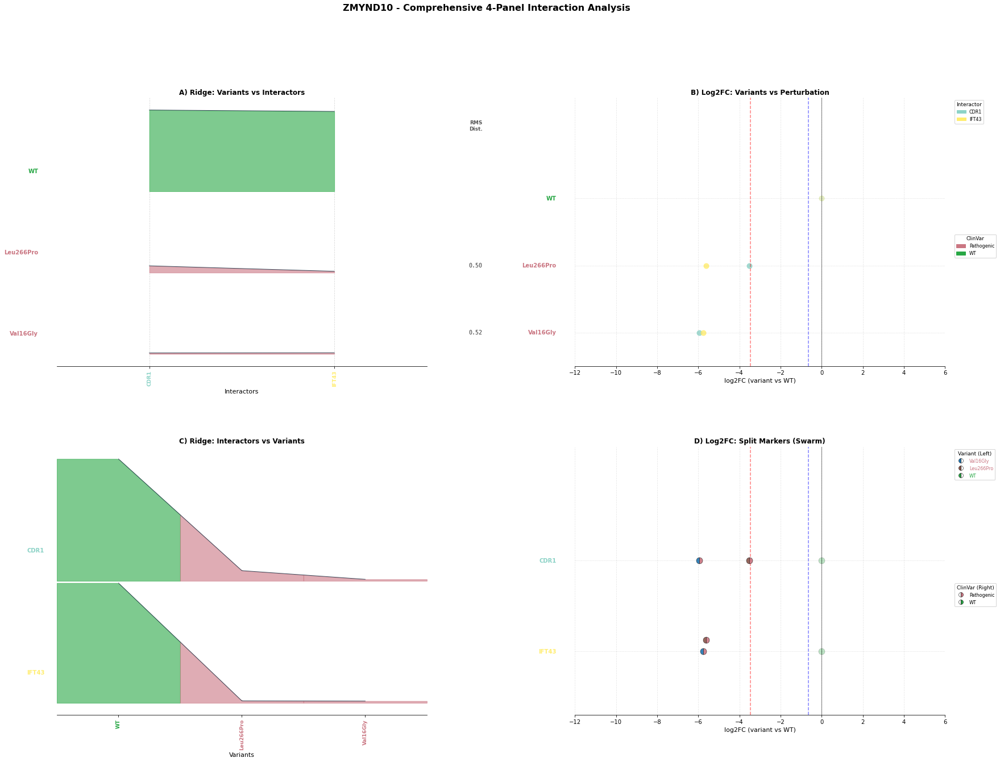

(<Figure size 2016x1440 with 4 Axes>, None)

In [17]:

# ==========================================
# Usage
# ==========================================

plot_all_four_orientations(
    edge_df=edge_df,
    db_symbol='ZMYND10',
    palette_dict=palette_dict,
    orf_distances=orf_distances
)



In [12]:
def plot_all_genes_four_panels(edge_df, clnsig_column='clinvar_clnsig_clean',
                               palette_dict=None, output_dir=None, file_format='pdf', **kwargs):
    """
    Generate 4-panel plots for all genes in edge_df.
    
    Parameters:
    -----------
    edge_df : pd.DataFrame
        DataFrame with edge data
    clnsig_column : str
        Column name for ClinVar classification
    palette_dict : dict, optional
        Color palette for ClinVar categories
    output_dir : str, optional
        Directory to save plots
    file_format : str
        File format for saving ('pdf' or 'png', default: 'pdf')
    **kwargs : additional arguments passed to plot_all_four_orientations
    
    Returns:
    --------
    dict : Dictionary of {gene: (fig, axes)} for all generated plots
    """
    
    # Create output directory if specified
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
    
    genes = sorted(edge_df['symbol'].unique())
    print(f"Found {len(genes)} unique genes")
    
    results = {}
    skipped = []
    
    for gene in genes:
        print(f"\n{'='*60}")
        print(f"Processing: {gene}")
        print(f"{'='*60}")
        
        save_path = None
        if output_dir:
            save_path = os.path.join(output_dir, f"{gene}_four_panels.{file_format}")
        
        fig, axes = plot_all_four_orientations(
            edge_df=edge_df,
            db_symbol=gene,
            clnsig_column=clnsig_column,
            palette_dict=palette_dict,
            save_path=save_path,
            orf_distances=orf_distances,
            **kwargs
        )
        
        if fig is not None:
            results[gene] = (fig, axes)
        else:
            skipped.append(gene)
    
    print(f"\n{'='*60}")
    print(f"Completed: {len(results)} four-panel plots generated as {file_format.upper()}")
    if skipped:
        print(f"Skipped {len(skipped)} genes (single interactor or other issues): {', '.join(skipped)}")
    print(f"{'='*60}")
    
    return results



Found 75 unique genes

Processing: ACSF3
Creating 4-panel plot for ACSF3


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/ACSF3_four_panels.pdf


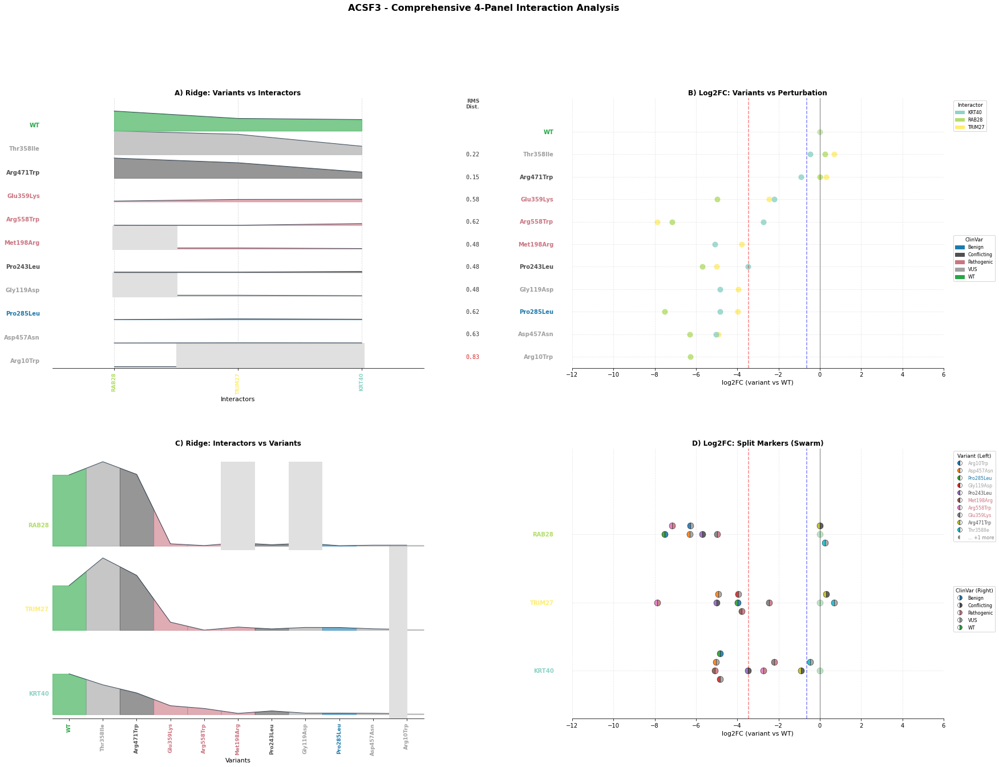


Processing: AGXT
Creating 4-panel plot for AGXT
Saved: ../3_outputs/sqY2H/four_panel_plots/AGXT_four_panels.pdf


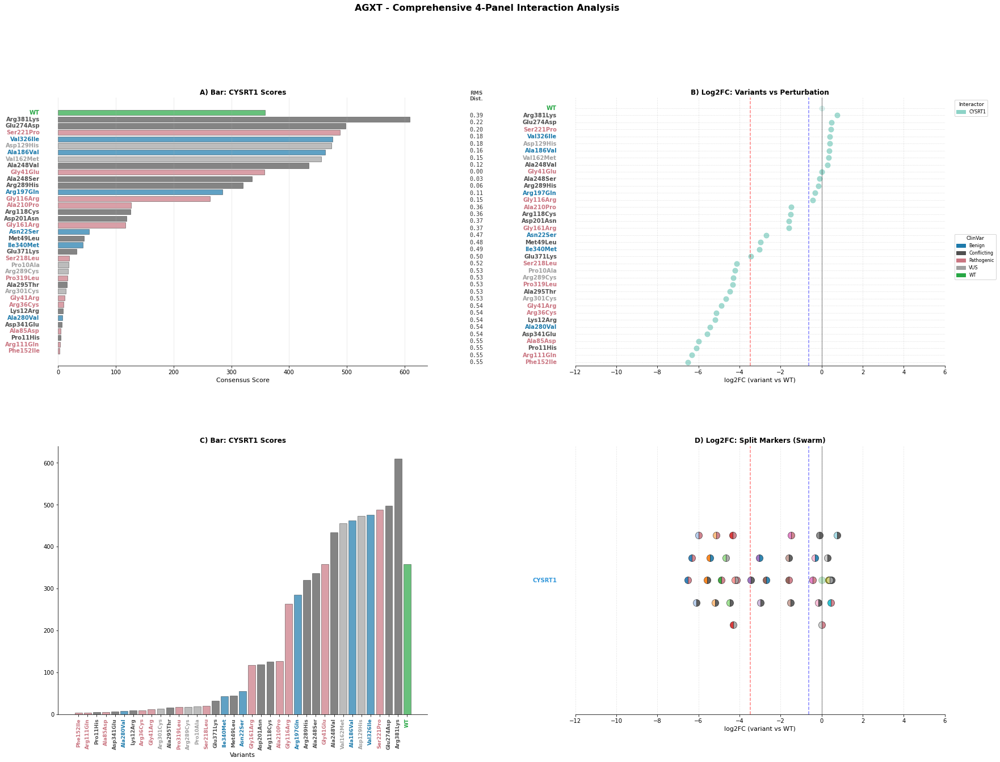


Processing: AIPL1
Creating 4-panel plot for AIPL1
Saved: ../3_outputs/sqY2H/four_panel_plots/AIPL1_four_panels.pdf


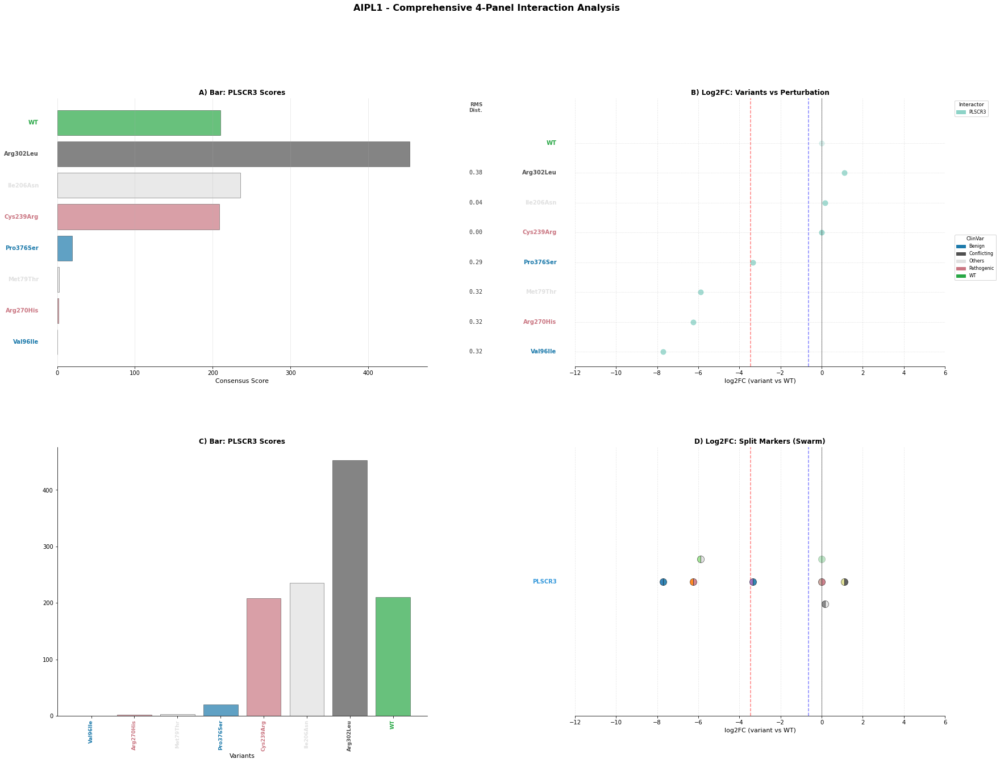


Processing: ALAS2
Creating 4-panel plot for ALAS2
Saved: ../3_outputs/sqY2H/four_panel_plots/ALAS2_four_panels.pdf


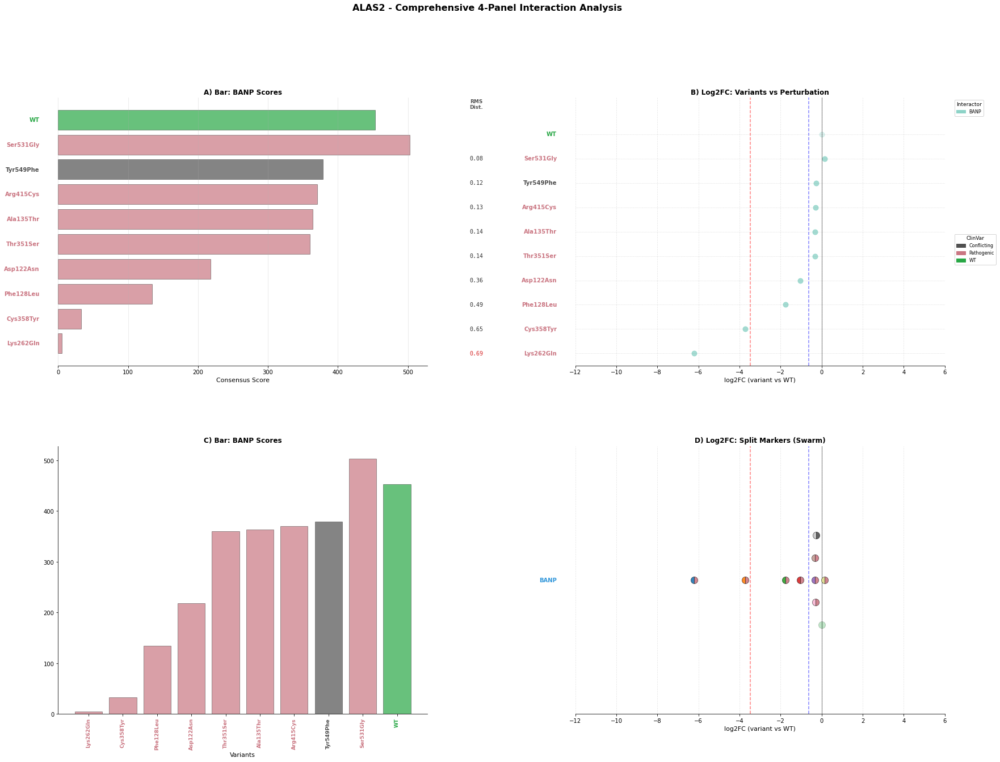


Processing: AP2S1
Creating 4-panel plot for AP2S1
Saved: ../3_outputs/sqY2H/four_panel_plots/AP2S1_four_panels.pdf


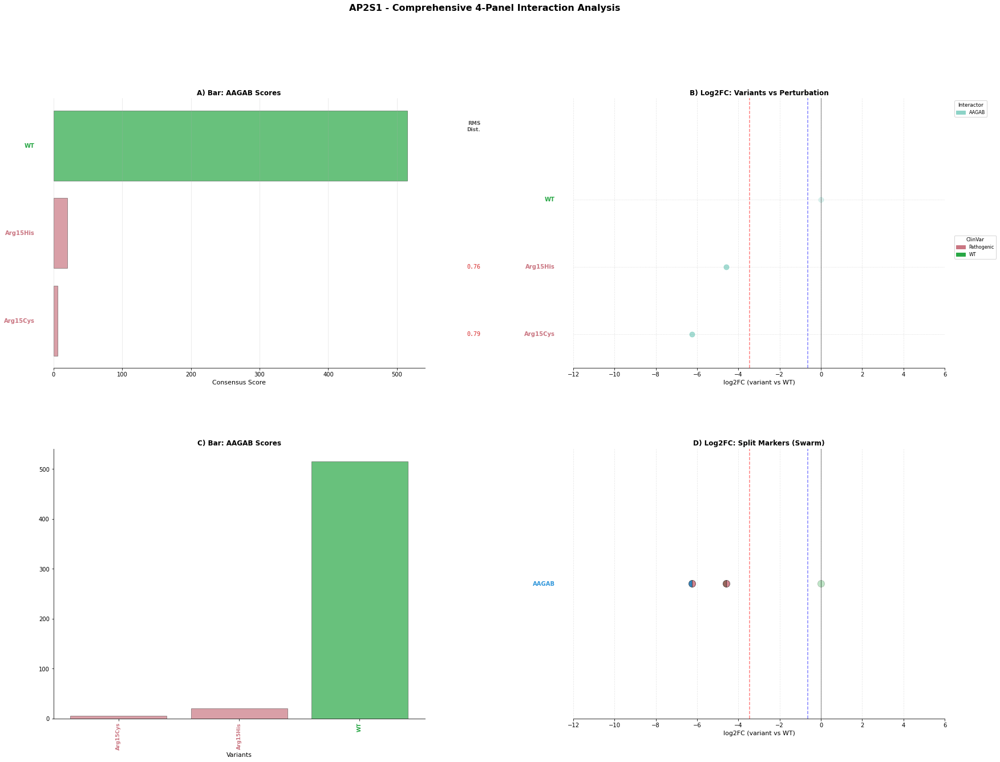


Processing: ASNS
Creating 4-panel plot for ASNS
Saved: ../3_outputs/sqY2H/four_panel_plots/ASNS_four_panels.pdf


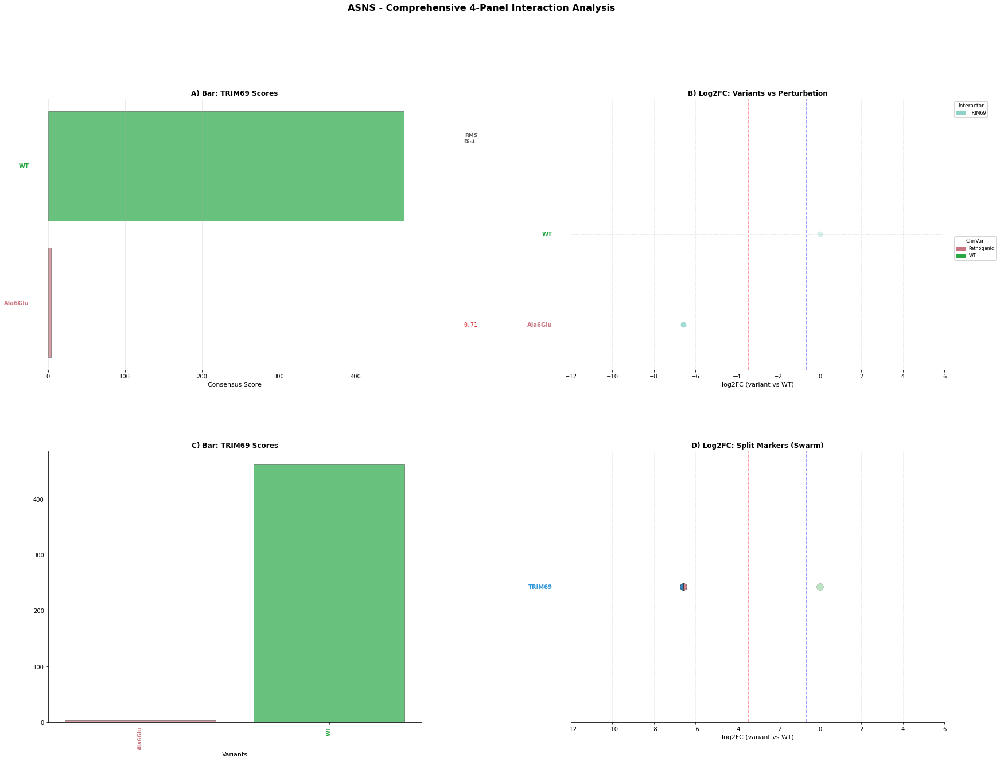


Processing: BAG3
Creating 4-panel plot for BAG3


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/BAG3_four_panels.pdf


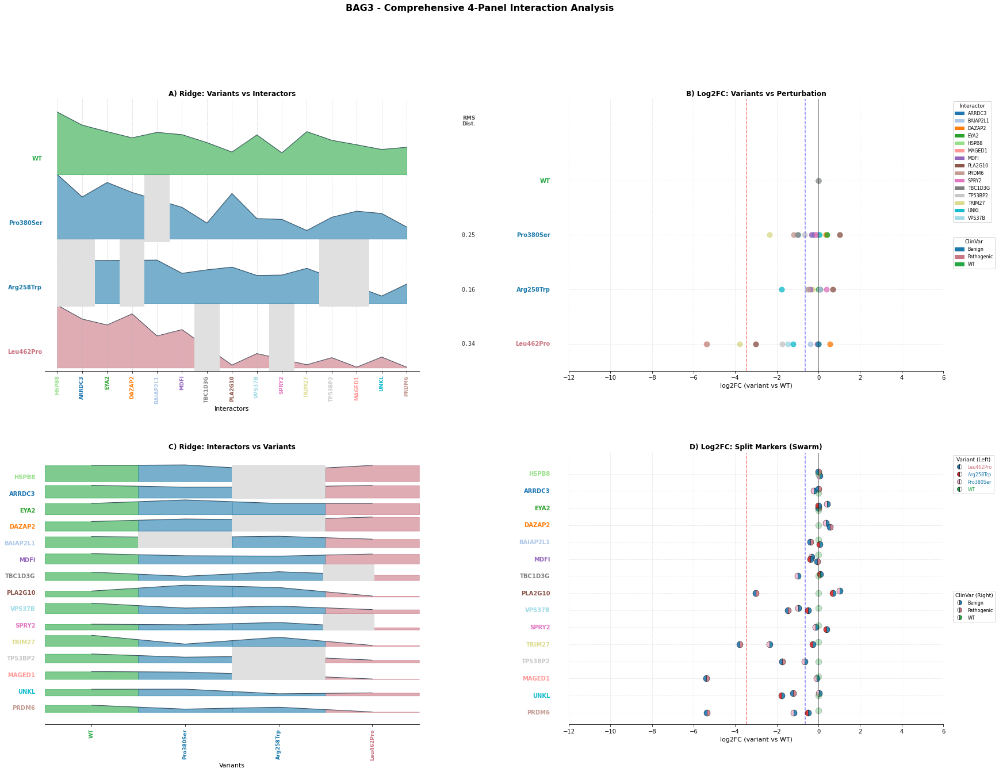


Processing: CHN1
Creating 4-panel plot for CHN1
Saved: ../3_outputs/sqY2H/four_panel_plots/CHN1_four_panels.pdf


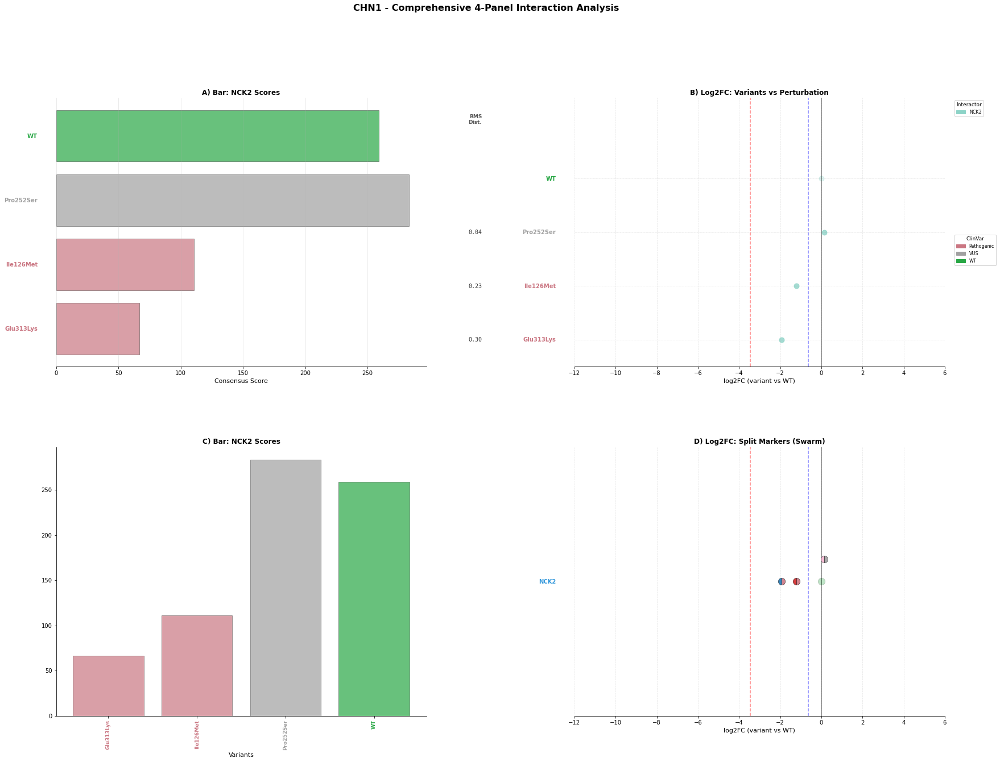


Processing: CLN6
Creating 4-panel plot for CLN6
Saved: ../3_outputs/sqY2H/four_panel_plots/CLN6_four_panels.pdf


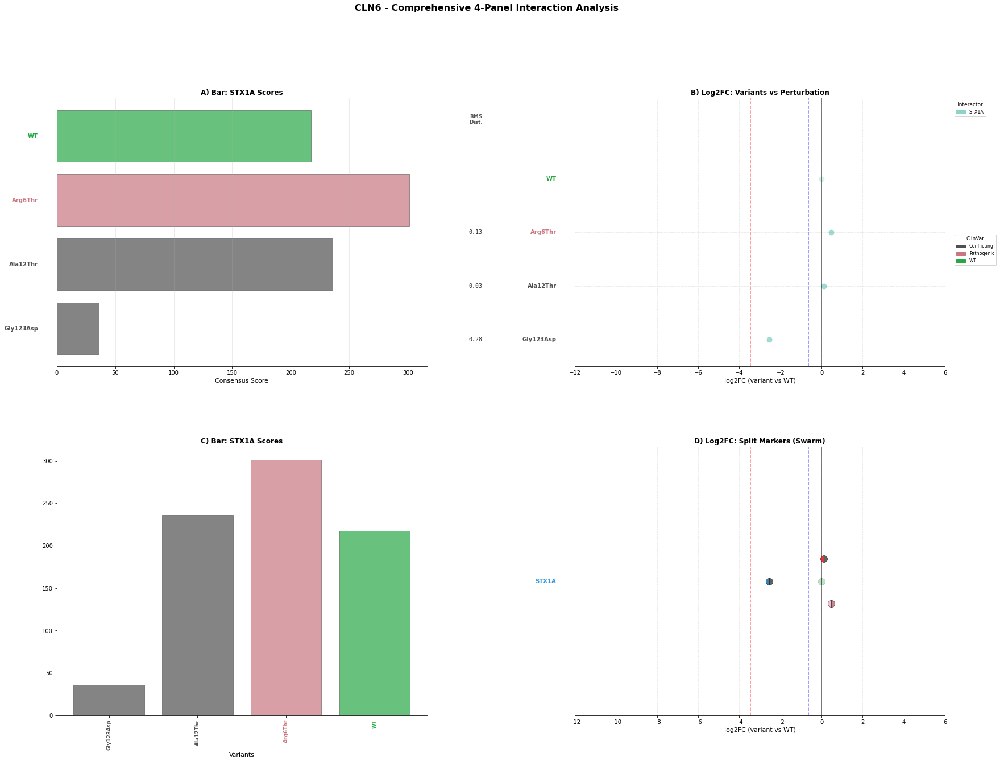


Processing: COL2A1
Creating 4-panel plot for COL2A1
Saved: ../3_outputs/sqY2H/four_panel_plots/COL2A1_four_panels.pdf


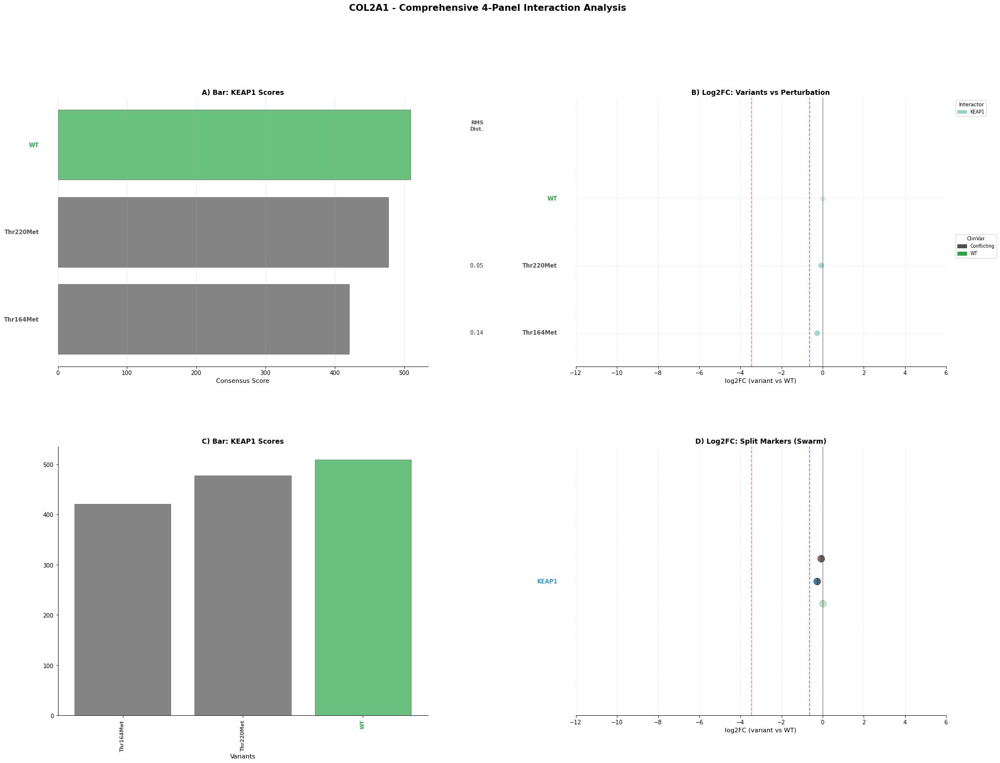


Processing: COQ8A
Creating 4-panel plot for COQ8A


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/COQ8A_four_panels.pdf


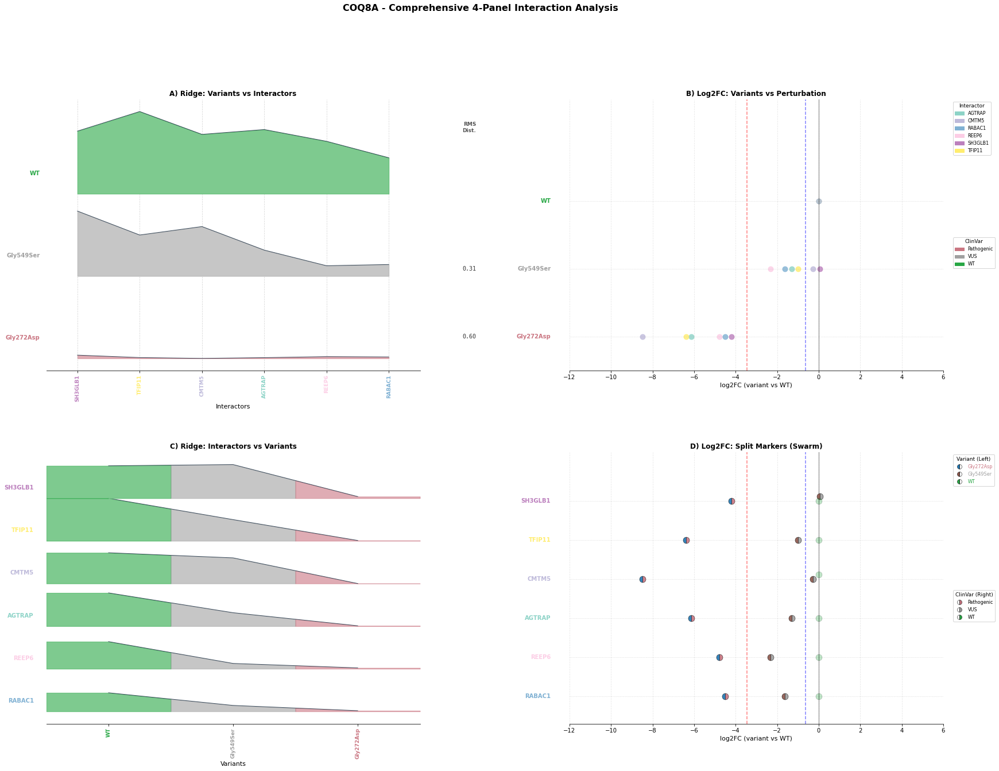


Processing: CRYAB
Creating 4-panel plot for CRYAB
Saved: ../3_outputs/sqY2H/four_panel_plots/CRYAB_four_panels.pdf


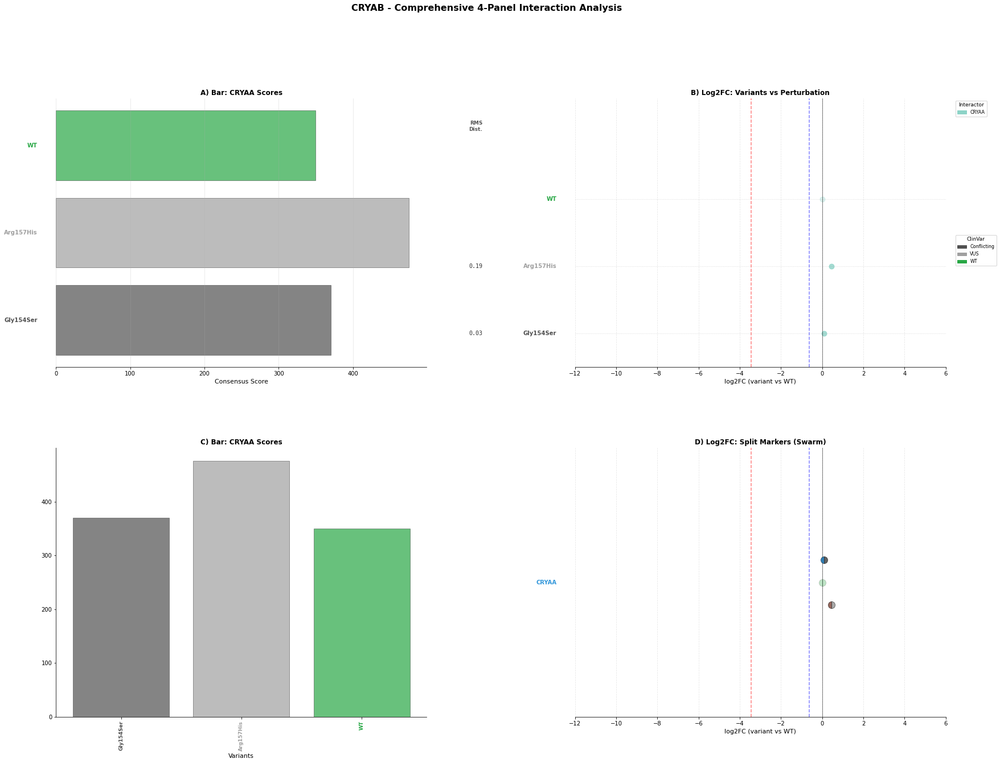


Processing: EMD
Creating 4-panel plot for EMD


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/EMD_four_panels.pdf


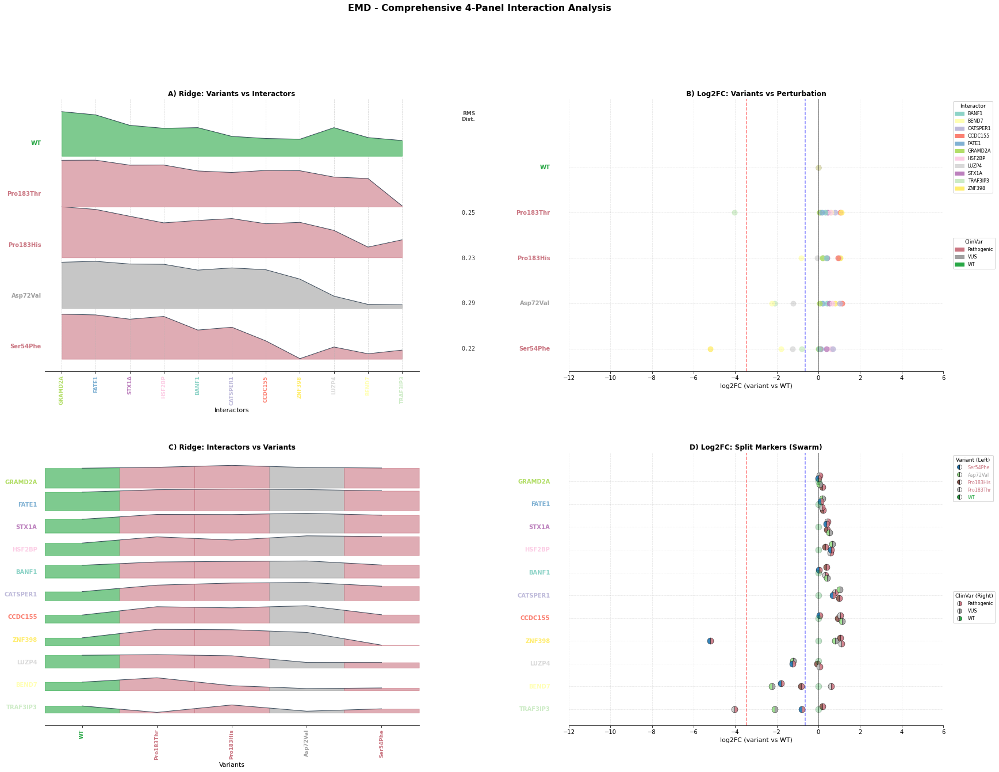


Processing: EZH2
Creating 4-panel plot for EZH2
Saved: ../3_outputs/sqY2H/four_panel_plots/EZH2_four_panels.pdf


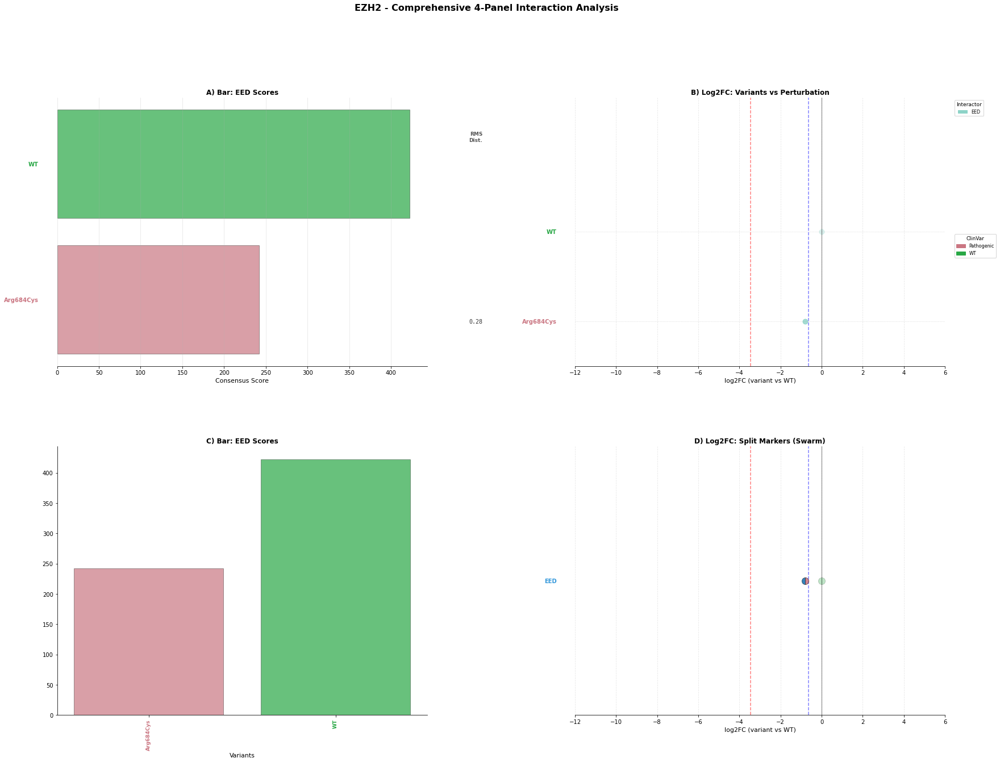


Processing: FA2H
Creating 4-panel plot for FA2H
Saved: ../3_outputs/sqY2H/four_panel_plots/FA2H_four_panels.pdf


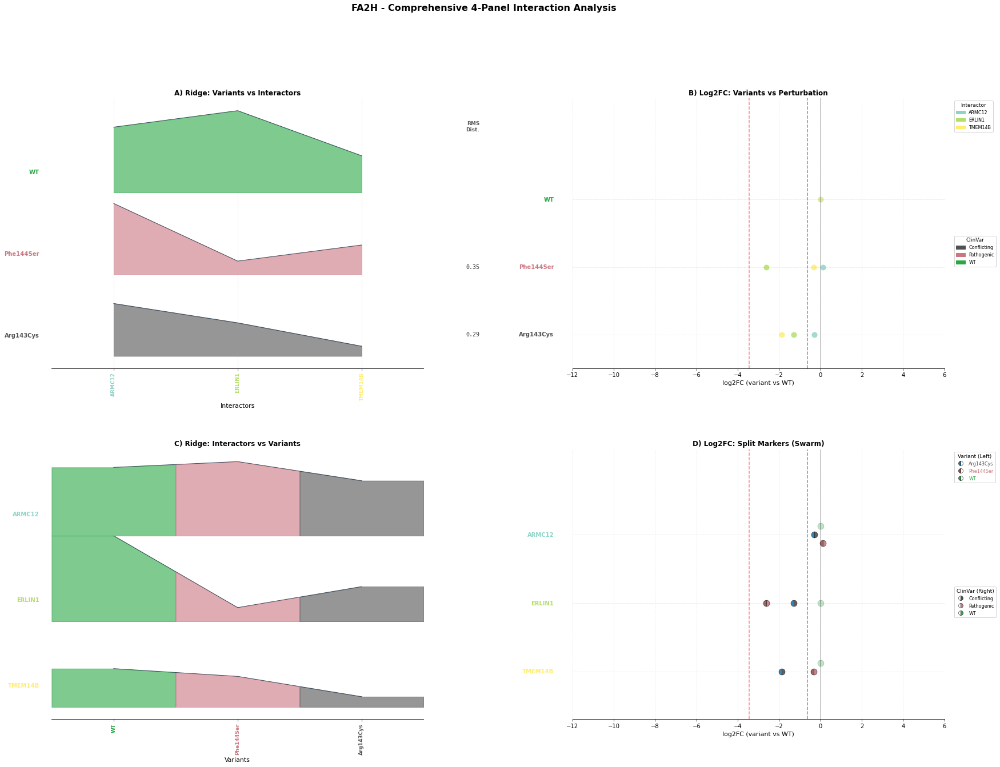


Processing: FBP1
Creating 4-panel plot for FBP1
Saved: ../3_outputs/sqY2H/four_panel_plots/FBP1_four_panels.pdf


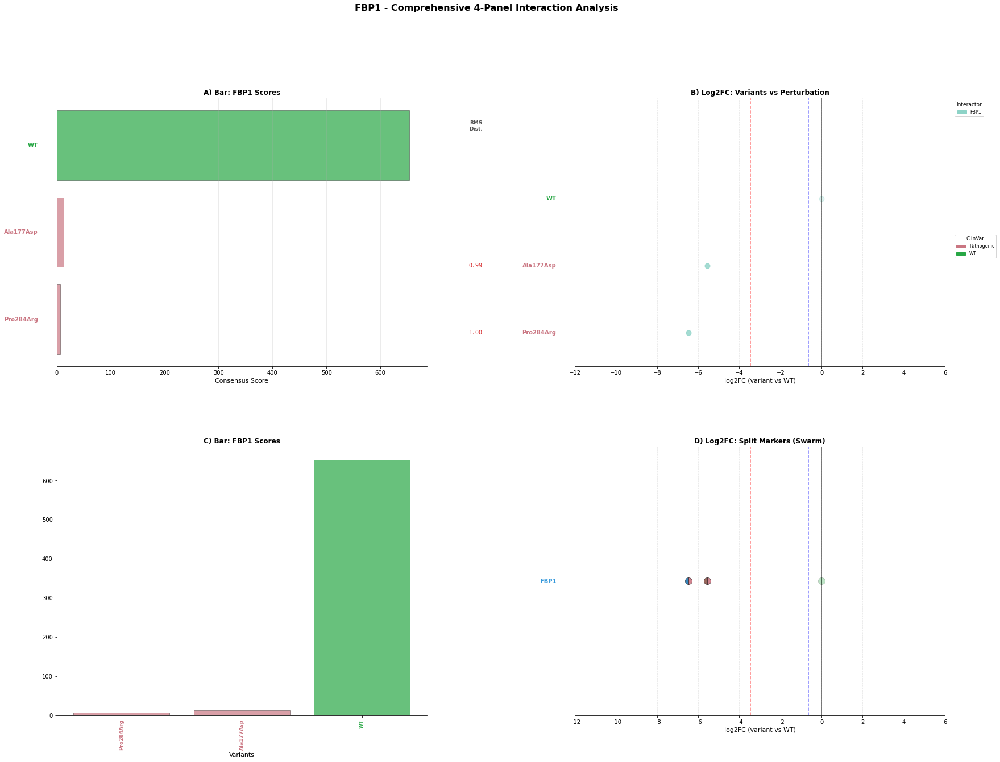


Processing: GALE
Creating 4-panel plot for GALE
Saved: ../3_outputs/sqY2H/four_panel_plots/GALE_four_panels.pdf


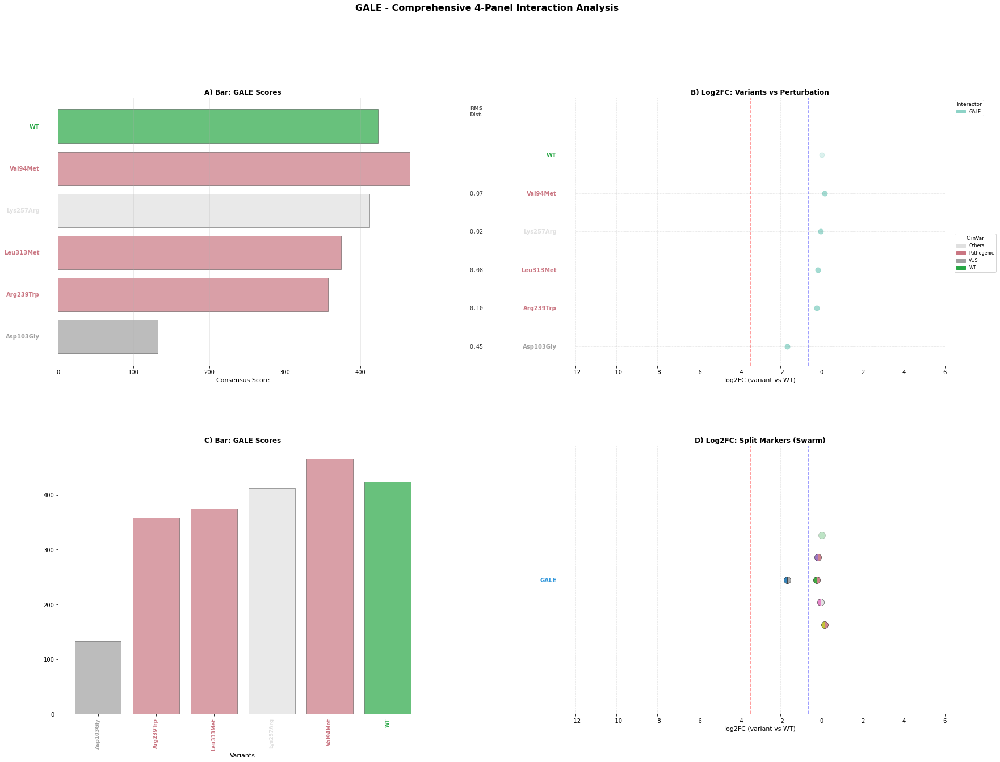


Processing: GCK
Creating 4-panel plot for GCK
Saved: ../3_outputs/sqY2H/four_panel_plots/GCK_four_panels.pdf


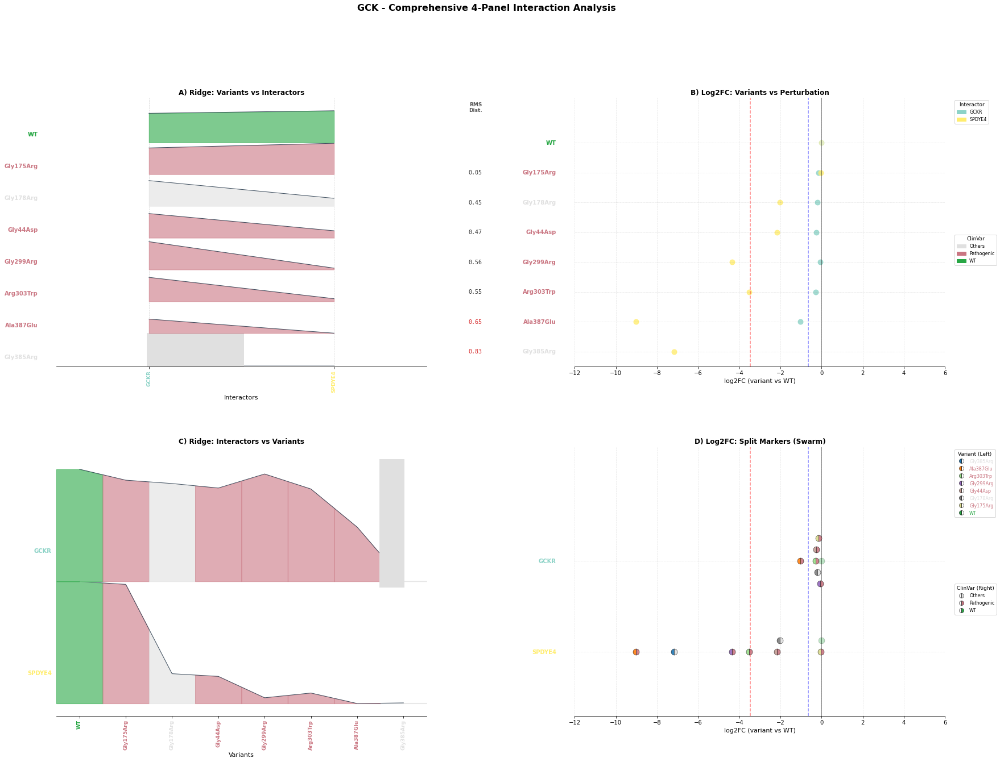


Processing: GFAP
Creating 4-panel plot for GFAP


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/GFAP_four_panels.pdf


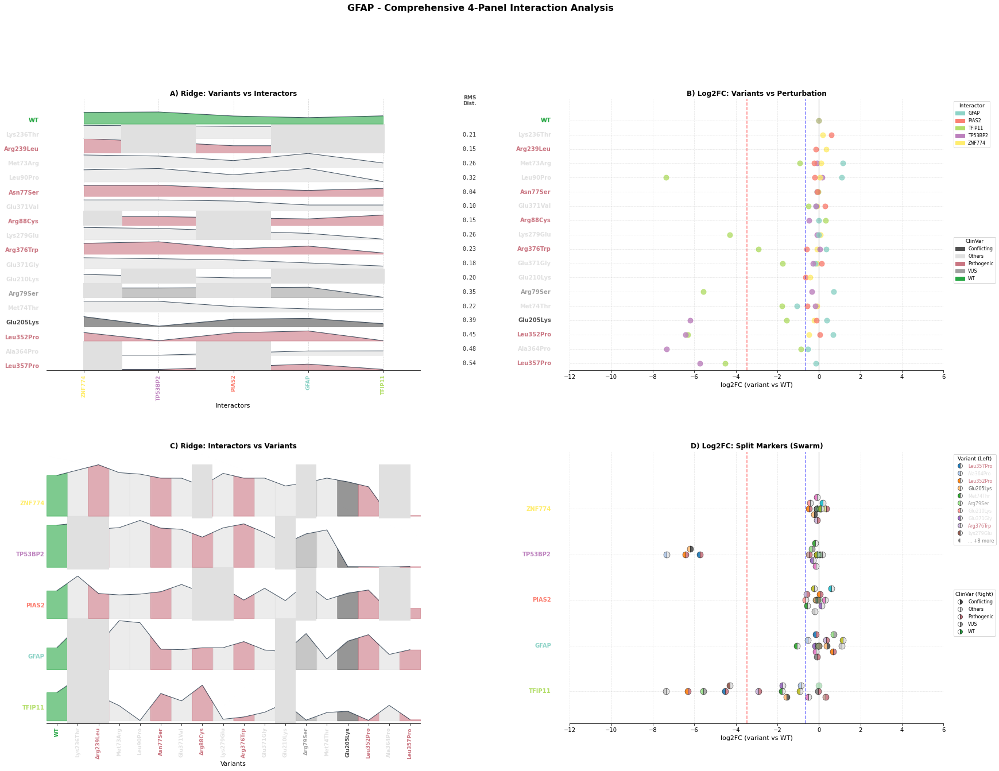


Processing: GMPPB
Creating 4-panel plot for GMPPB
Saved: ../3_outputs/sqY2H/four_panel_plots/GMPPB_four_panels.pdf


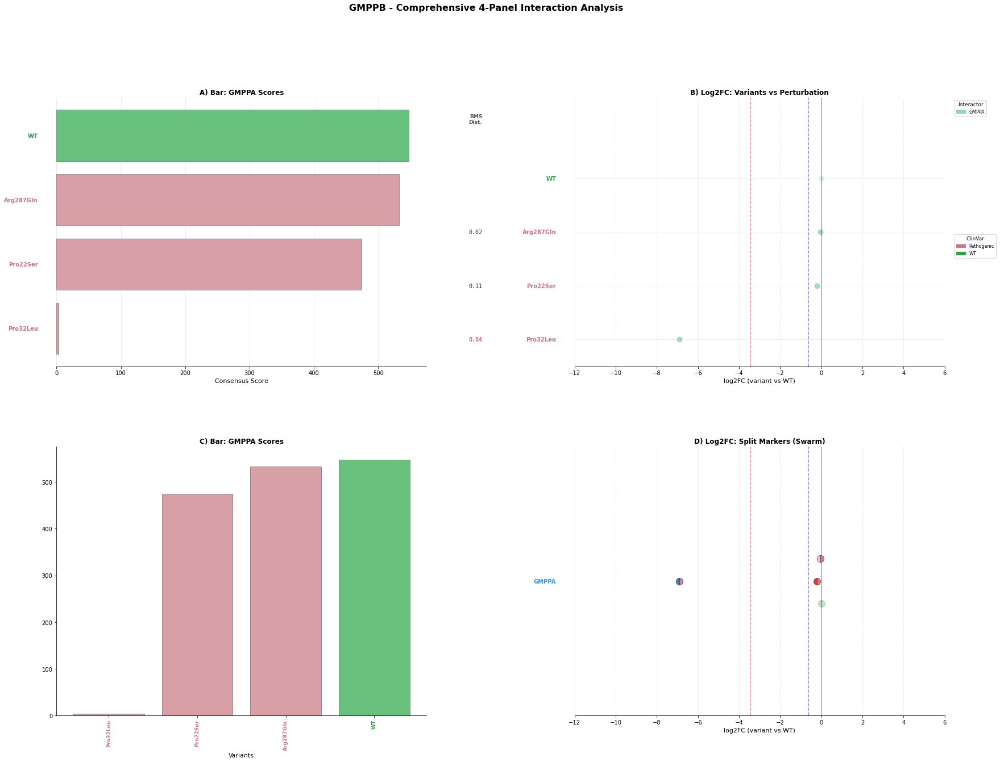


Processing: GRN
Creating 4-panel plot for GRN


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/GRN_four_panels.pdf


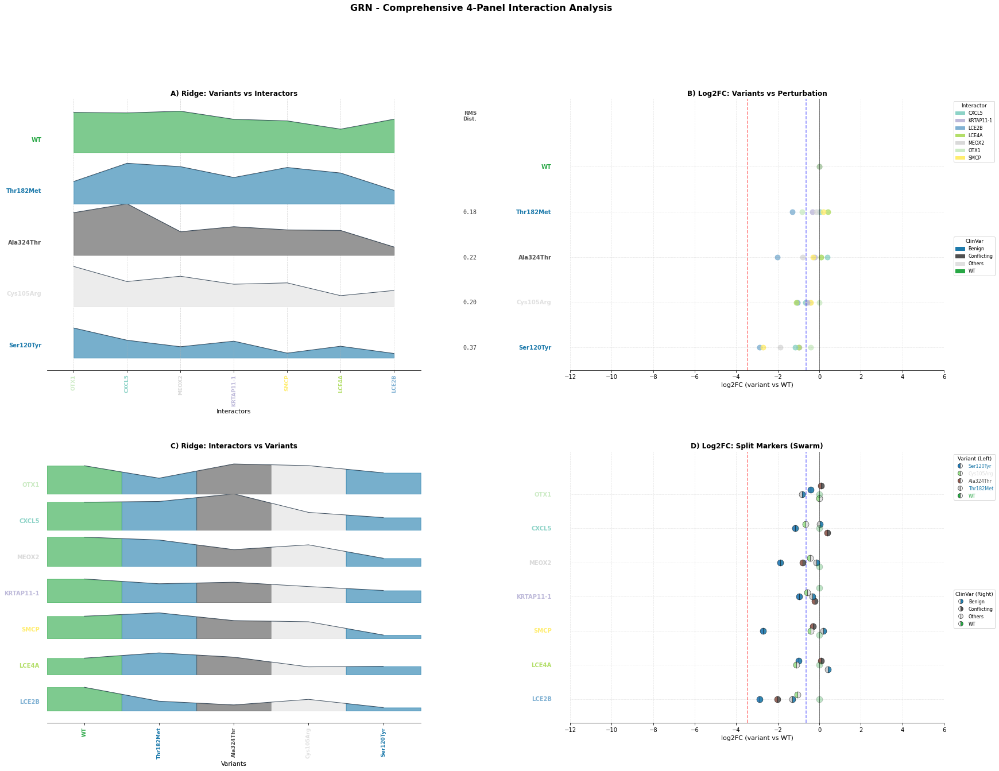


Processing: GSS
Creating 4-panel plot for GSS
Saved: ../3_outputs/sqY2H/four_panel_plots/GSS_four_panels.pdf


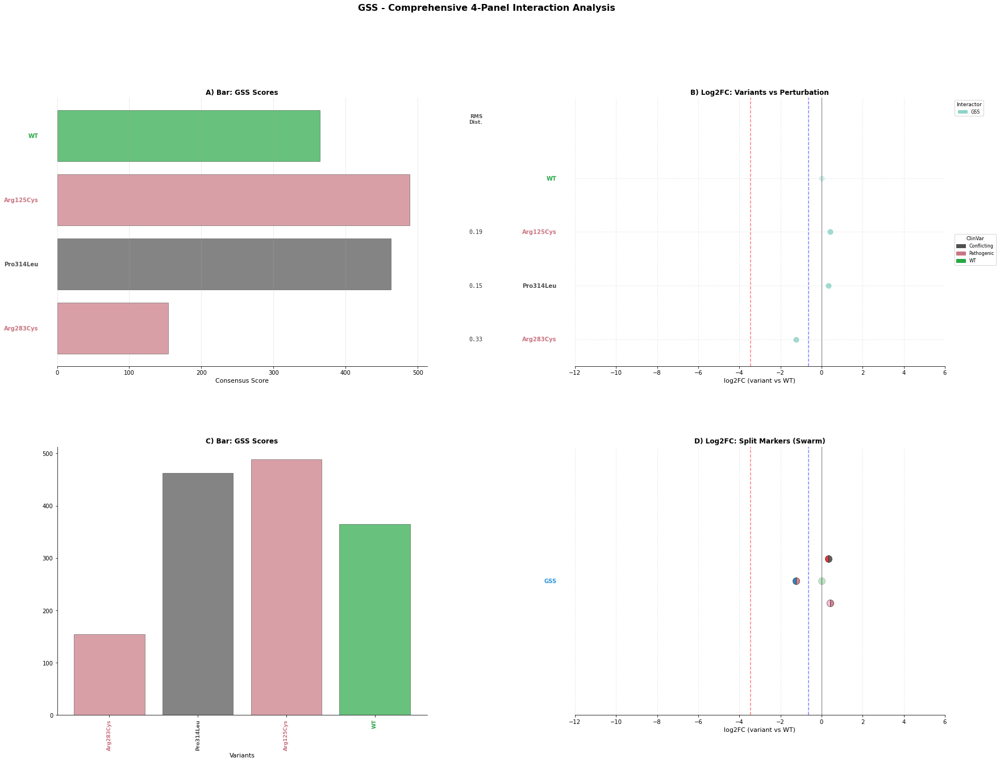


Processing: HBD
Creating 4-panel plot for HBD
Saved: ../3_outputs/sqY2H/four_panel_plots/HBD_four_panels.pdf


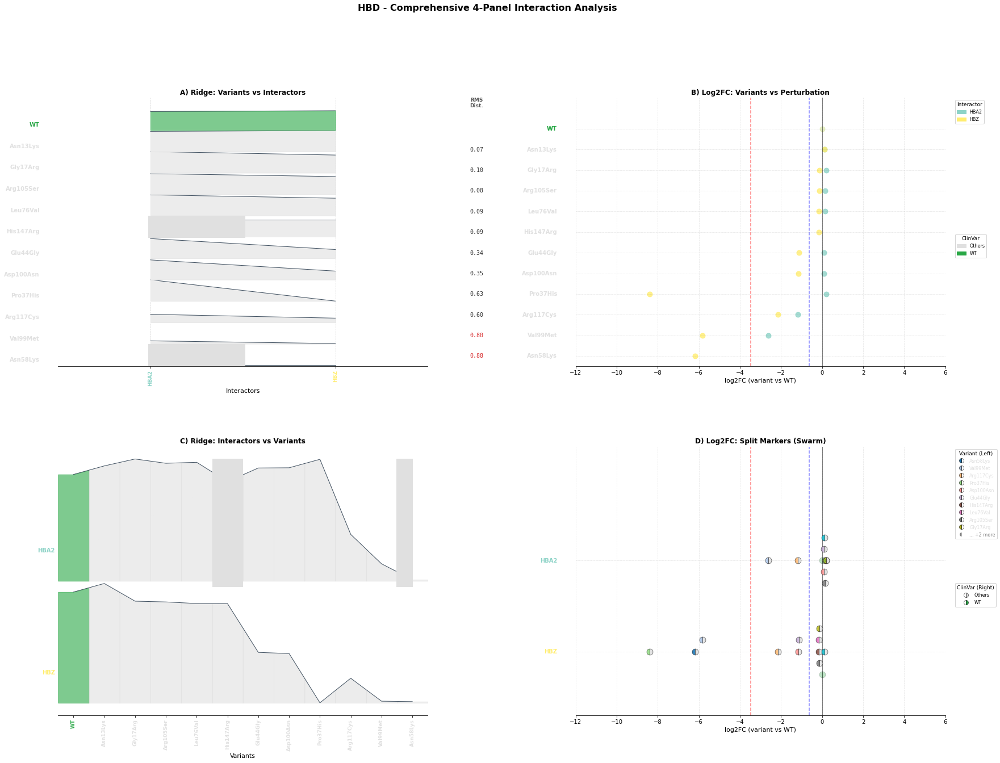


Processing: HGD
Creating 4-panel plot for HGD
Saved: ../3_outputs/sqY2H/four_panel_plots/HGD_four_panels.pdf


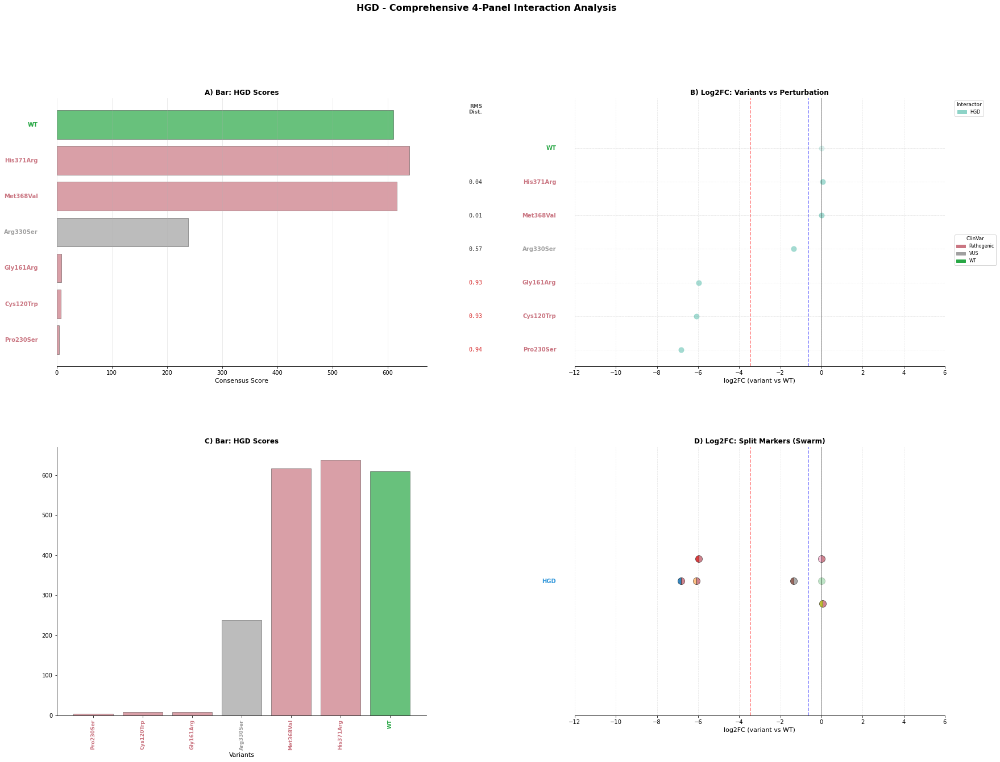


Processing: HMBS
Creating 4-panel plot for HMBS
Saved: ../3_outputs/sqY2H/four_panel_plots/HMBS_four_panels.pdf


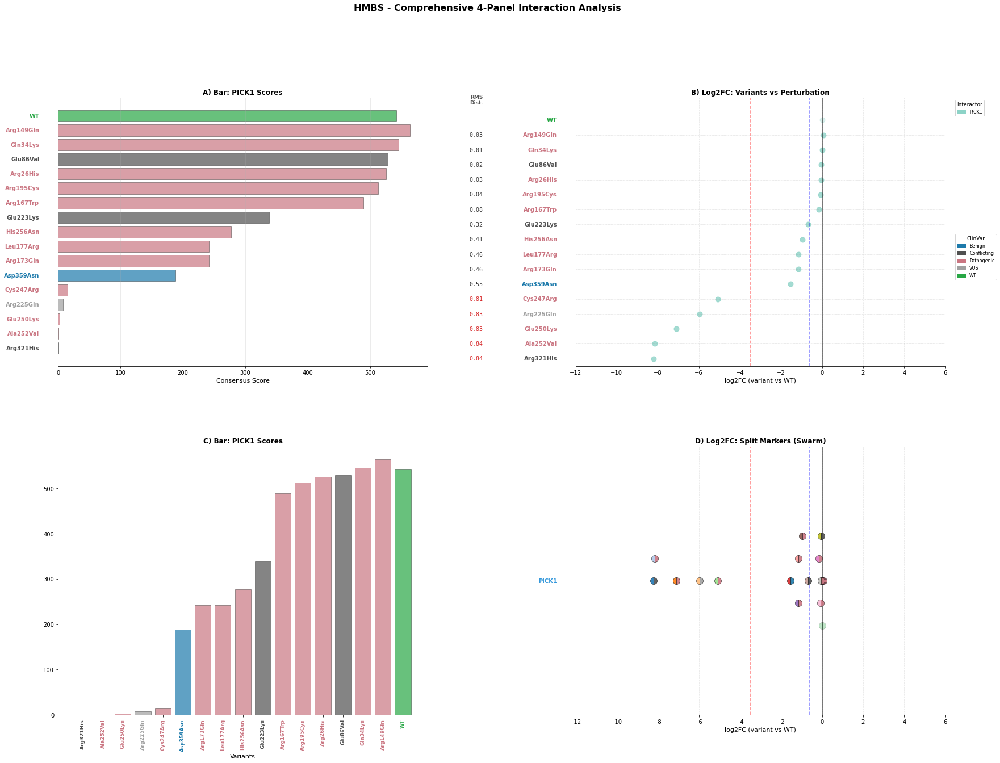


Processing: HPRT1
Creating 4-panel plot for HPRT1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/HPRT1_four_panels.pdf


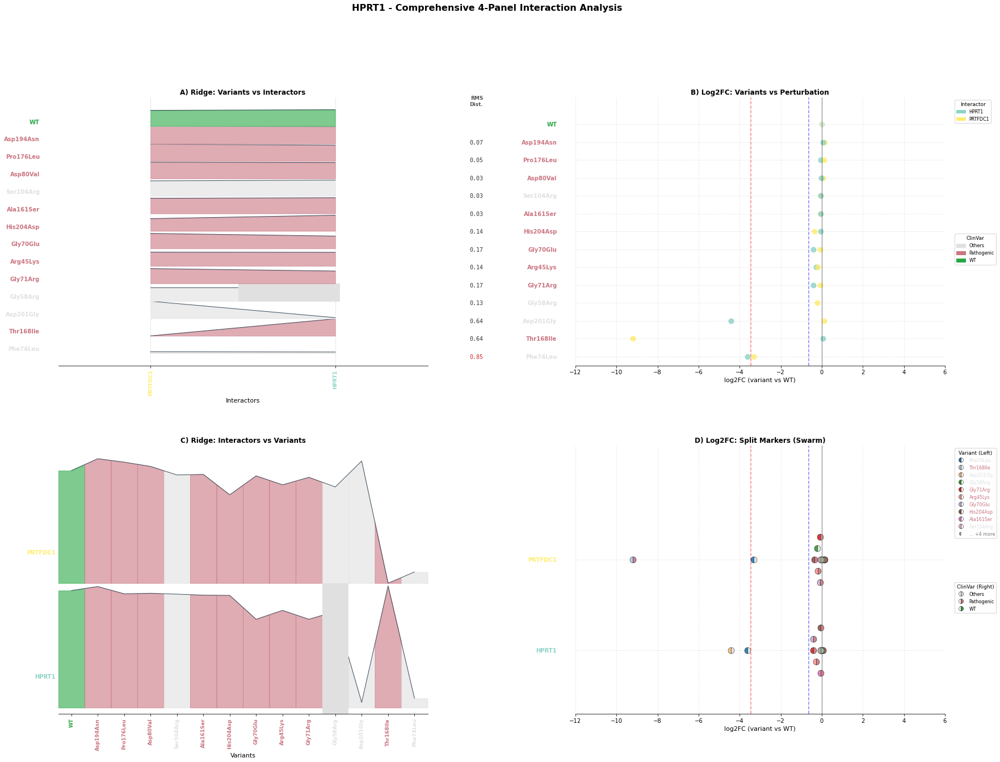


Processing: IER3IP1
Creating 4-panel plot for IER3IP1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/IER3IP1_four_panels.pdf


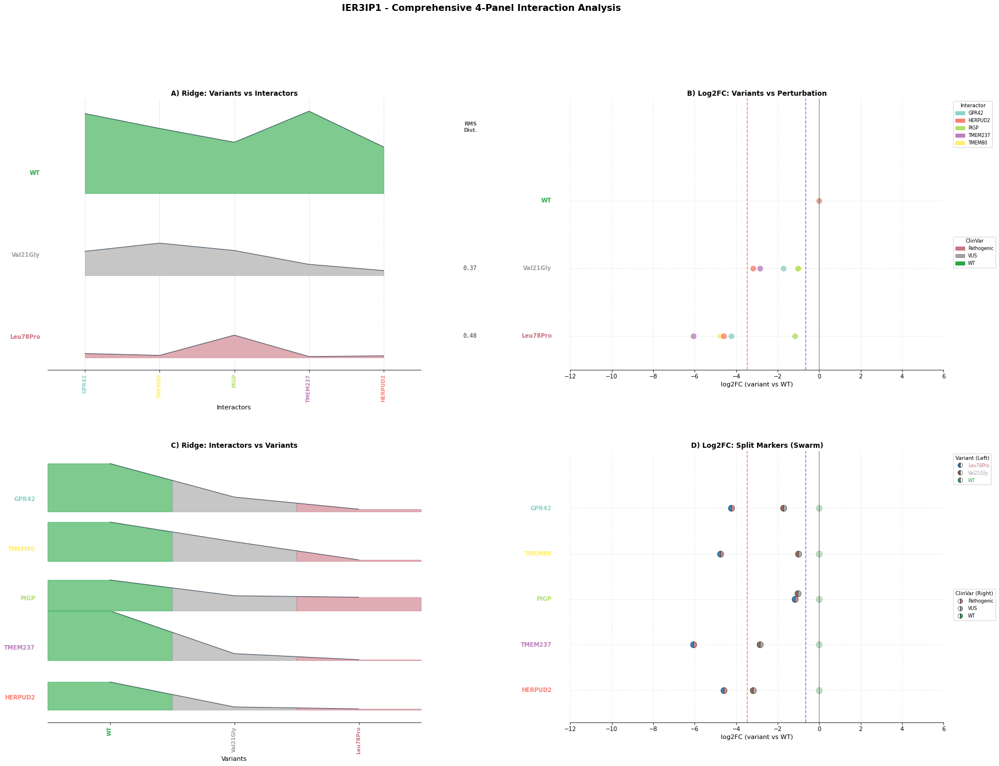


Processing: IL36RN
Creating 4-panel plot for IL36RN
Saved: ../3_outputs/sqY2H/four_panel_plots/IL36RN_four_panels.pdf


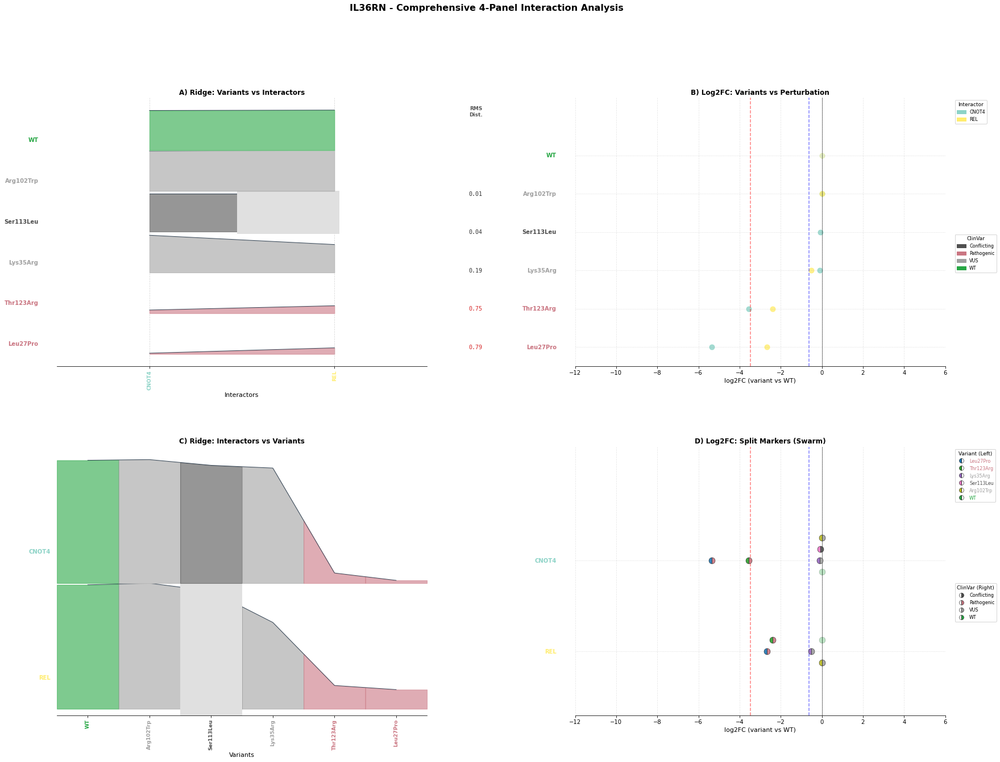


Processing: IMPDH1
Creating 4-panel plot for IMPDH1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/IMPDH1_four_panels.pdf


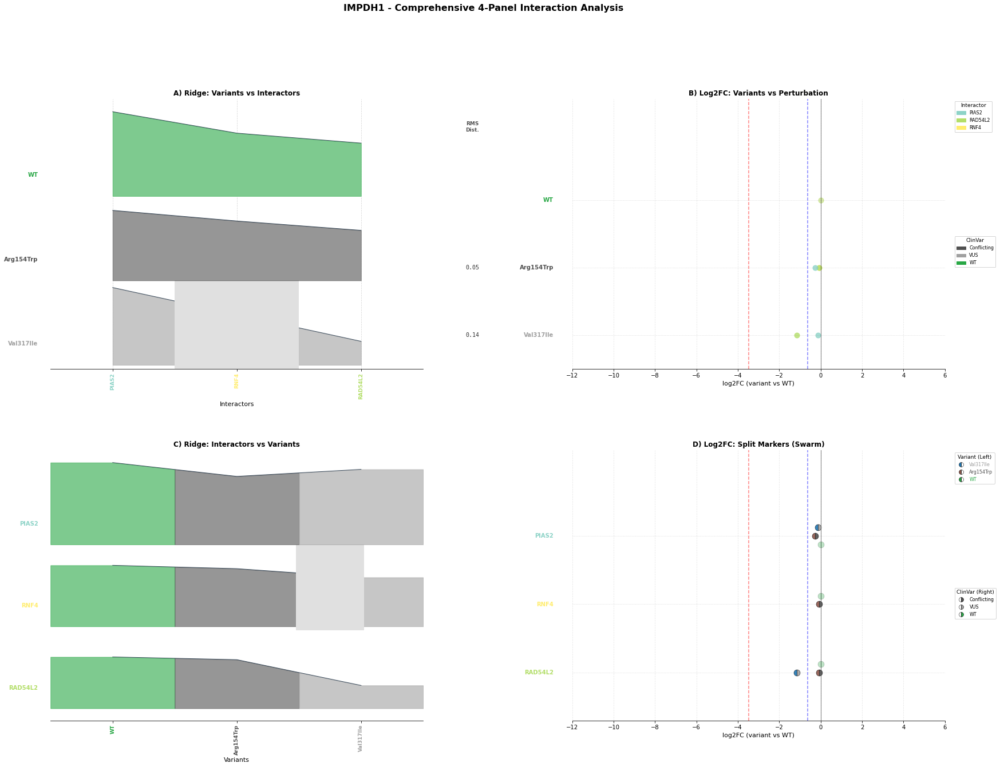


Processing: KCNJ2
Creating 4-panel plot for KCNJ2
Saved: ../3_outputs/sqY2H/four_panel_plots/KCNJ2_four_panels.pdf


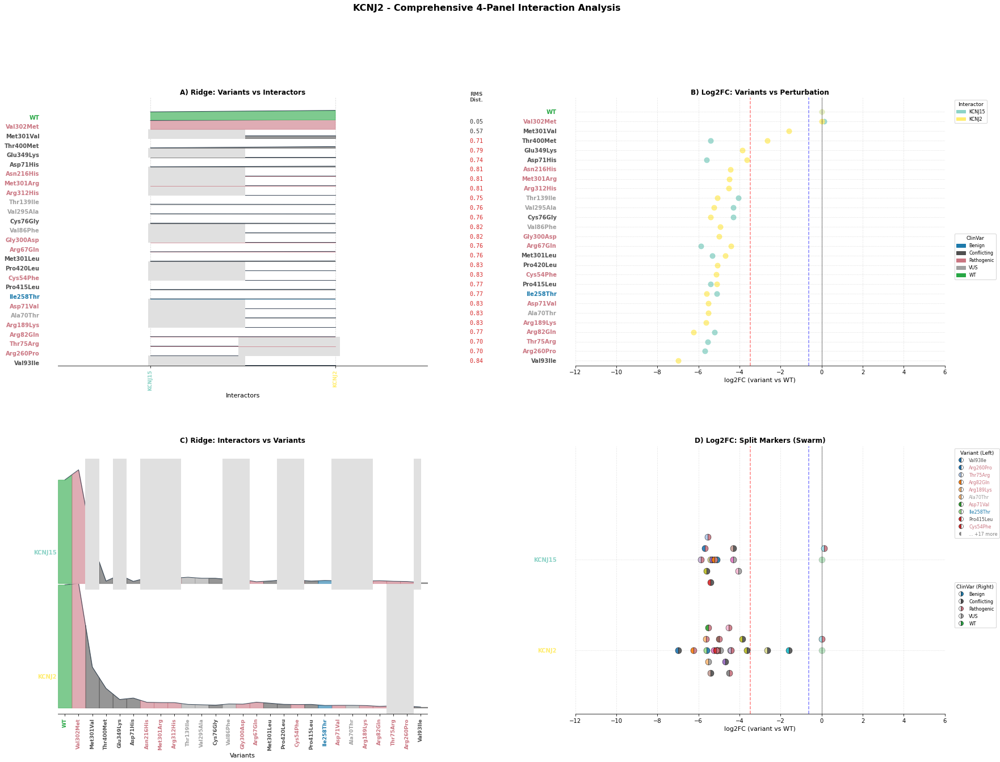


Processing: KCTD1
Creating 4-panel plot for KCTD1
Saved: ../3_outputs/sqY2H/four_panel_plots/KCTD1_four_panels.pdf


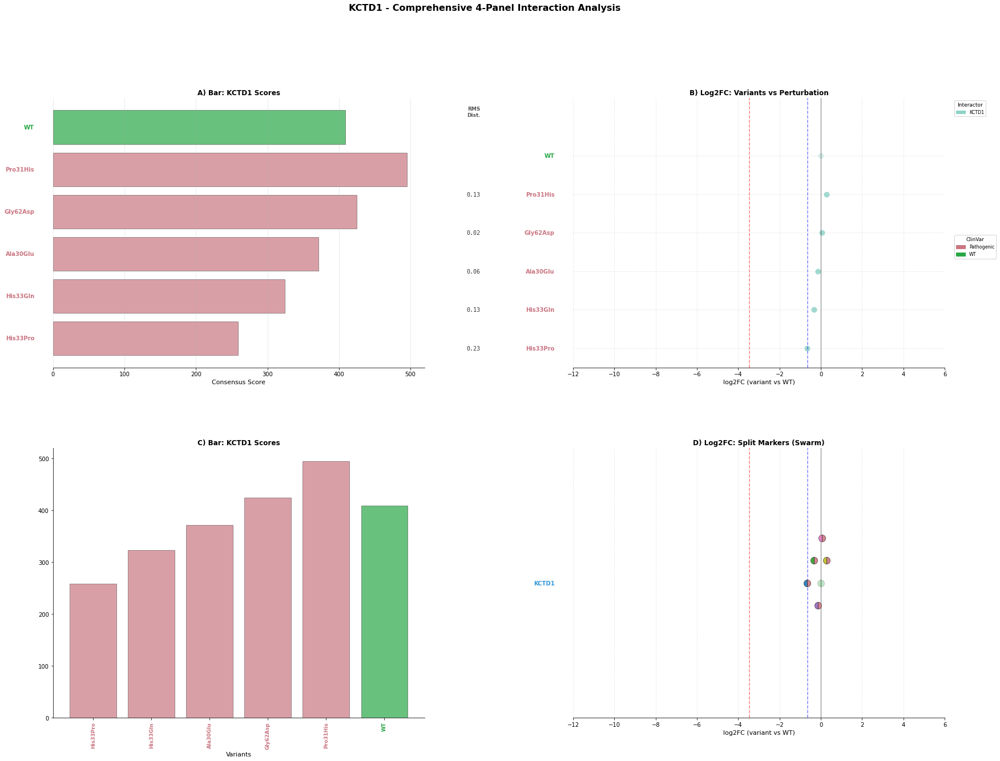


Processing: KCTD7
Creating 4-panel plot for KCTD7


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/KCTD7_four_panels.pdf


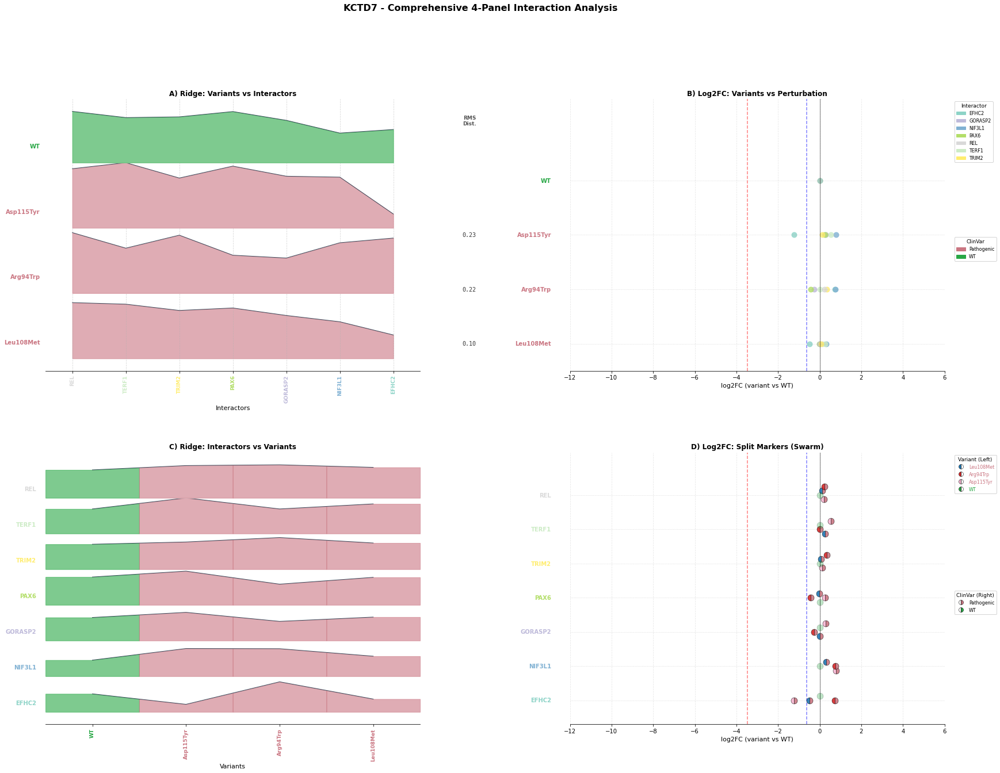


Processing: KLHL3
Creating 4-panel plot for KLHL3
Saved: ../3_outputs/sqY2H/four_panel_plots/KLHL3_four_panels.pdf


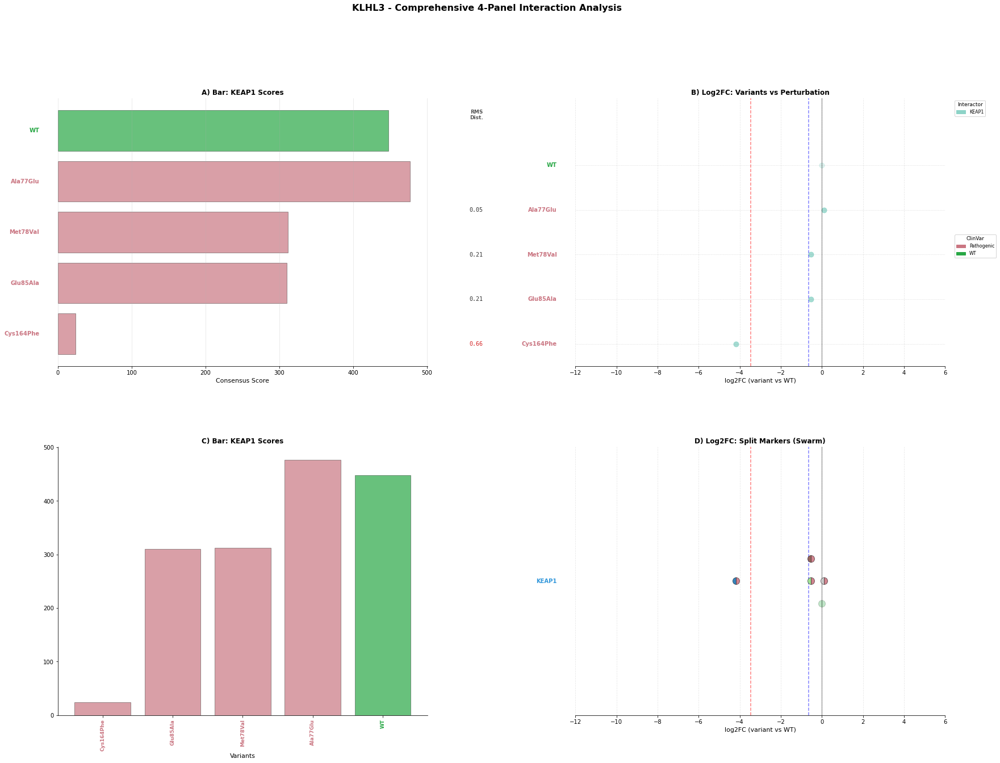


Processing: KRT2
Creating 4-panel plot for KRT2


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/KRT2_four_panels.pdf


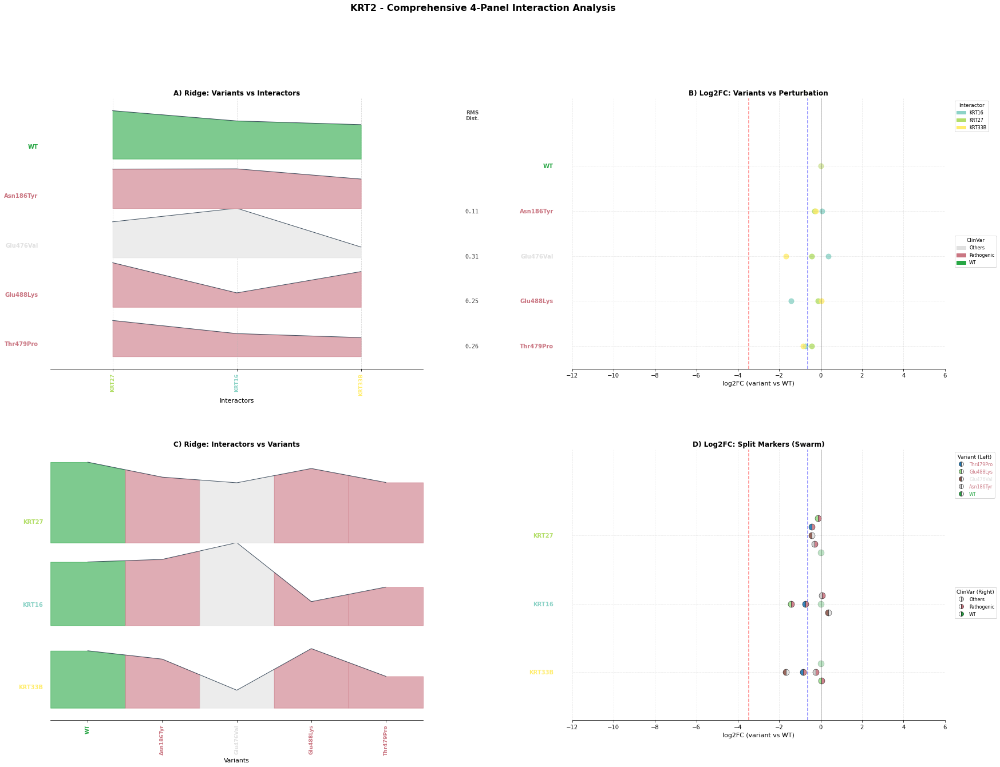


Processing: KRT5
Creating 4-panel plot for KRT5
Saved: ../3_outputs/sqY2H/four_panel_plots/KRT5_four_panels.pdf


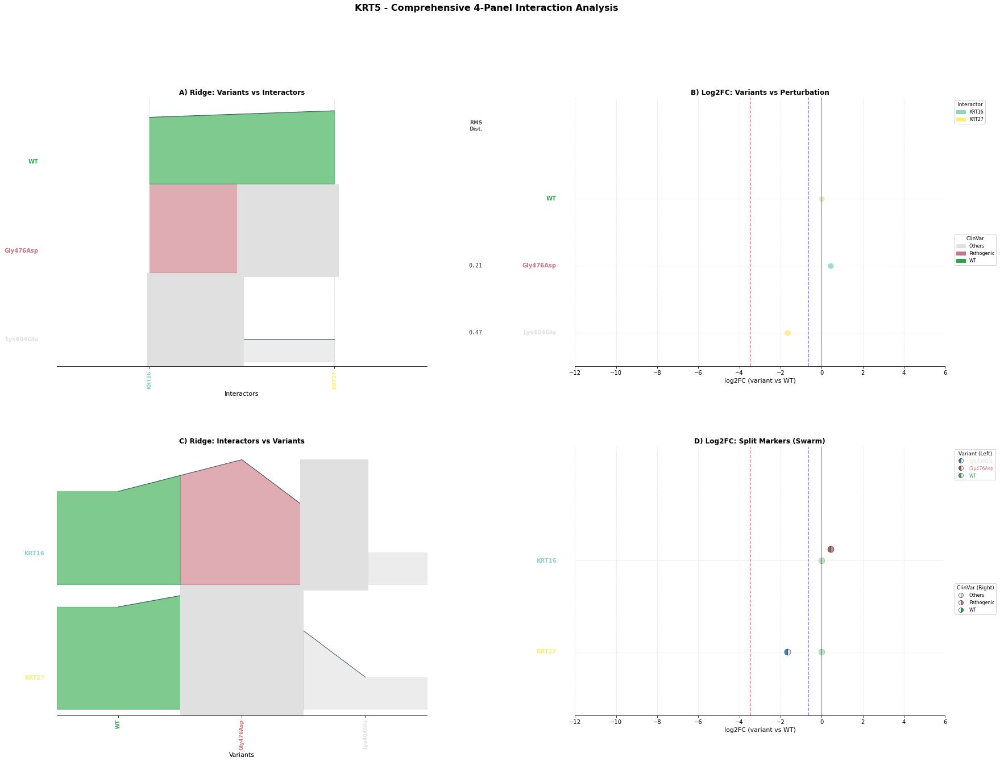


Processing: KRT6A
Creating 4-panel plot for KRT6A


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/KRT6A_four_panels.pdf


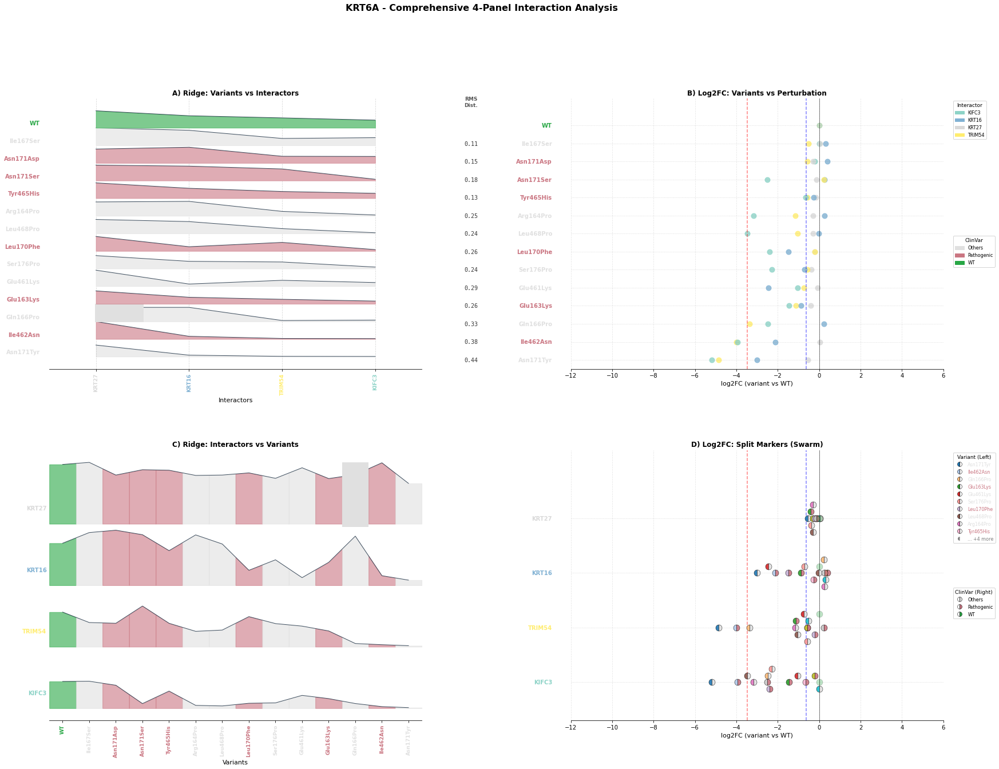


Processing: KRT8
Creating 4-panel plot for KRT8


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/KRT8_four_panels.pdf


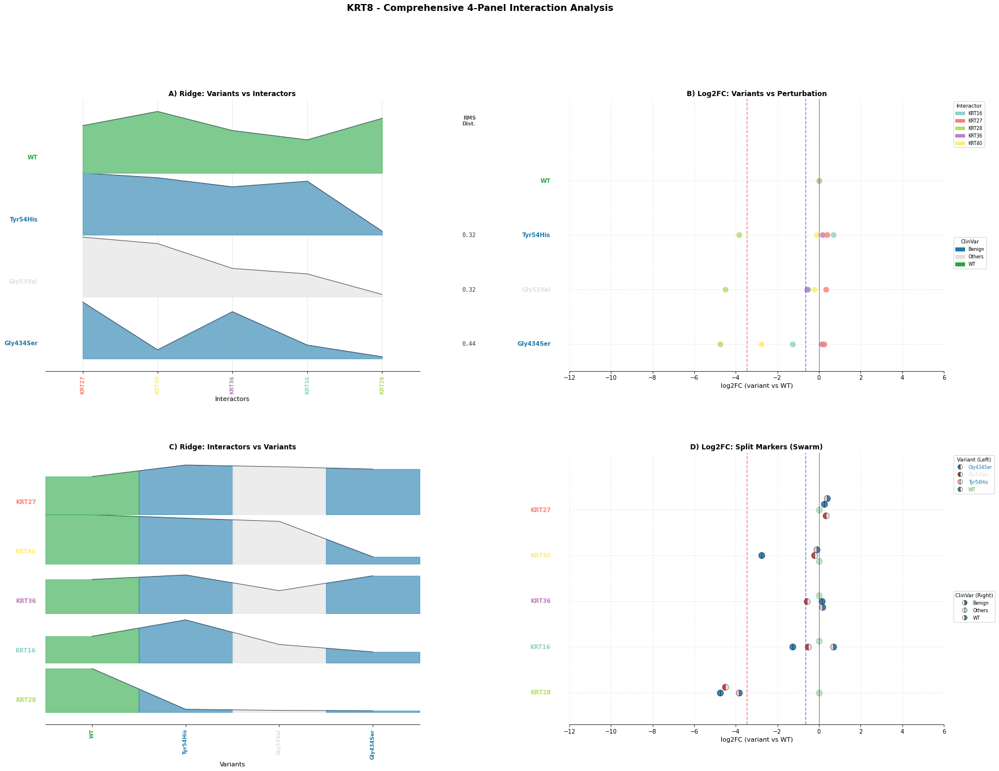


Processing: KRT86
Creating 4-panel plot for KRT86


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/KRT86_four_panels.pdf


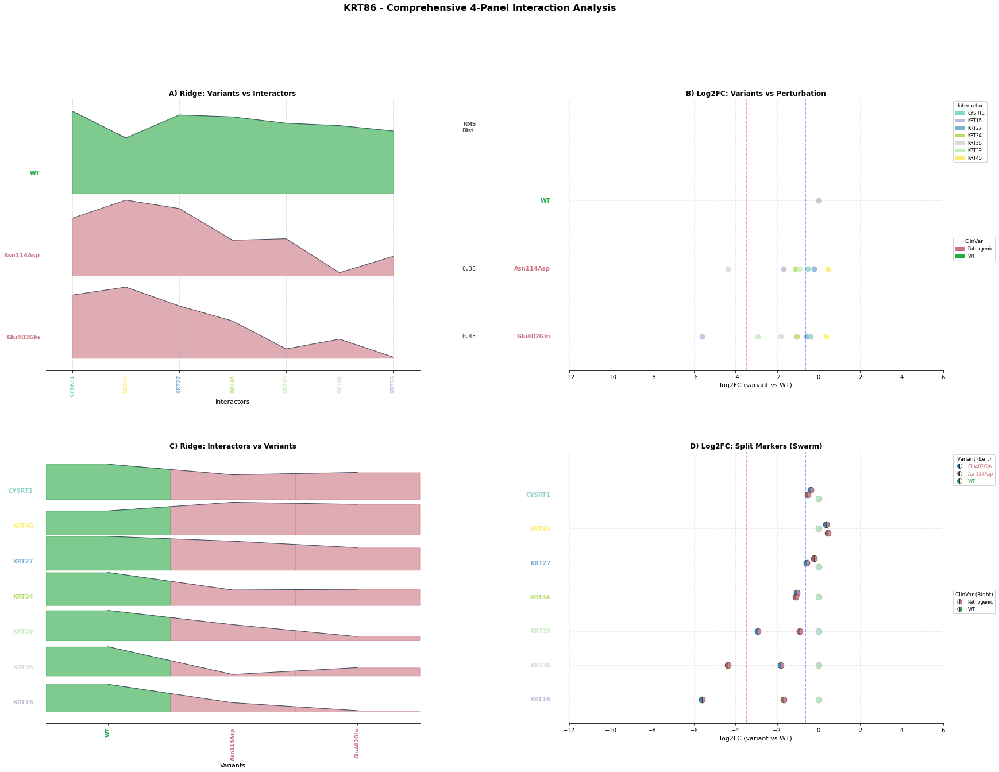


Processing: LDHB
Creating 4-panel plot for LDHB


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/LDHB_four_panels.pdf


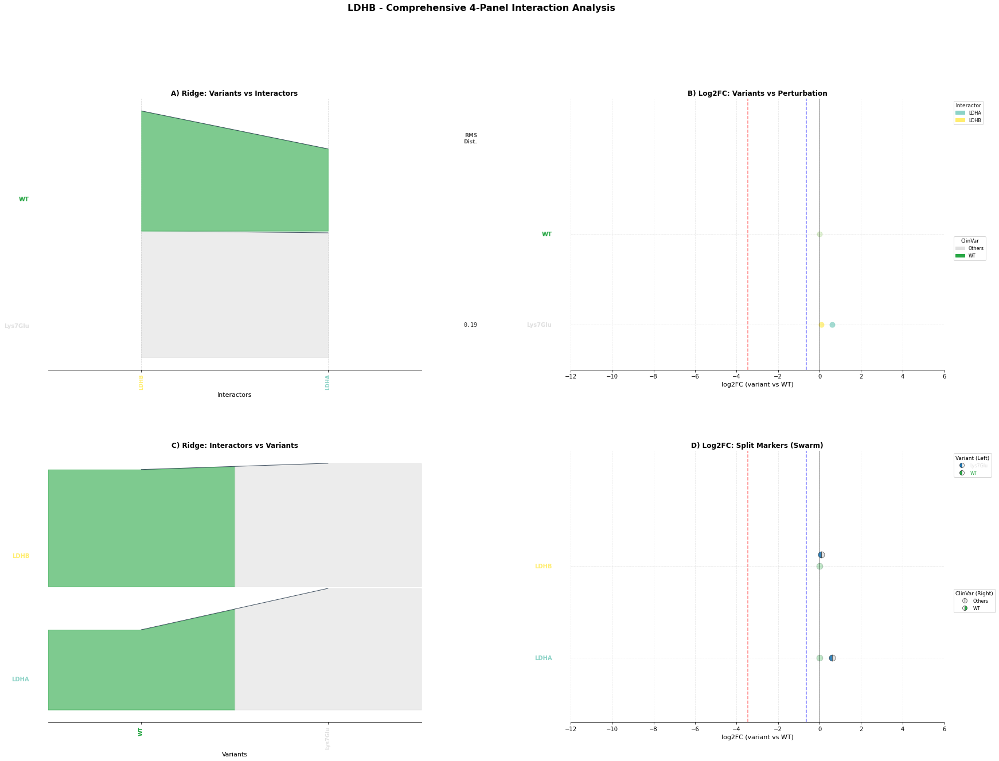


Processing: LITAF
Creating 4-panel plot for LITAF


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/LITAF_four_panels.pdf


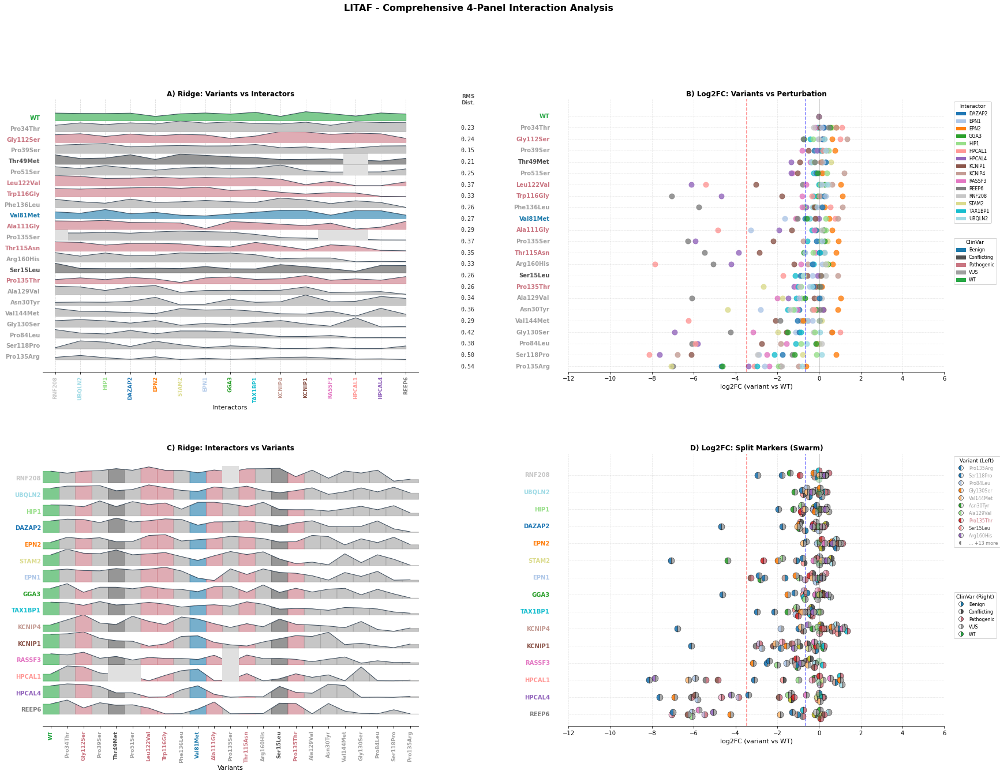


Processing: MLH1
Creating 4-panel plot for MLH1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/MLH1_four_panels.pdf


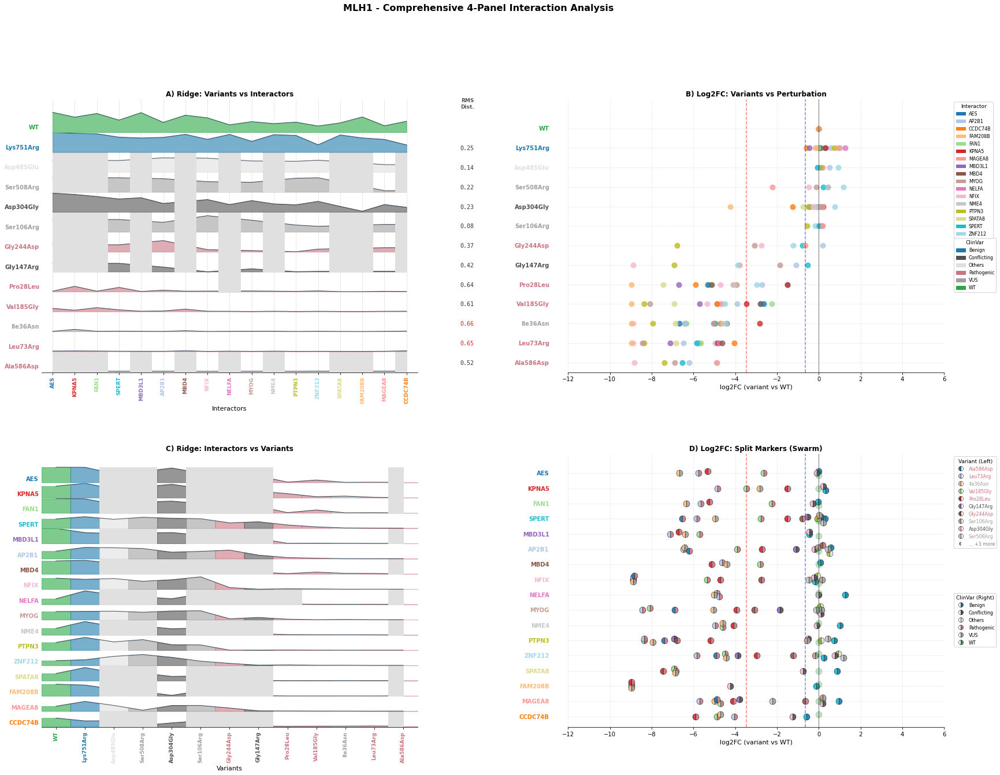


Processing: MVK
Creating 4-panel plot for MVK
Saved: ../3_outputs/sqY2H/four_panel_plots/MVK_four_panels.pdf


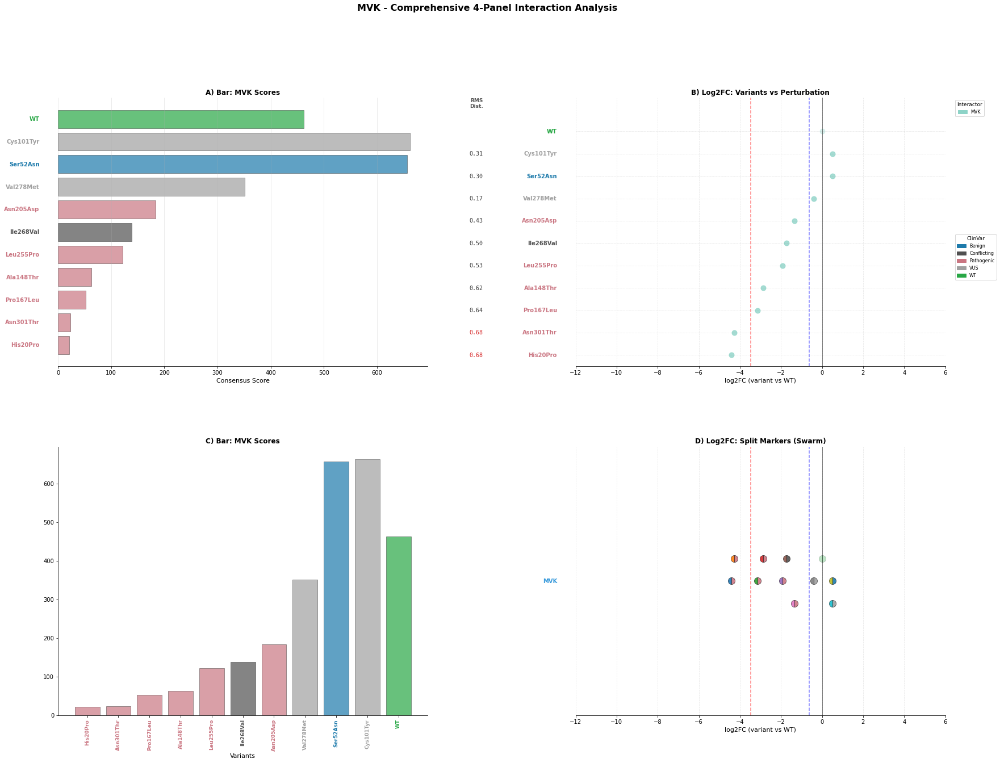


Processing: NAA10
Creating 4-panel plot for NAA10


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/NAA10_four_panels.pdf


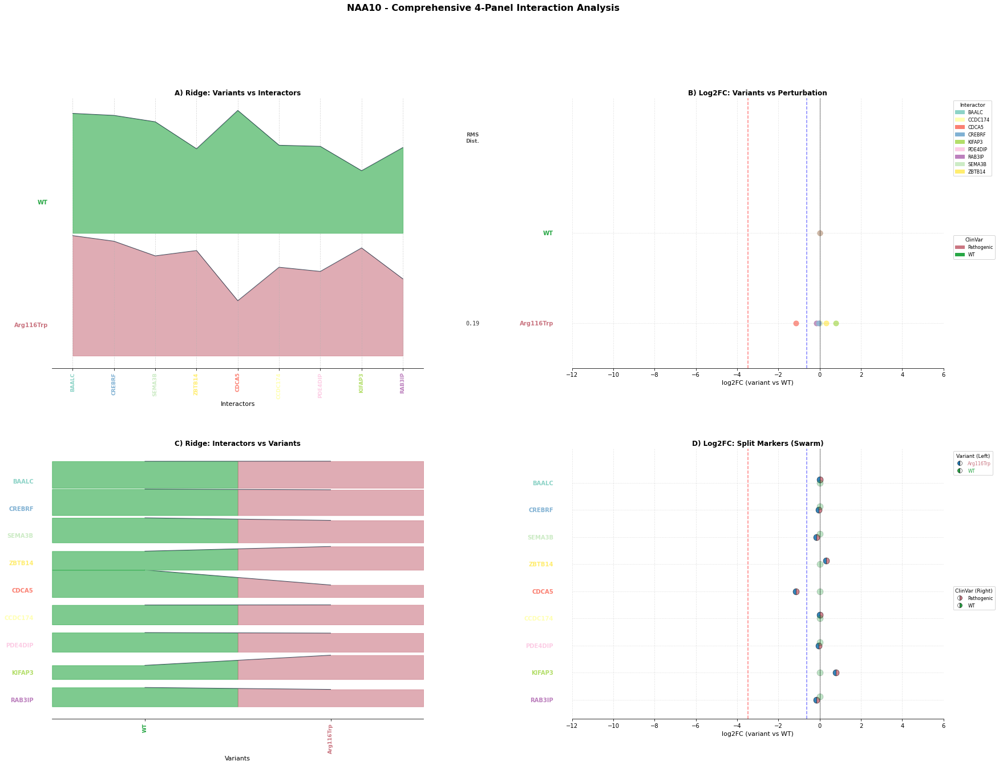


Processing: NCF2
Creating 4-panel plot for NCF2
Saved: ../3_outputs/sqY2H/four_panel_plots/NCF2_four_panels.pdf


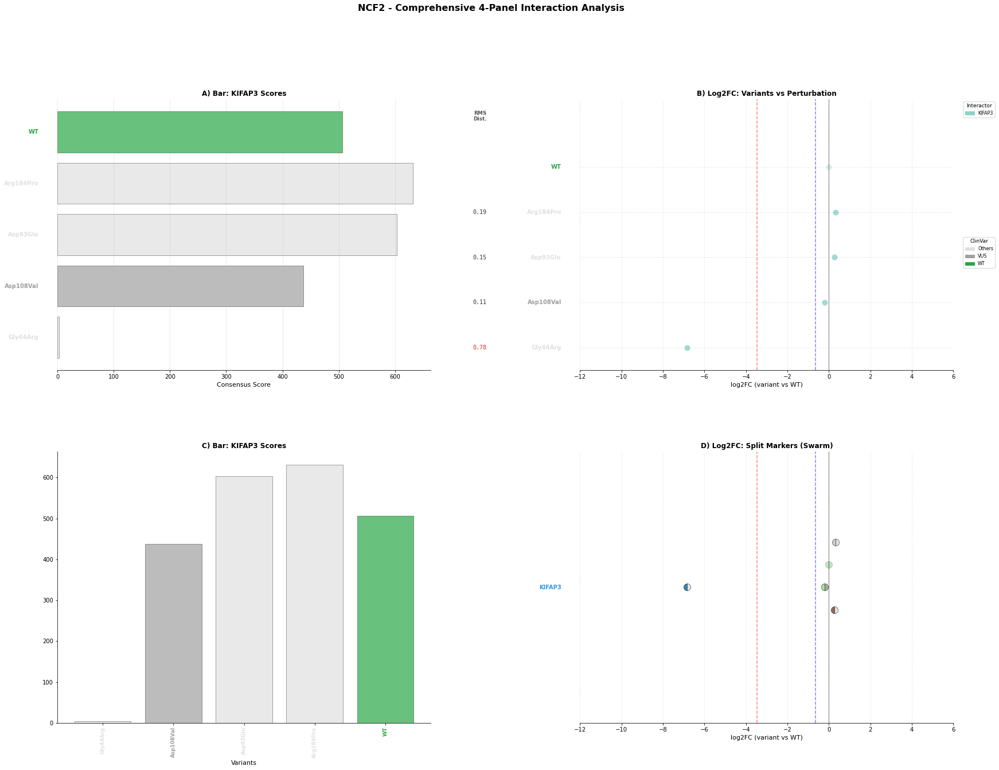


Processing: NEUROG3
Creating 4-panel plot for NEUROG3


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/NEUROG3_four_panels.pdf


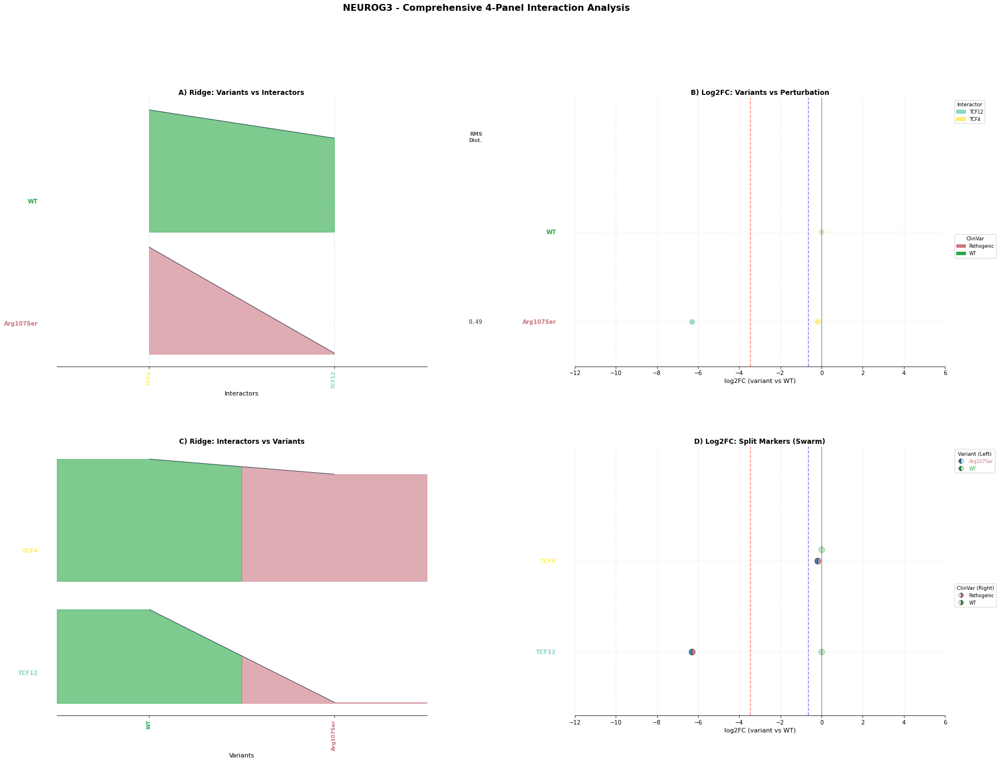


Processing: NMNAT1
Creating 4-panel plot for NMNAT1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/NMNAT1_four_panels.pdf


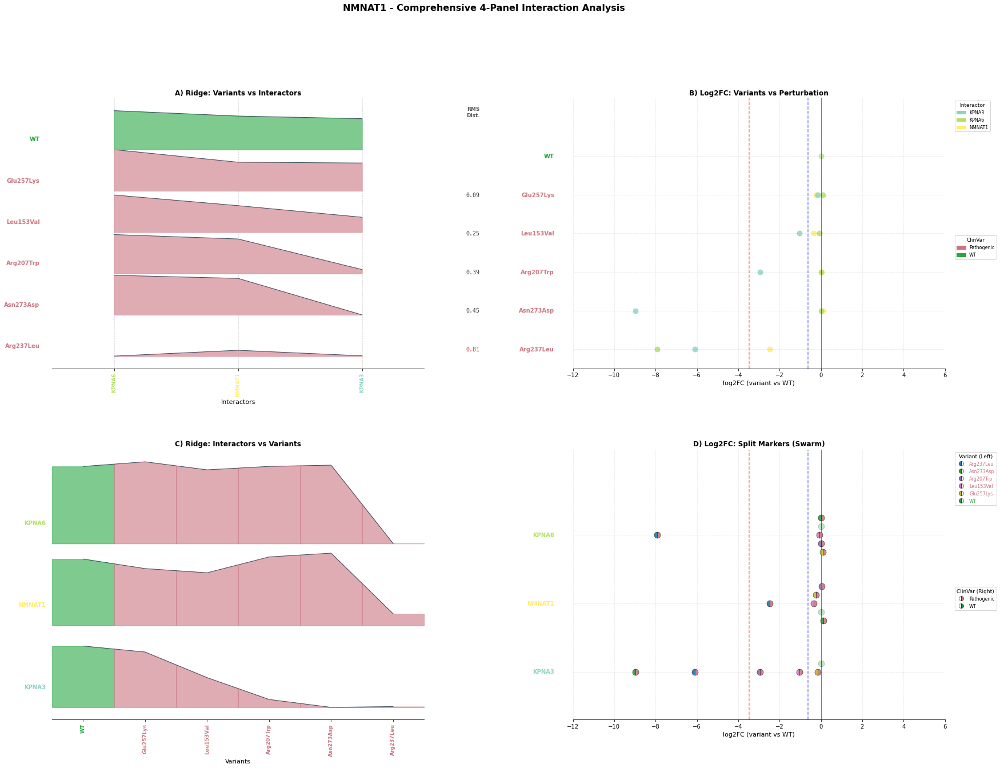


Processing: NR0B1
Creating 4-panel plot for NR0B1
Saved: ../3_outputs/sqY2H/four_panel_plots/NR0B1_four_panels.pdf


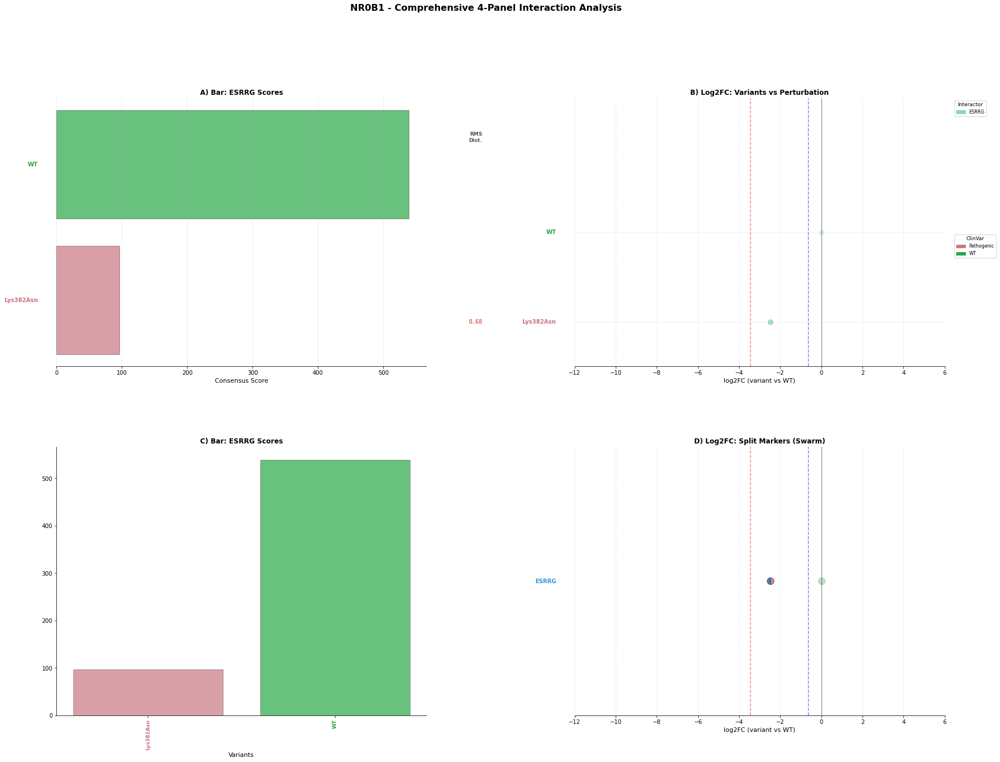


Processing: PCCA
Creating 4-panel plot for PCCA
Saved: ../3_outputs/sqY2H/four_panel_plots/PCCA_four_panels.pdf


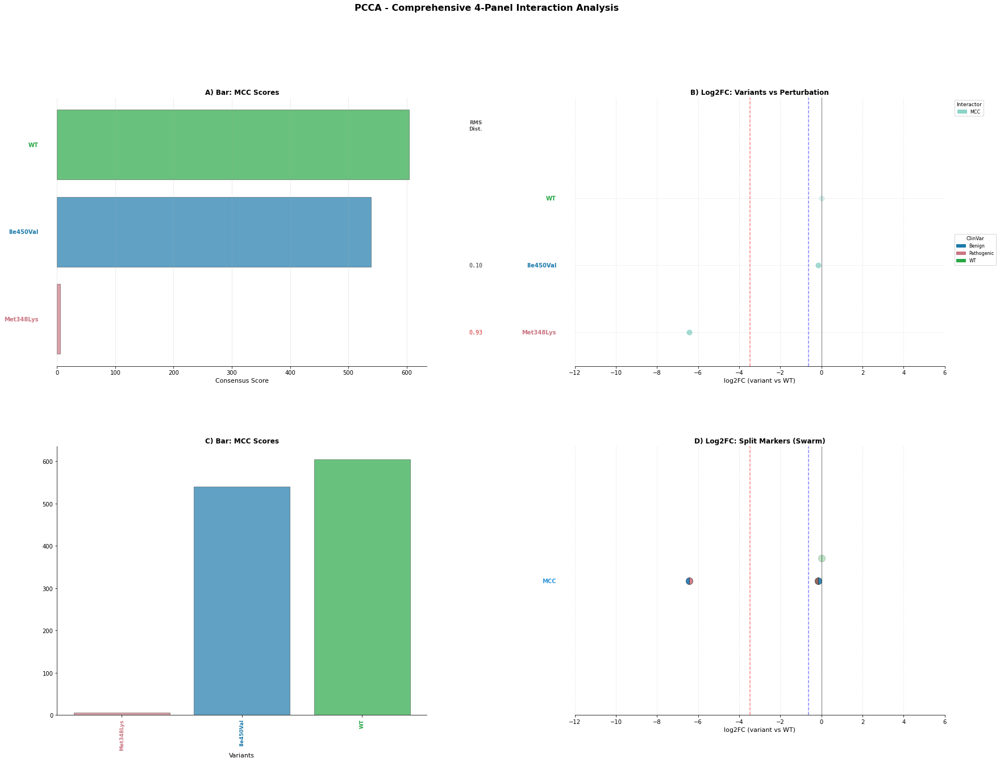


Processing: PITX2
Creating 4-panel plot for PITX2
Saved: ../3_outputs/sqY2H/four_panel_plots/PITX2_four_panels.pdf


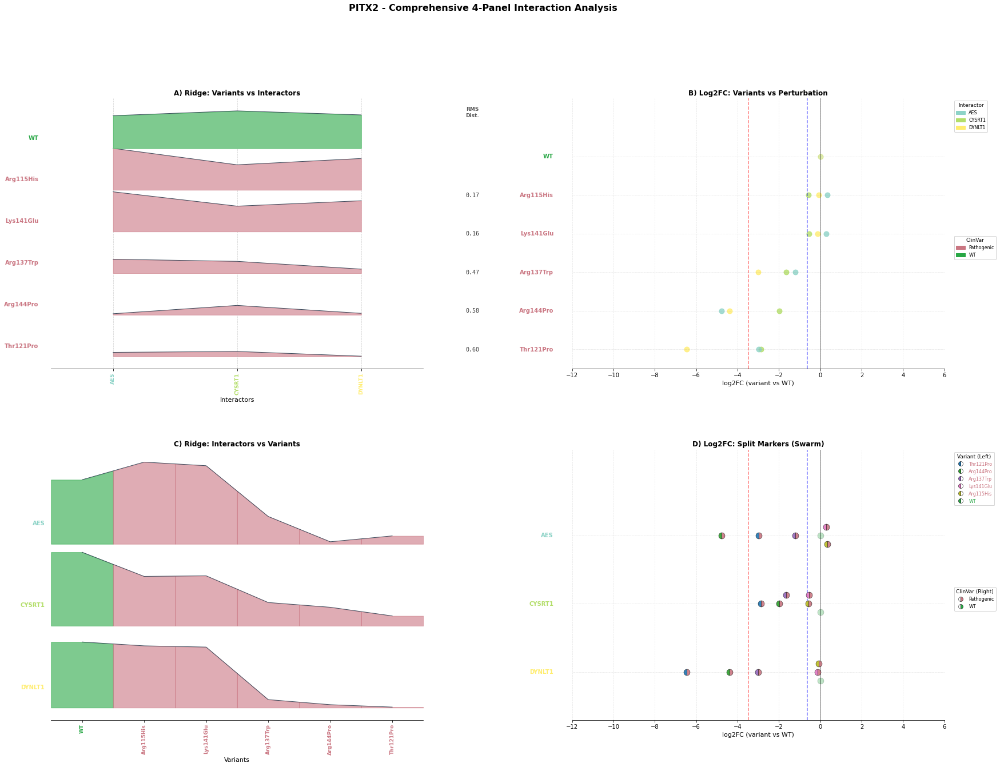


Processing: PKP2
Creating 4-panel plot for PKP2
Saved: ../3_outputs/sqY2H/four_panel_plots/PKP2_four_panels.pdf


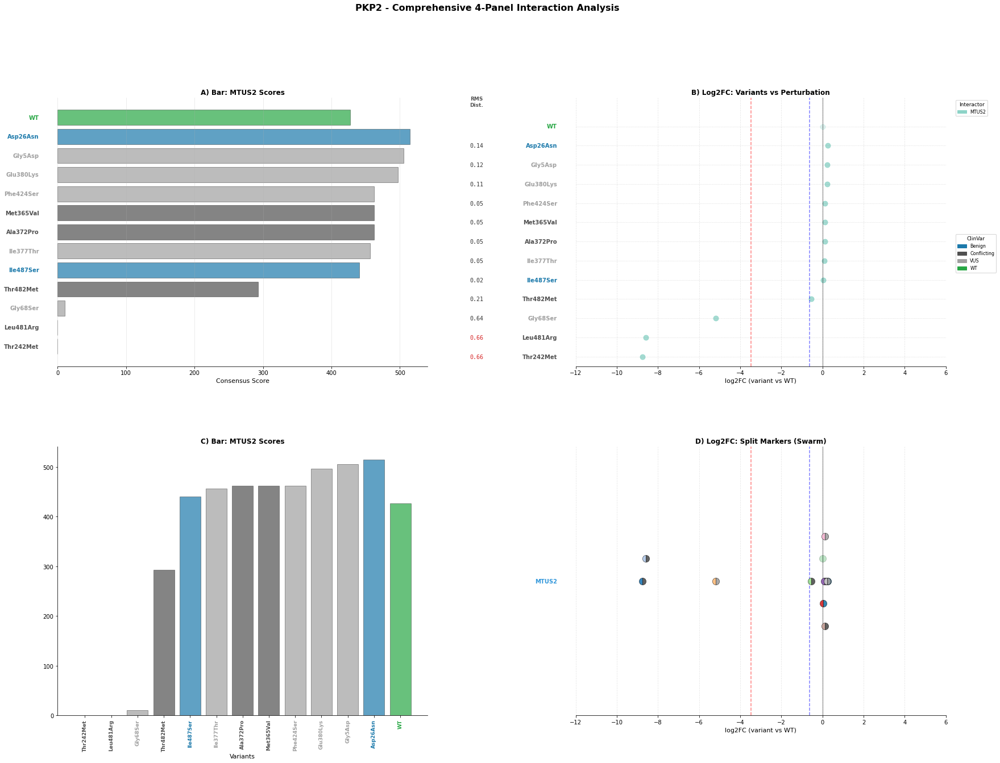


Processing: PLP1
Creating 4-panel plot for PLP1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/PLP1_four_panels.pdf


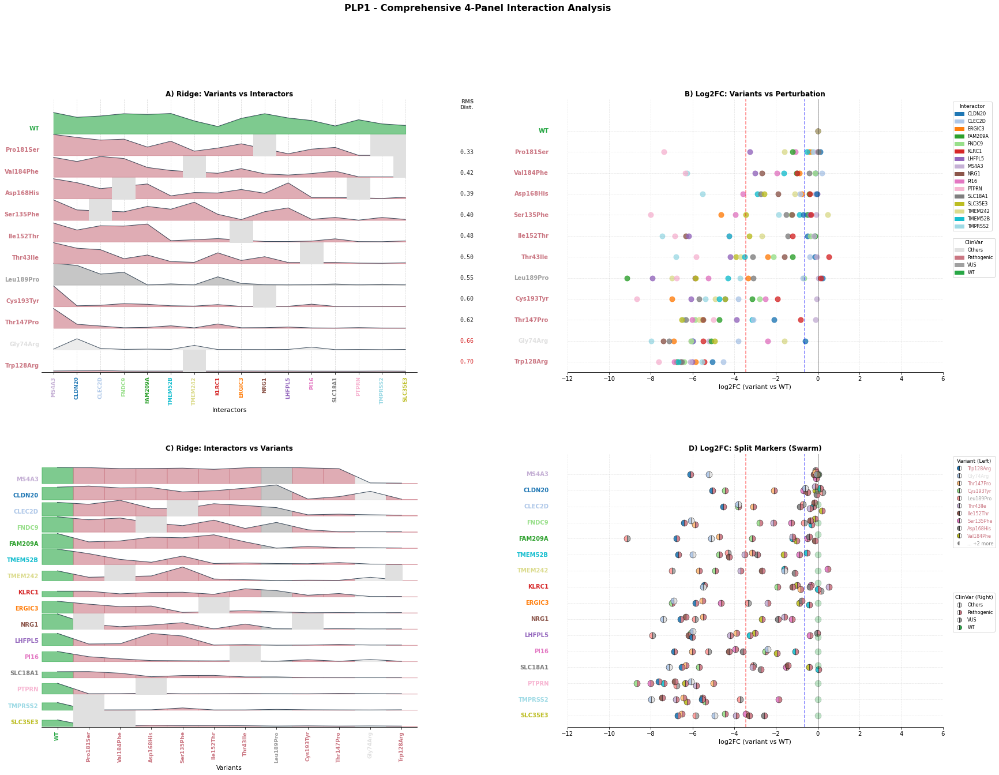


Processing: PMP22
Creating 4-panel plot for PMP22


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/PMP22_four_panels.pdf


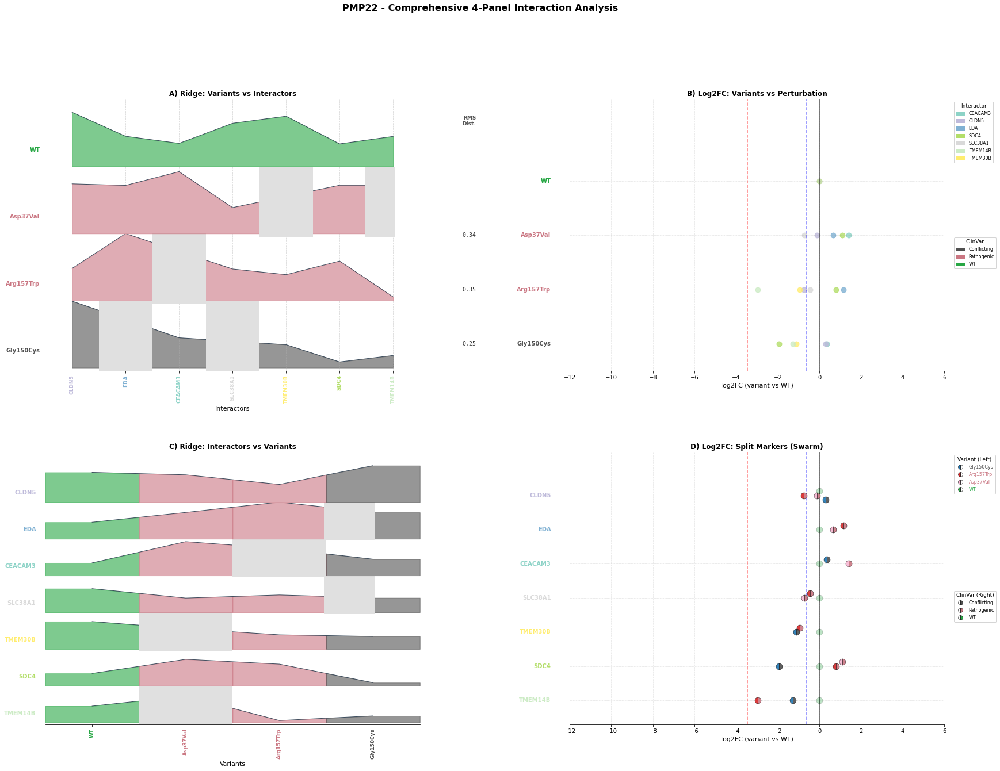


Processing: PNKP
Creating 4-panel plot for PNKP


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/PNKP_four_panels.pdf


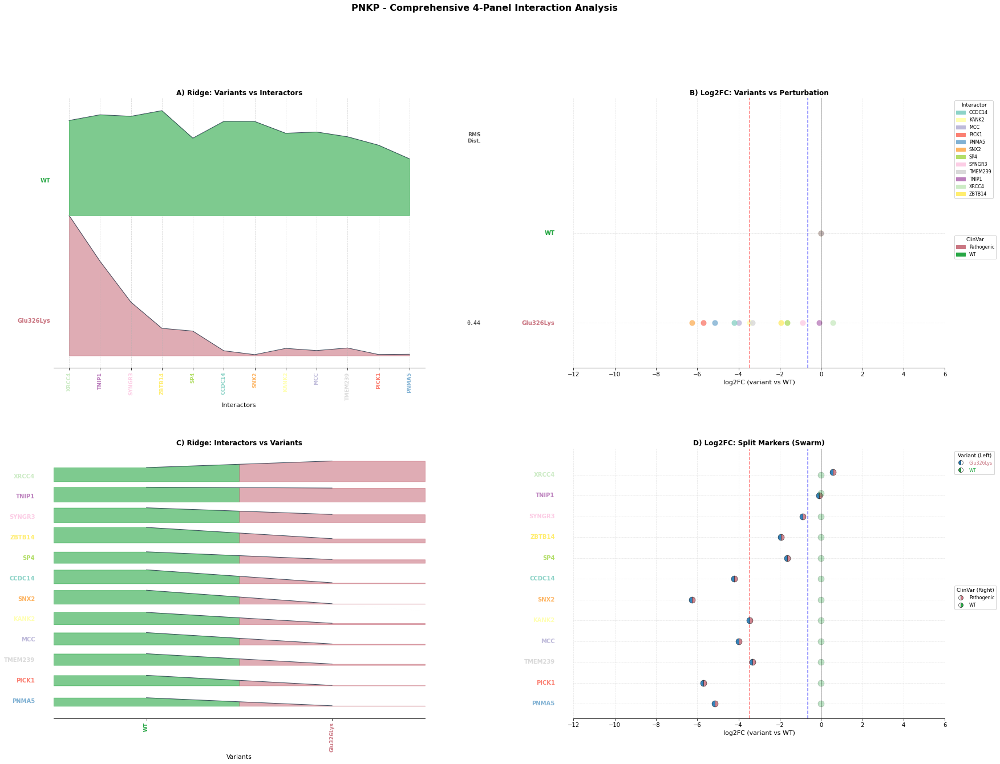


Processing: PRKAR1A
Creating 4-panel plot for PRKAR1A


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/PRKAR1A_four_panels.pdf


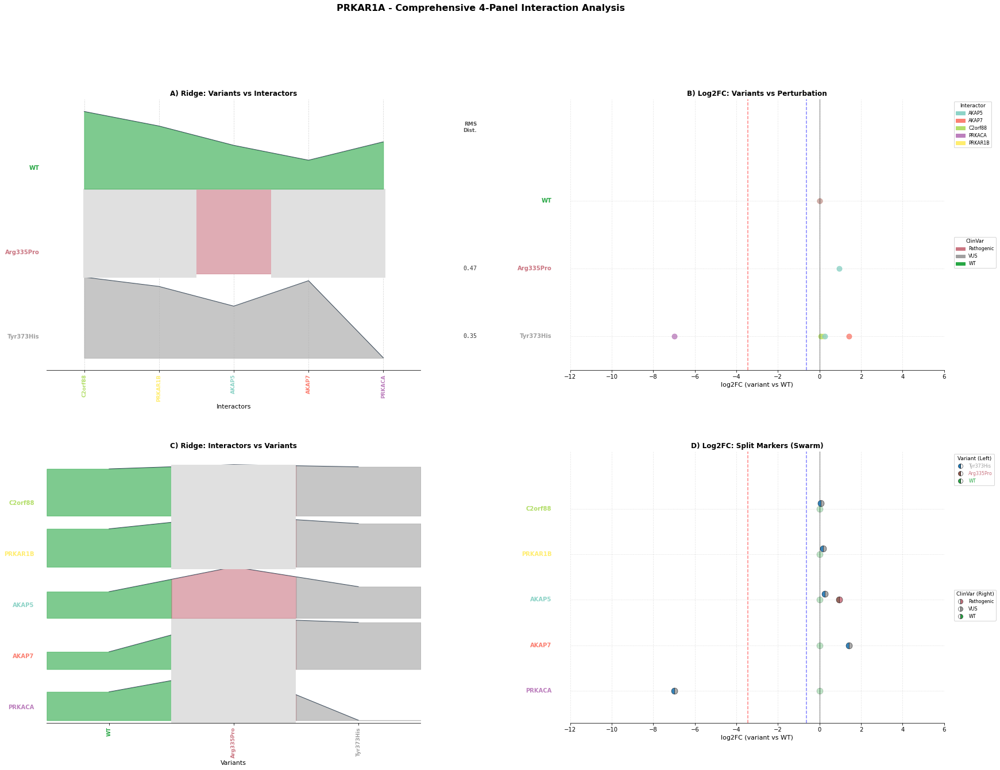


Processing: PRPS1
Creating 4-panel plot for PRPS1
Saved: ../3_outputs/sqY2H/four_panel_plots/PRPS1_four_panels.pdf


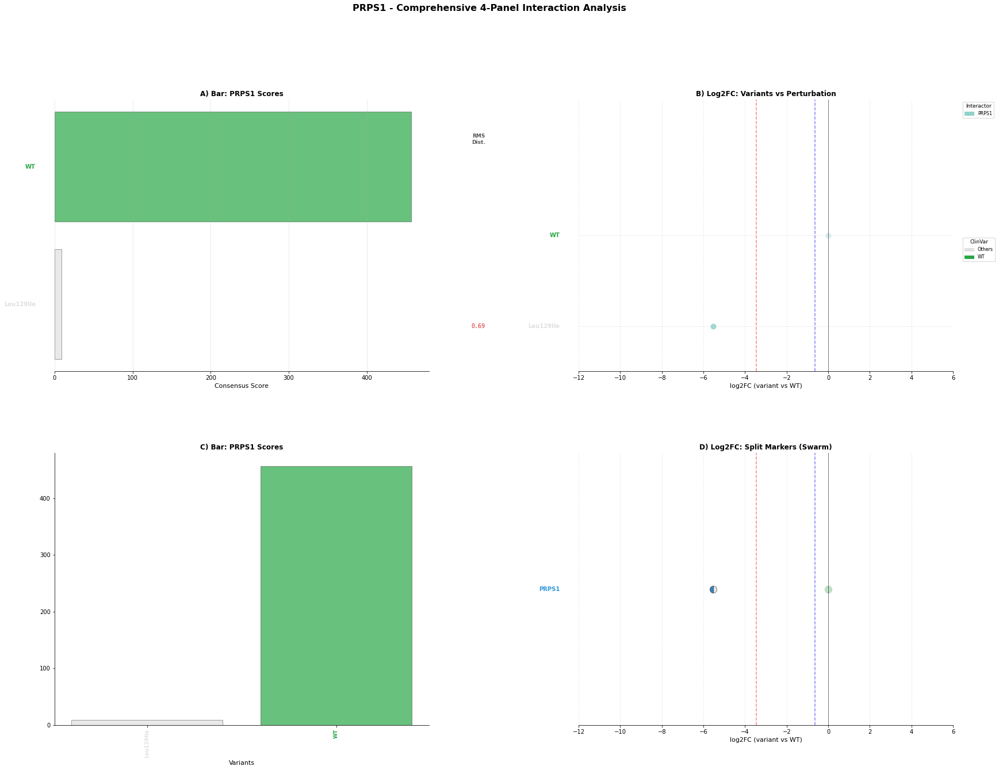


Processing: PTS
Creating 4-panel plot for PTS
Saved: ../3_outputs/sqY2H/four_panel_plots/PTS_four_panels.pdf


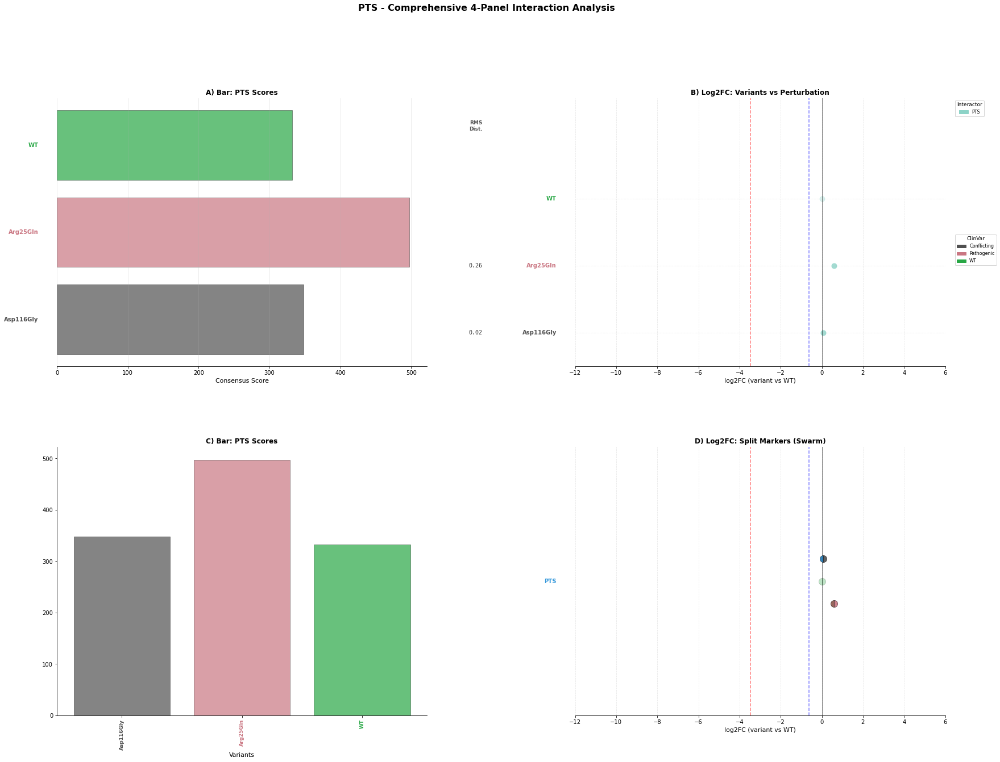


Processing: PYGL
Creating 4-panel plot for PYGL


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/PYGL_four_panels.pdf


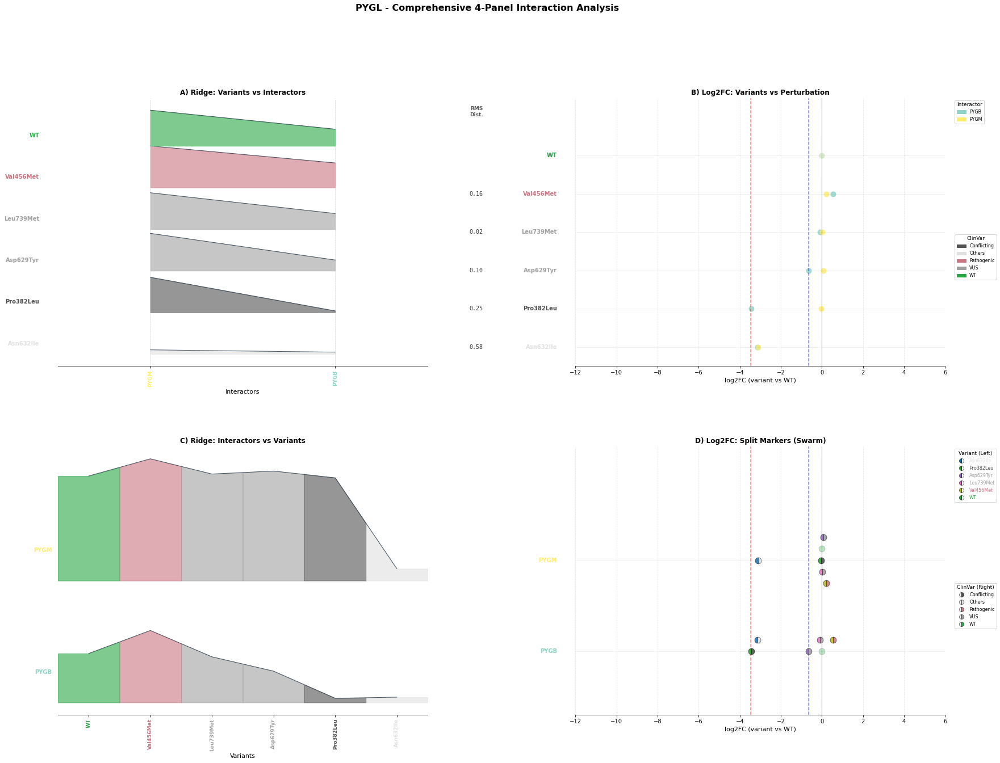


Processing: SFTPC
Creating 4-panel plot for SFTPC


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/SFTPC_four_panels.pdf


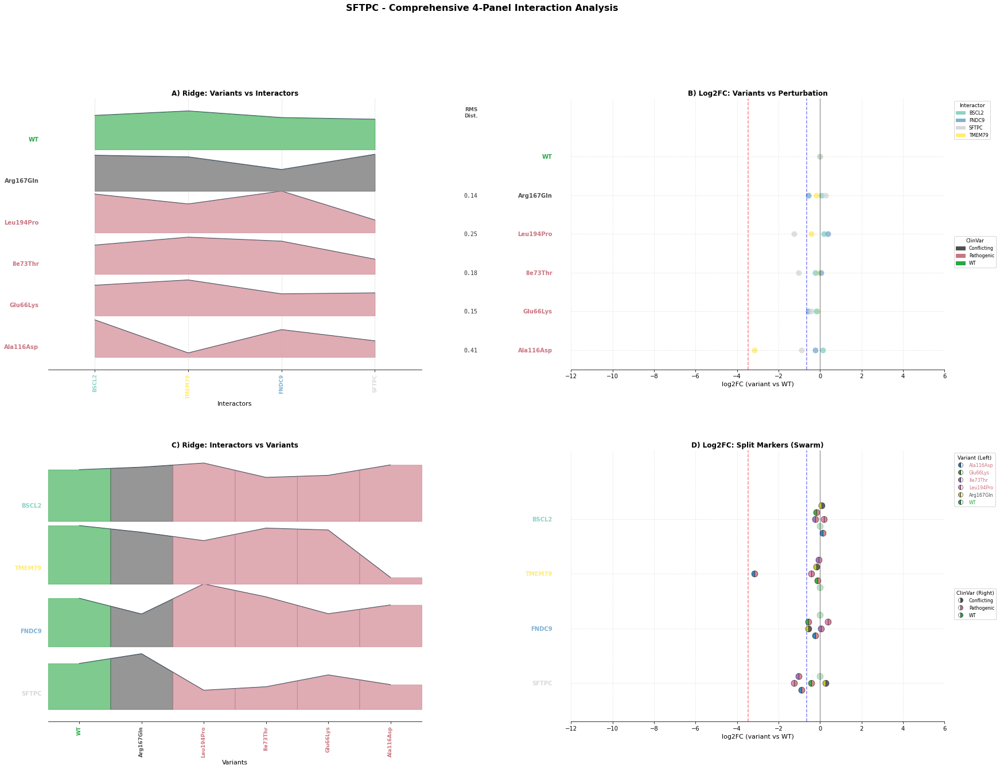


Processing: SH3BP2
Creating 4-panel plot for SH3BP2


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/SH3BP2_four_panels.pdf


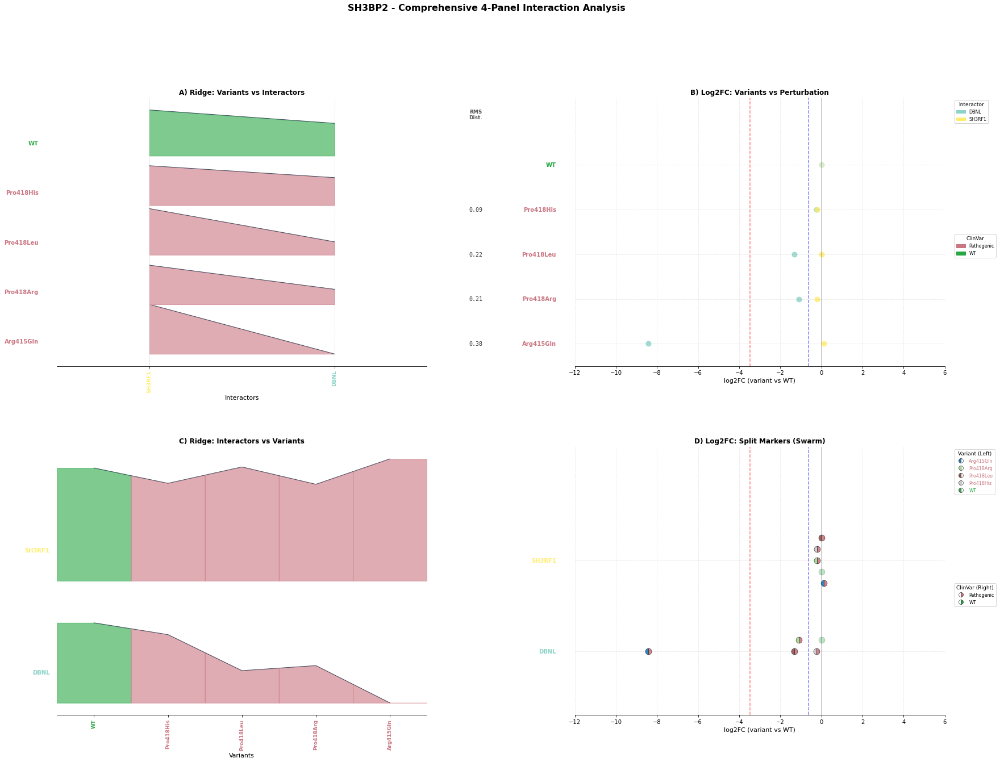


Processing: SIX1
Creating 4-panel plot for SIX1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/SIX1_four_panels.pdf


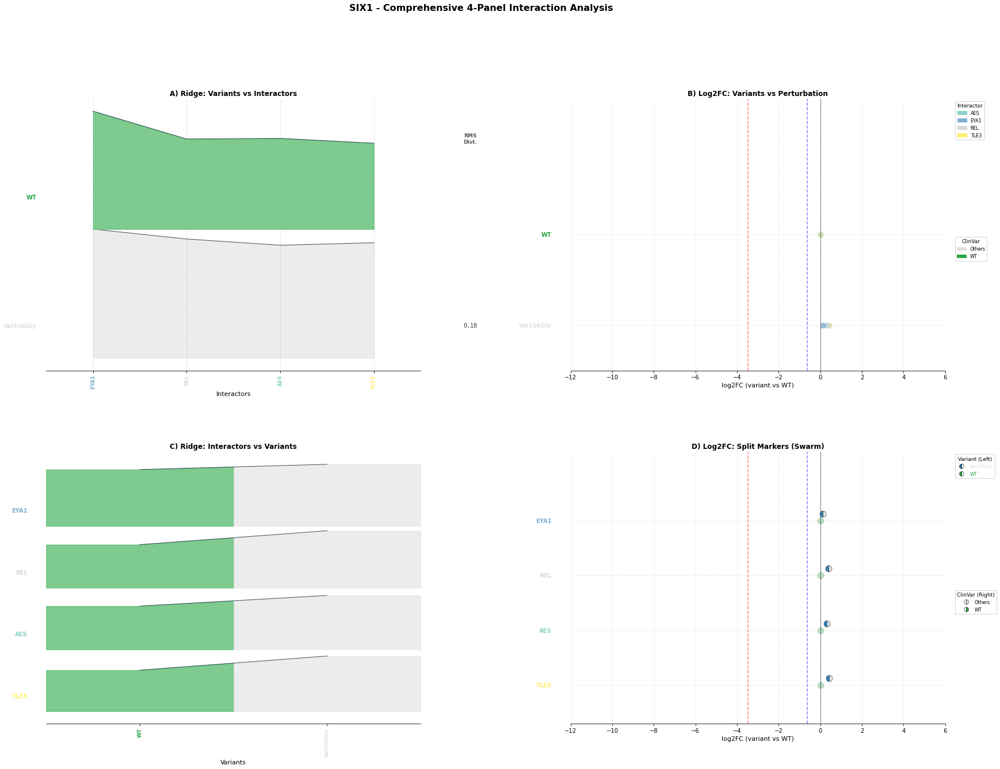


Processing: SMAD3
Creating 4-panel plot for SMAD3


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/SMAD3_four_panels.pdf


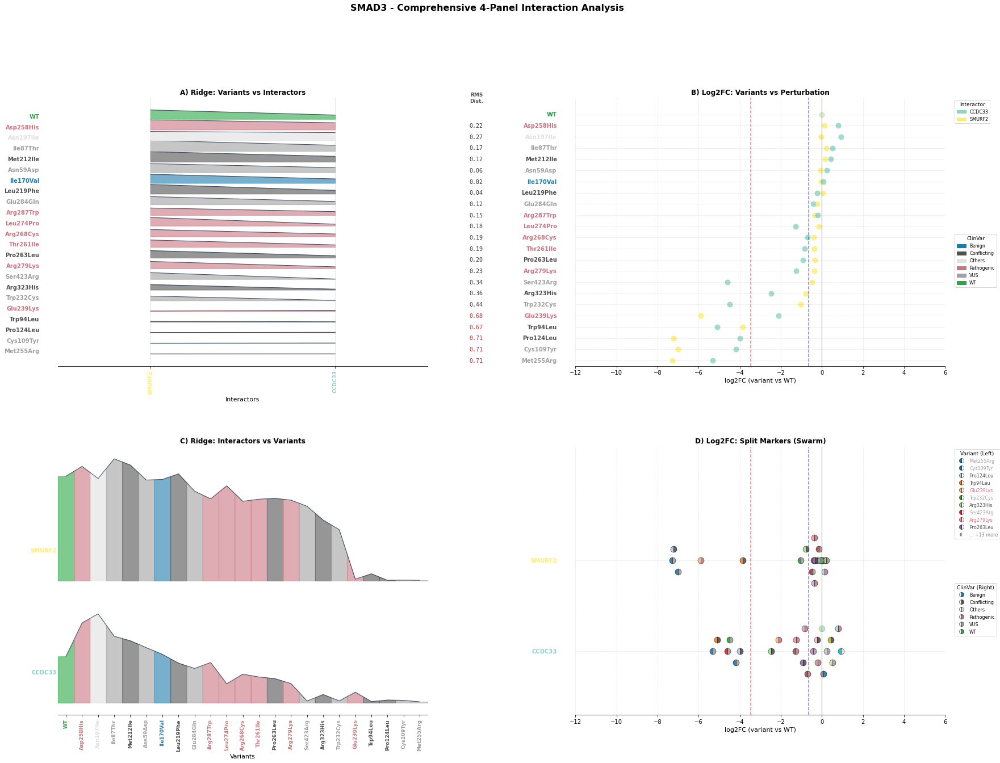


Processing: SMARCB1
Creating 4-panel plot for SMARCB1
Saved: ../3_outputs/sqY2H/four_panel_plots/SMARCB1_four_panels.pdf


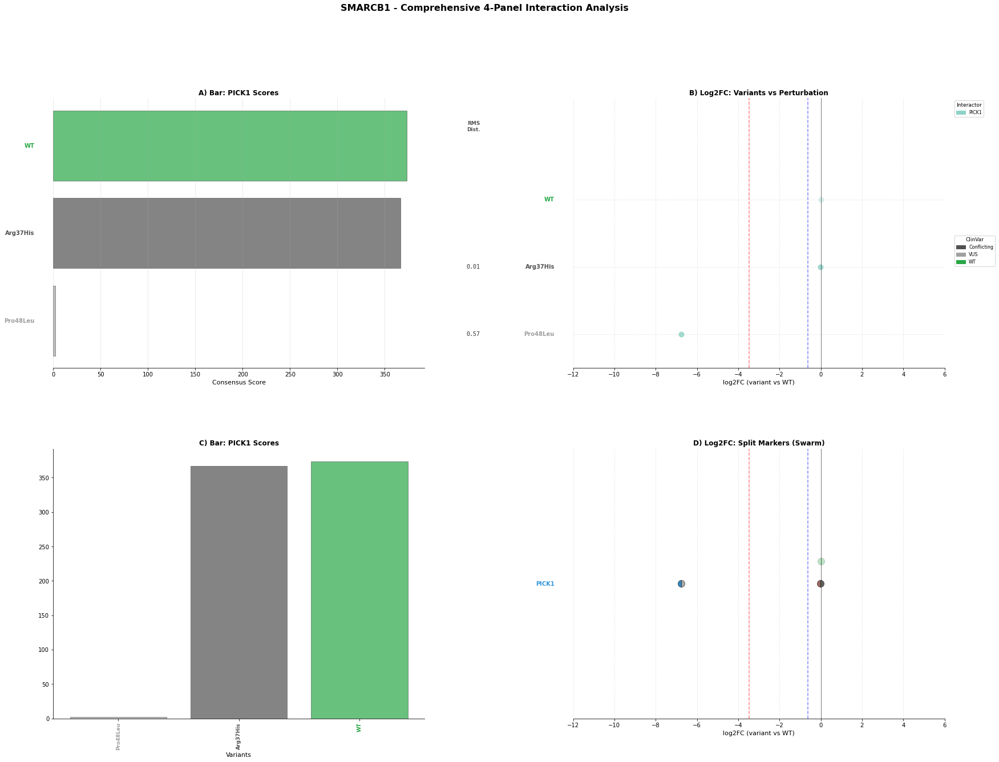


Processing: STAR
Creating 4-panel plot for STAR


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/STAR_four_panels.pdf


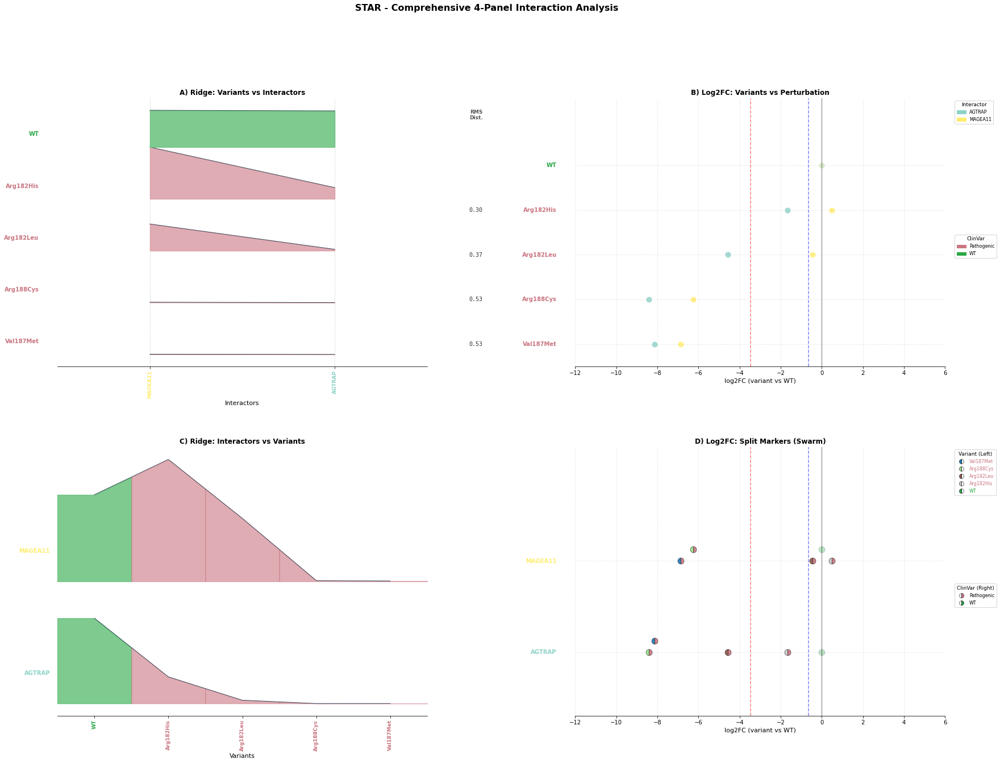


Processing: STXBP1
Creating 4-panel plot for STXBP1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/STXBP1_four_panels.pdf


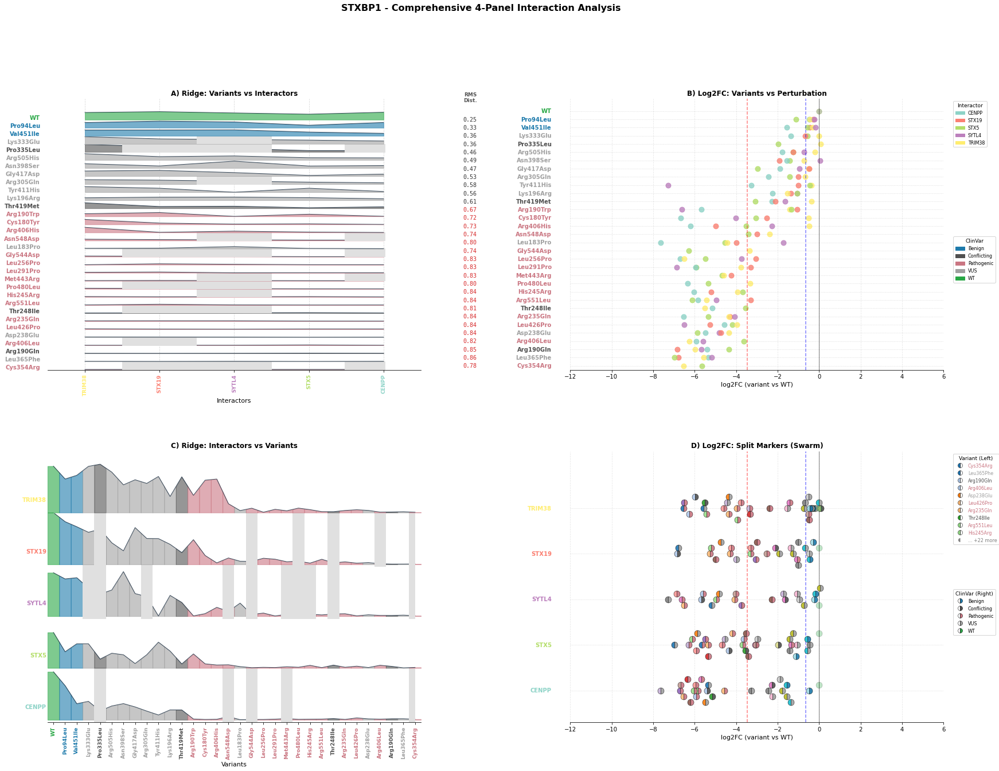


Processing: SUOX
Creating 4-panel plot for SUOX


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/SUOX_four_panels.pdf


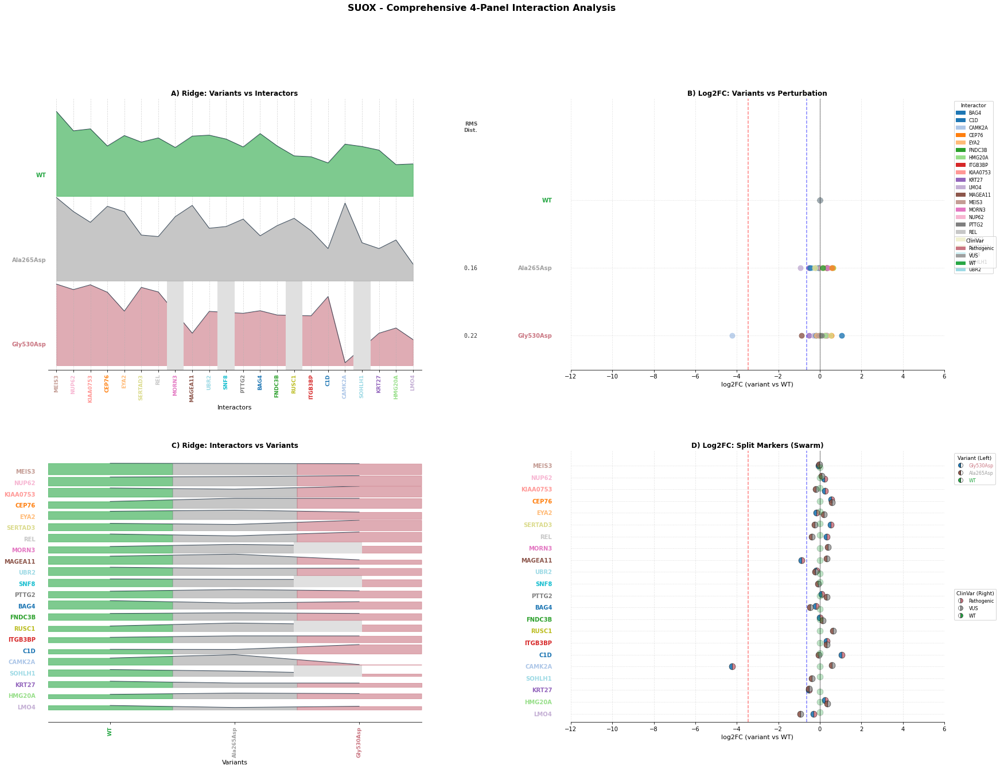


Processing: TH
Creating 4-panel plot for TH


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/TH_four_panels.pdf


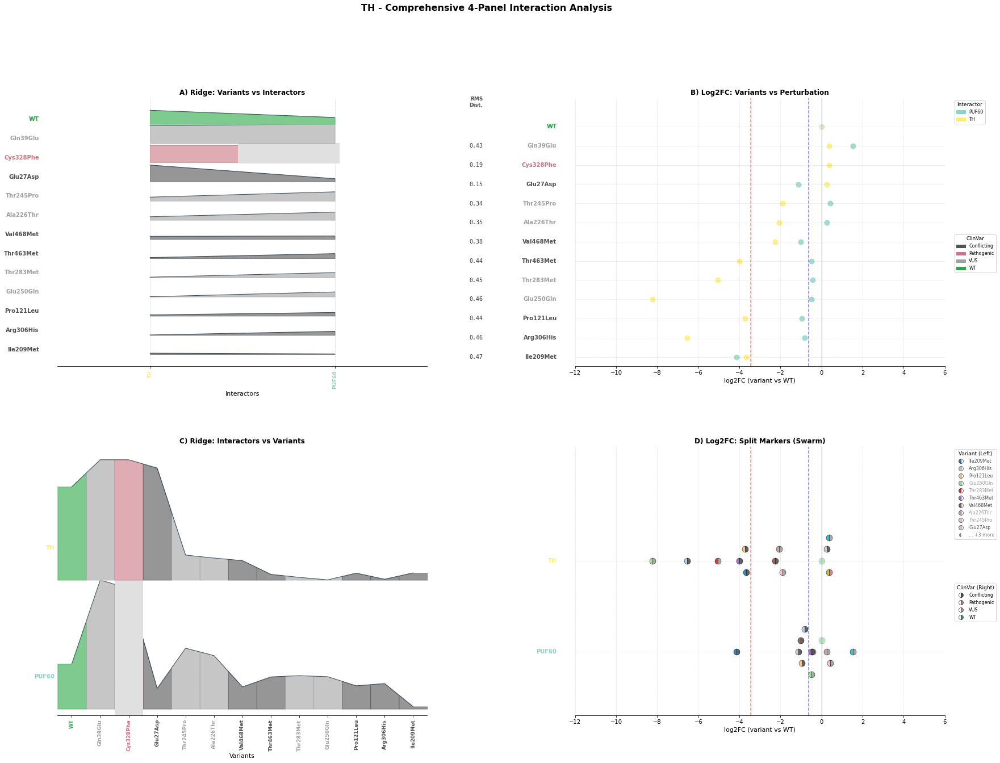


Processing: THAP1
Creating 4-panel plot for THAP1


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/THAP1_four_panels.pdf


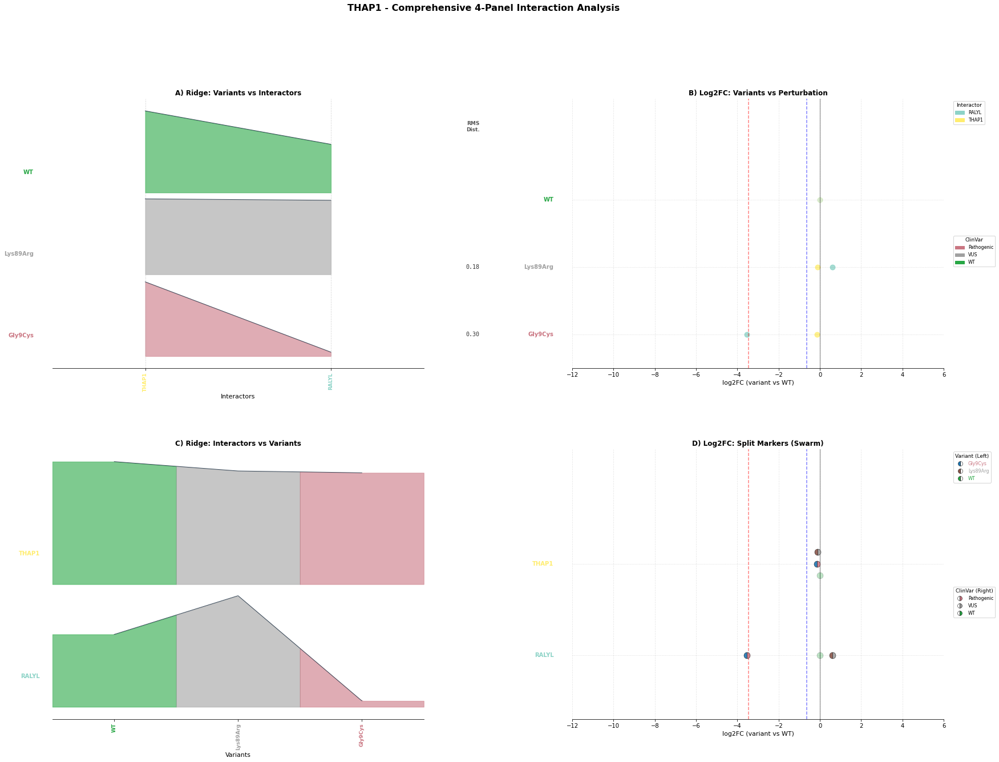


Processing: TMEM43
Creating 4-panel plot for TMEM43
Saved: ../3_outputs/sqY2H/four_panel_plots/TMEM43_four_panels.pdf


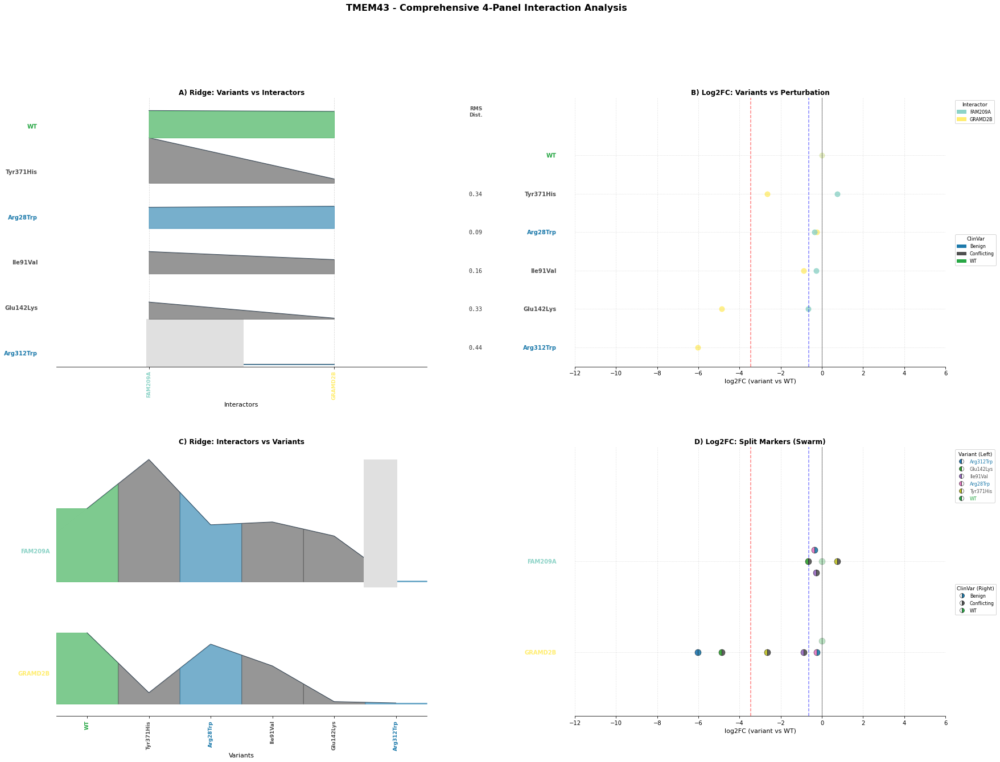


Processing: TPK1
Creating 4-panel plot for TPK1
Saved: ../3_outputs/sqY2H/four_panel_plots/TPK1_four_panels.pdf


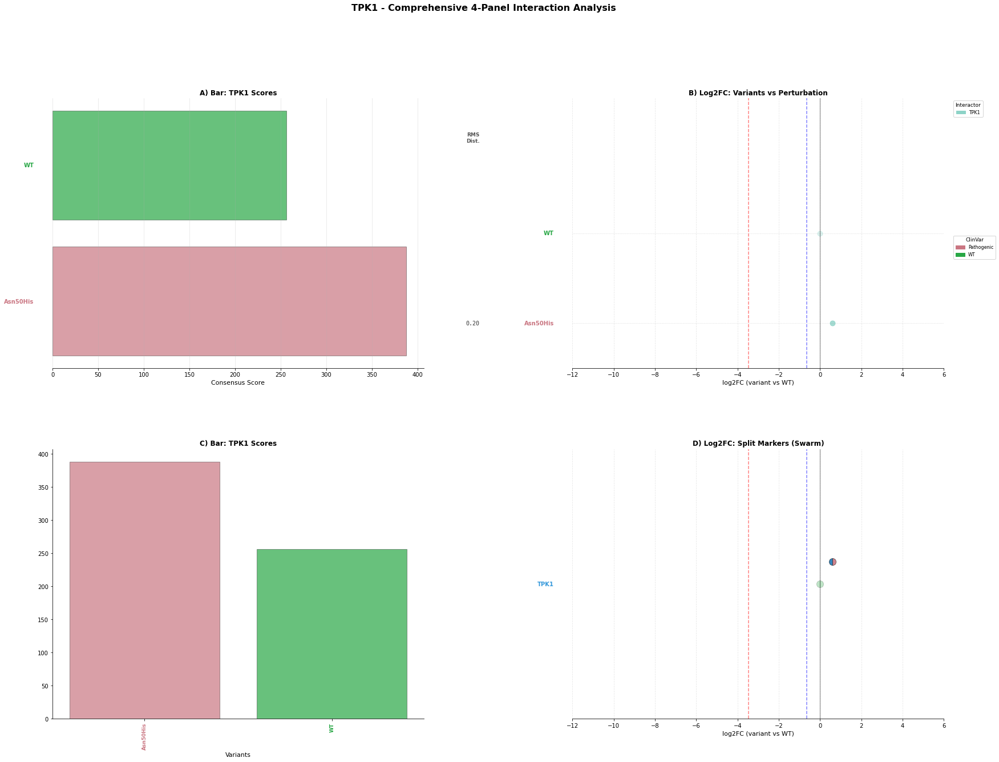


Processing: TPM1
Creating 4-panel plot for TPM1
Saved: ../3_outputs/sqY2H/four_panel_plots/TPM1_four_panels.pdf


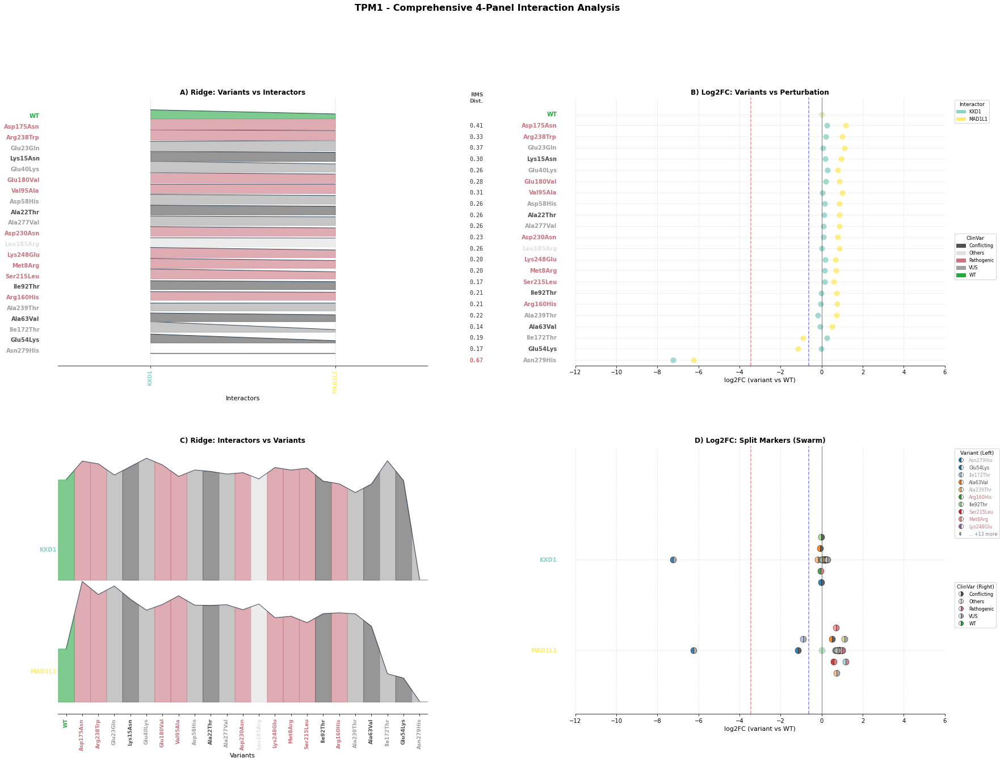


Processing: TTR
Creating 4-panel plot for TTR
Saved: ../3_outputs/sqY2H/four_panel_plots/TTR_four_panels.pdf


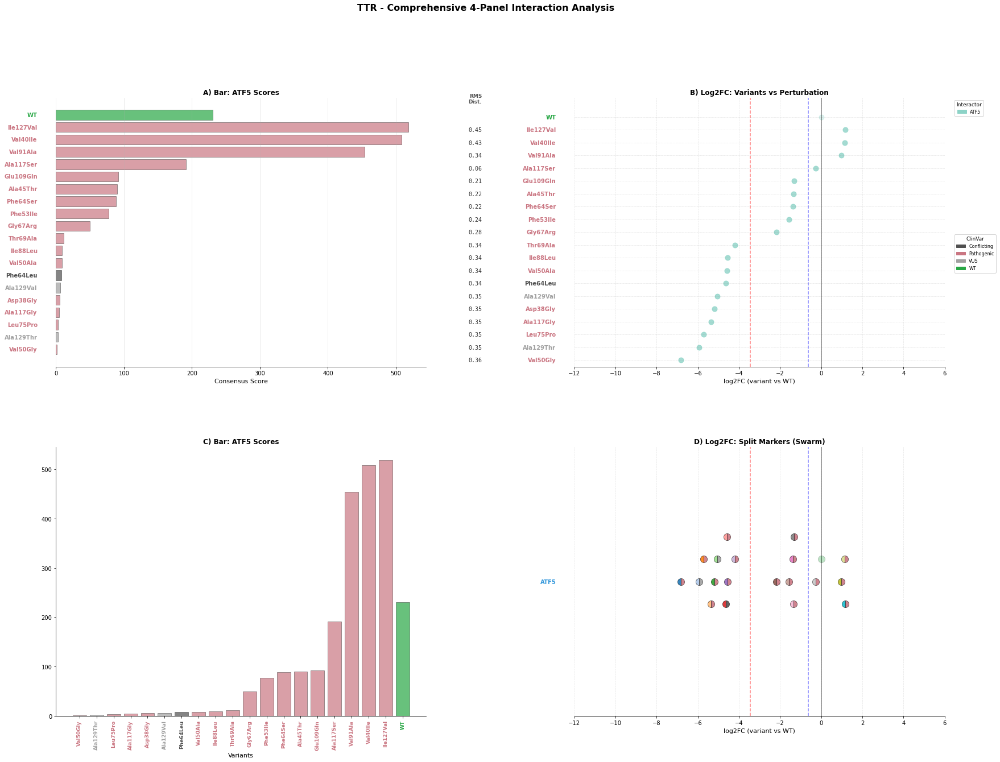


Processing: UBQLN2
Creating 4-panel plot for UBQLN2


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_75651/2997830354.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pivot_raw_ordered['mean_signal'] = pivot_raw_ordered.mean(axis=1)


Saved: ../3_outputs/sqY2H/four_panel_plots/UBQLN2_four_panels.pdf


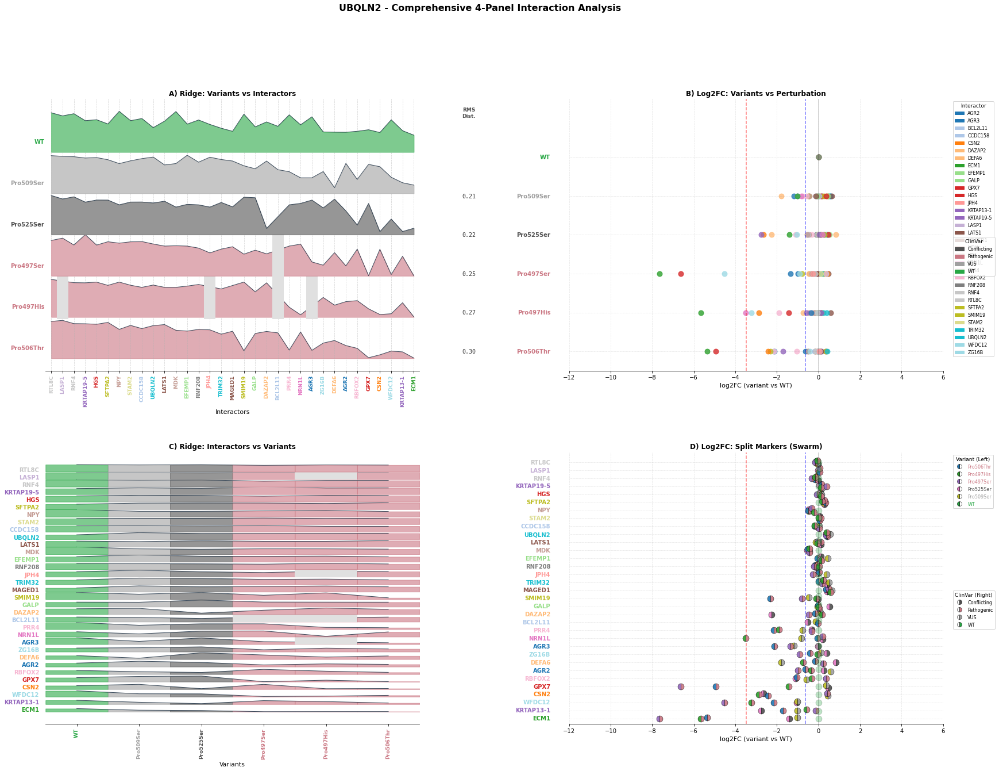


Processing: UROD
Creating 4-panel plot for UROD
Saved: ../3_outputs/sqY2H/four_panel_plots/UROD_four_panels.pdf


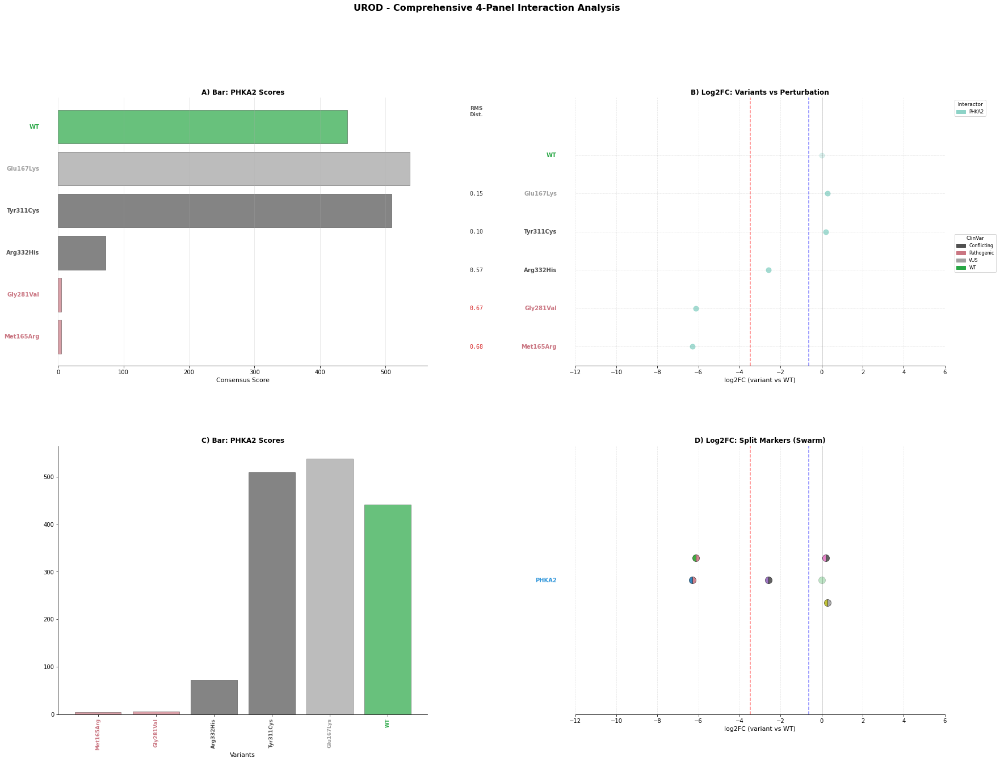


Processing: VHL
Creating 4-panel plot for VHL
Saved: ../3_outputs/sqY2H/four_panel_plots/VHL_four_panels.pdf


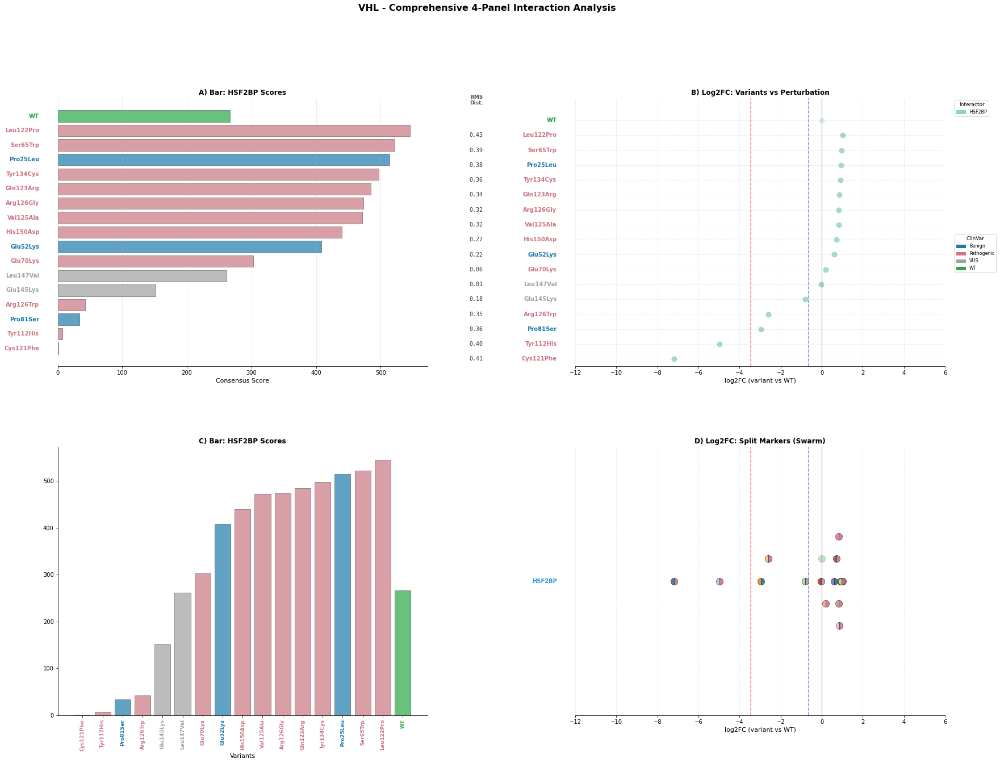


Processing: ZMYND10
Creating 4-panel plot for ZMYND10
Saved: ../3_outputs/sqY2H/four_panel_plots/ZMYND10_four_panels.pdf


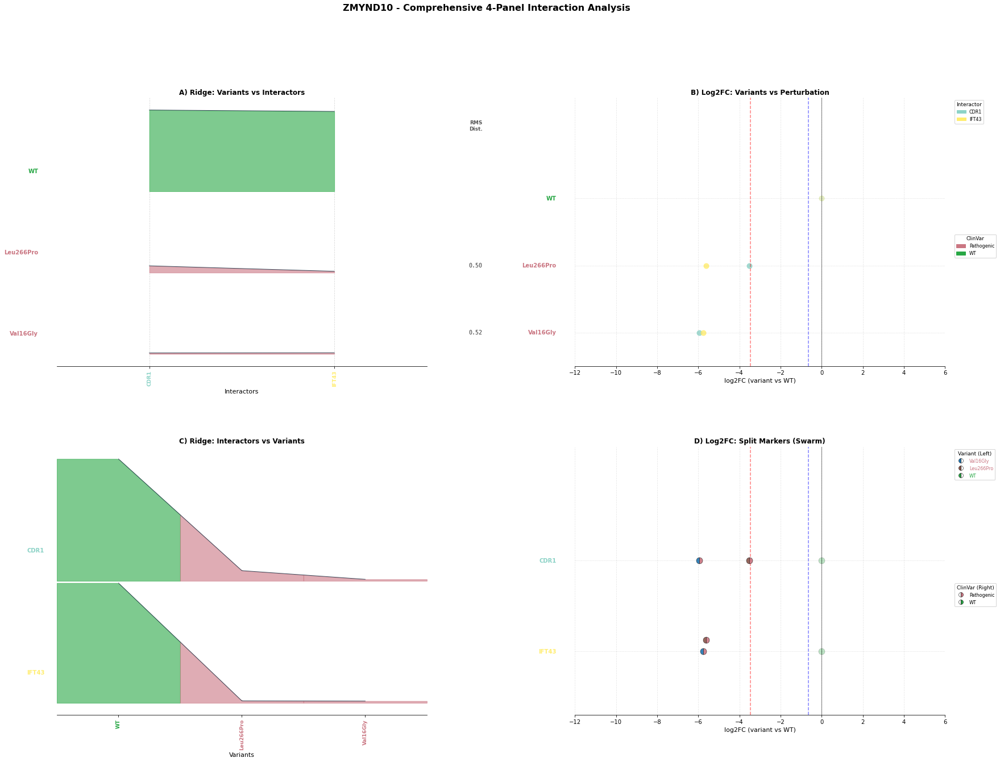


Completed: 75 four-panel plots generated as PDF


In [18]:
# ==========================================
# Usage
# ==========================================

# Generate all four-panel plots
all_four_panel_plots = plot_all_genes_four_panels(
    edge_df=edge_df,
    palette_dict=palette_dict,
    output_dir=f"{outputs_dir}/four_panel_plots",
    file_format='pdf'
)